    ### 1. Distribución de Happiness Score

En este bloque se analizará la distribución de la puntuación de felicidad
(Happiness Score) para cada año, utilizando estadísticas descriptivas
y visualizaciones que permitan identificar su comportamiento y dispersión.

In [98]:
# ============================================================
# 1. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN
# ============================================================

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# Directorio raíz del proyecto
PROJECT_ROOT = Path.cwd().parent

# Directorio de archivos originales
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Años disponibles
YEARS = [2015, 2016, 2017, 2018, 2019]

# Configuración visual
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

print("Directorio de datos:", RAW_DIR)
print("Archivos encontrados:", len(list(RAW_DIR.glob("*.csv"))))

Directorio de datos: c:\Users\Monica\Desktop\ETL\Workshop3\data\raw
Archivos encontrados: 5


### 1.2. Carga de datasets

Se cargarán los cinco archivos originales y se extraerá la columna
Happiness Score, normalizando sus nombres para facilitar el análisis.
Los archivos originales permanecerán sin modificaciones.

In [99]:
# ============================================================
# 2. CARGA DE DATASETS
# ============================================================

datasets = {}

COLUMNAS_SCORE = {
    2015: "Happiness Score",
    2016: "Happiness Score",
    2017: "Happiness.Score",
    2018: "Score",
    2019: "Score"
}

for year in YEARS:

    archivo = RAW_DIR / f"{year}.csv"

    if not archivo.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {archivo}")

    df = pd.read_csv(archivo, na_values=["N/A", "NA", "n/a", "na", "NULL", "null", ""])

    columna_score = COLUMNAS_SCORE[year]

    if columna_score not in df.columns:
        raise ValueError(
            f"No se encontró la columna {columna_score} en el archivo {year}"
        )

    datasets[year] = df

    print(f"{year}: {df.shape[0]} registros cargados")

print("\nCarga completada.")

2015: 158 registros cargados
2016: 157 registros cargados
2017: 155 registros cargados
2018: 156 registros cargados
2019: 156 registros cargados

Carga completada.


### 1.3. Estadísticas descriptivas

Se calcularán medidas estadísticas de Happiness Score para cada año,
incluyendo media, mediana, desviación estándar, valores mínimos y máximos,
y cuartiles. Esto permitirá comparar la distribución de las puntuaciones.

In [100]:
# ============================================================
# 3. ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

resumen_score = []

for year, df in datasets.items():

    columna_score = COLUMNAS_SCORE[year]
    score = df[columna_score]

    resumen_score.append({
        "year": year,
        "count": score.count(),
        "mean": score.mean(),
        "median": score.median(),
        "std": score.std(),
        "min": score.min(),
        "q1": score.quantile(0.25),
        "q3": score.quantile(0.75),
        "max": score.max()
    })

df_resumen_score = pd.DataFrame(resumen_score)

df_resumen_score.round(3)

,year,count,mean,median,std,min,q1,q3,max
0,2015,158,5.376,5.232,1.145,2.839,4.526,6.244,7.587
1,2016,157,5.382,5.314,1.142,2.905,4.404,6.269,7.526
2,2017,155,5.354,5.279,1.131,2.693,4.506,6.102,7.537
3,2018,156,5.376,5.378,1.120,2.905,4.454,6.168,7.632
4,2019,156,5.407,5.380,1.113,2.853,4.544,6.184,7.769


### 1.4. Distribución de frecuencias

Se construirán histogramas individuales para observar la frecuencia
de las puntuaciones de felicidad en cada año e identificar la forma
de sus distribuciones.

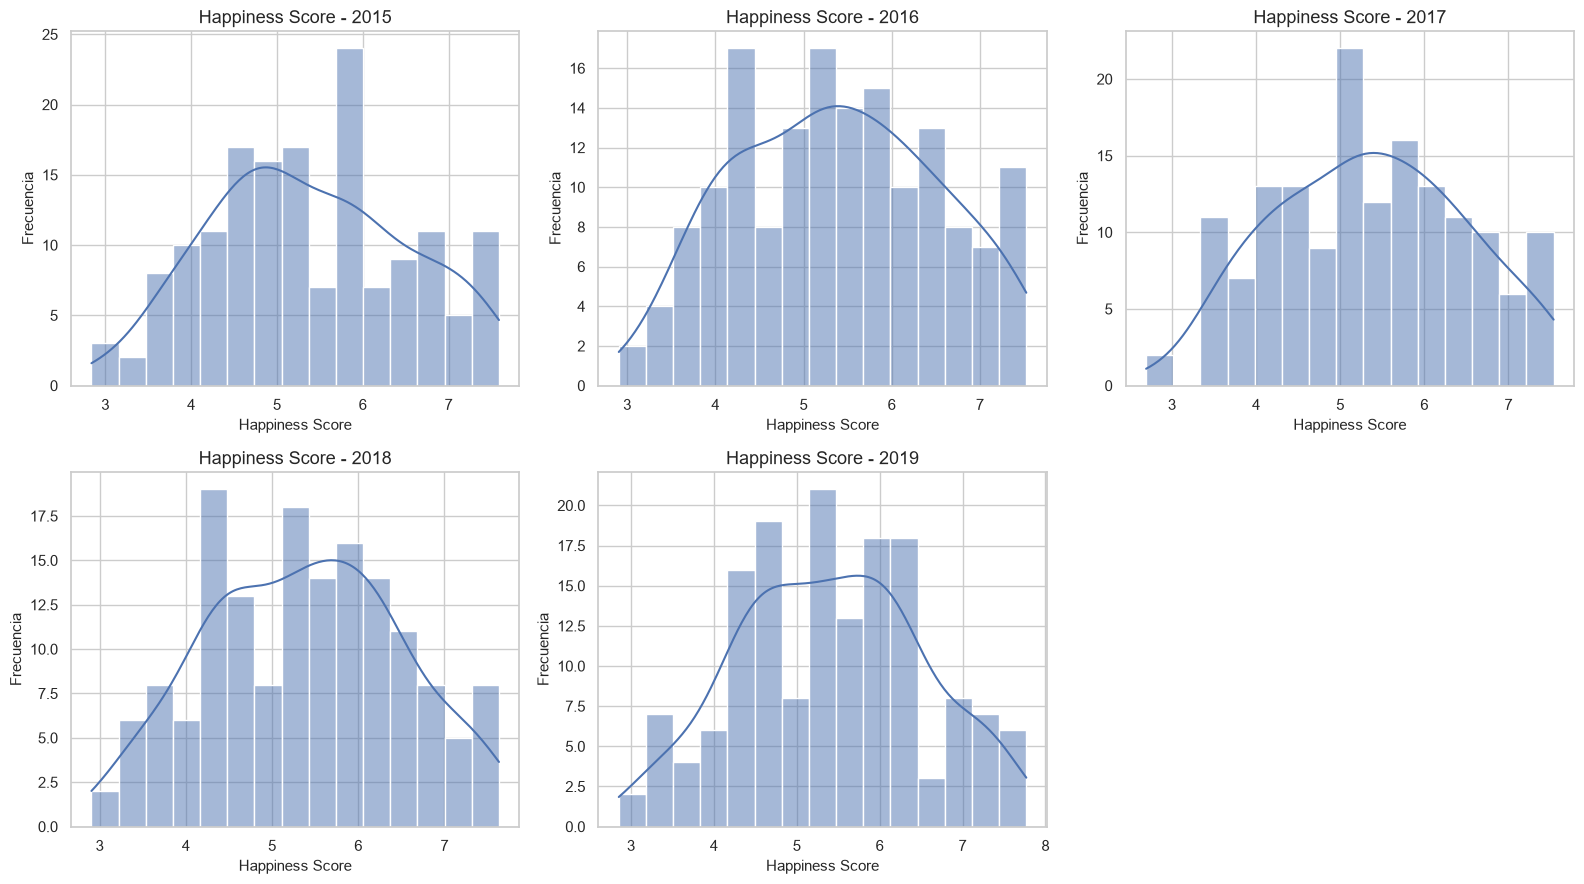

In [101]:
# ============================================================
# 4. HISTOGRAMAS POR AÑO
# ============================================================

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, year in enumerate(YEARS):

    columna_score = COLUMNAS_SCORE[year]
    score = datasets[year][columna_score].dropna()

    sns.histplot(
        score,
        bins=15,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Happiness Score - {year}")
    axes[i].set_xlabel("Happiness Score")
    axes[i].set_ylabel("Frecuencia")

# Ocultar el sexto espacio
axes[5].set_visible(False)

plt.tight_layout()
plt.show()

### 1.5. Comparación de distribuciones entre años

Se utilizarán diagramas de caja para comparar las medianas, rangos
intercuartílicos y posibles valores extremos de Happiness Score
entre las cinco ediciones del informe.

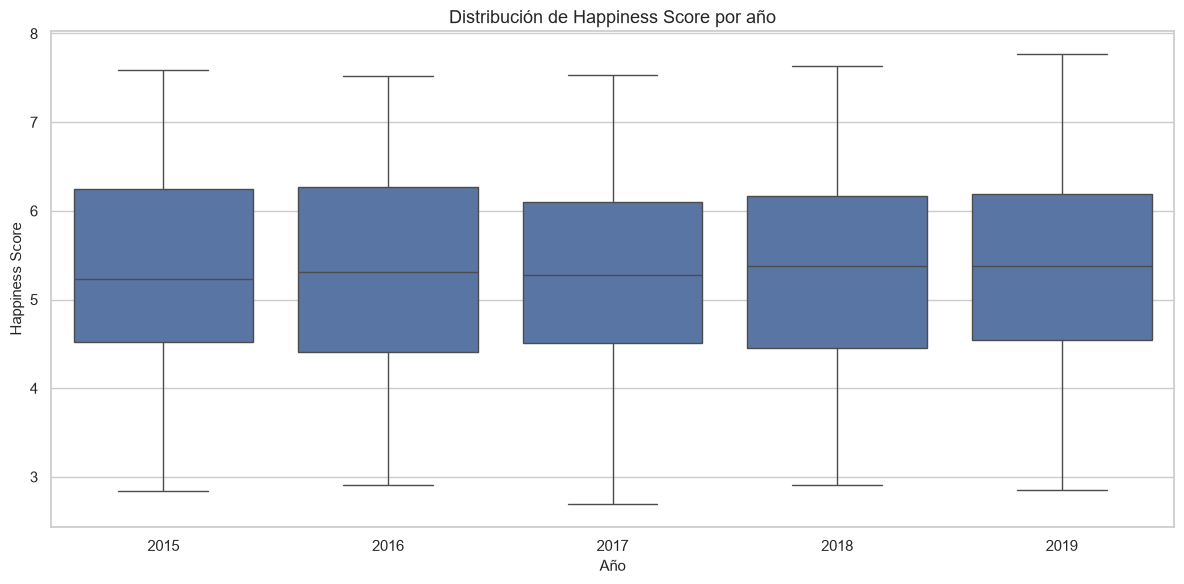

In [102]:
# ============================================================
# 5. BOXPLOTS COMPARATIVOS
# ============================================================

score_comparativo = []

for year, df in datasets.items():

    columna_score = COLUMNAS_SCORE[year]

    temporal = pd.DataFrame({
        "year": year,
        "happiness_score": df[columna_score]
    })

    score_comparativo.append(temporal)

df_score_comparativo = pd.concat(
    score_comparativo,
    ignore_index=True
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_score_comparativo,
    x="year",
    y="happiness_score"
)

plt.title("Distribución de Happiness Score por año")
plt.xlabel("Año")
plt.ylabel("Happiness Score")

plt.tight_layout()
plt.show()

### 1.6. Conclusiones del análisis de Happiness Score

El análisis de la distribución de Happiness Score durante el periodo
2015-2019 evidencia un comportamiento relativamente estable.

La media se mantiene alrededor de 5.4 puntos, mientras que la mediana
presenta un ligero incremento entre 2015 y 2019. Asimismo, la desviación
estándar disminuye progresivamente, lo que sugiere una leve reducción
en la dispersión de las puntuaciones.

Los valores mínimos y máximos presentan variaciones entre ediciones,
sin que esto represente necesariamente anomalías o errores en los datos.

En general, no se identifican cambios drásticos en la distribución
de Happiness Score durante el periodo analizado. Las observaciones
potencialmente atípicas se conservarán, ya que su identificación
estadística no constituye evidencia suficiente para eliminarlas.

### 2. Distribución de indicadores socioeconómicos

Se analizará el comportamiento de los indicadores relacionados con
Happiness Score durante el periodo 2015-2019. Debido a los cambios
en los nombres de las columnas entre ediciones, se establecerá una
correspondencia que permita trabajar con nombres comunes.

In [103]:
# ============================================================
# 1. DEFINICIÓN DE INDICADORES Y EQUIVALENCIAS
# ============================================================

INDICADORES = {
    "GDP": {
        2015: "Economy (GDP per Capita)",
        2016: "Economy (GDP per Capita)",
        2017: "Economy..GDP.per.Capita.",
        2018: "GDP per capita",
        2019: "GDP per capita"
    },
    "Social Support": {
        2015: "Family",
        2016: "Family",
        2017: "Family",
        2018: "Social support",
        2019: "Social support"
    },
    "Health": {
        2015: "Health (Life Expectancy)",
        2016: "Health (Life Expectancy)",
        2017: "Health..Life.Expectancy.",
        2018: "Healthy life expectancy",
        2019: "Healthy life expectancy"
    },
    "Freedom": {
        2015: "Freedom",
        2016: "Freedom",
        2017: "Freedom",
        2018: "Freedom to make life choices",
        2019: "Freedom to make life choices"
    },
    "Corruption": {
        2015: "Trust (Government Corruption)",
        2016: "Trust (Government Corruption)",
        2017: "Trust..Government.Corruption.",
        2018: "Perceptions of corruption",
        2019: "Perceptions of corruption"
    },
    "Generosity": {
        2015: "Generosity",
        2016: "Generosity",
        2017: "Generosity",
        2018: "Generosity",
        2019: "Generosity"
    }
}

# Verificar que las columnas existan
for indicador, columnas in INDICADORES.items():
    for year, columna in columnas.items():
        if columna not in datasets[year].columns:
            raise ValueError(
                f"Falta la columna '{columna}' para {indicador}, año {year}"
            )

print("Todas las columnas de los indicadores fueron identificadas correctamente.")

Todas las columnas de los indicadores fueron identificadas correctamente.


### 2.2. Estadísticas descriptivas

Se calcularán medidas de tendencia central, dispersión y posición
para cada indicador en cada edición. Esto permitirá identificar
variaciones en sus distribuciones y detectar posibles diferencias
entre años.

In [104]:
# ============================================================
# 2. ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

resumen_indicadores = []

for indicador, columnas in INDICADORES.items():

    for year, columna in columnas.items():

        serie = datasets[year][columna]

        resumen_indicadores.append({
            "indicator": indicador,
            "year": year,
            "count": serie.count(),
            "mean": serie.mean(),
            "median": serie.median(),
            "std": serie.std(),
            "min": serie.min(),
            "q1": serie.quantile(0.25),
            "q3": serie.quantile(0.75),
            "max": serie.max()
        })

df_resumen_indicadores = pd.DataFrame(resumen_indicadores)

df_resumen_indicadores.round(3)

,indicator,year,count,mean,median,std,min,q1,q3,max
0,GDP,2015,158,0.846,0.910,0.403,0.0,0.546,1.158,1.690
1,GDP,2016,157,0.954,1.028,0.413,0.0,0.670,1.280,1.824
2,GDP,2017,155,0.985,1.065,0.421,0.0,0.663,1.318,1.871
3,GDP,2018,156,0.891,0.950,0.392,0.0,0.616,1.198,2.096
4,GDP,2019,156,0.905,0.960,0.398,0.0,0.603,1.233,1.684
5,Social Support,2015,158,0.991,1.030,0.272,0.0,0.857,1.214,1.402
6,Social Support,2016,157,0.794,0.841,0.267,0.0,0.642,1.022,1.183
7,Social Support,2017,155,1.189,1.254,0.287,0.0,1.043,1.414,1.611
8,Social Support,2018,156,1.213,1.255,0.302,0.0,1.067,1.463,1.644
9,Social Support,2019,156,1.209,1.272,0.299,0.0,1.056,1.452,1.624


### 2.3. Distribución de frecuencias

Se generarán histogramas individuales para los seis indicadores,
separados por año. Las visualizaciones permitirán observar la forma
de las distribuciones, concentraciones de valores y posibles asimetrías.

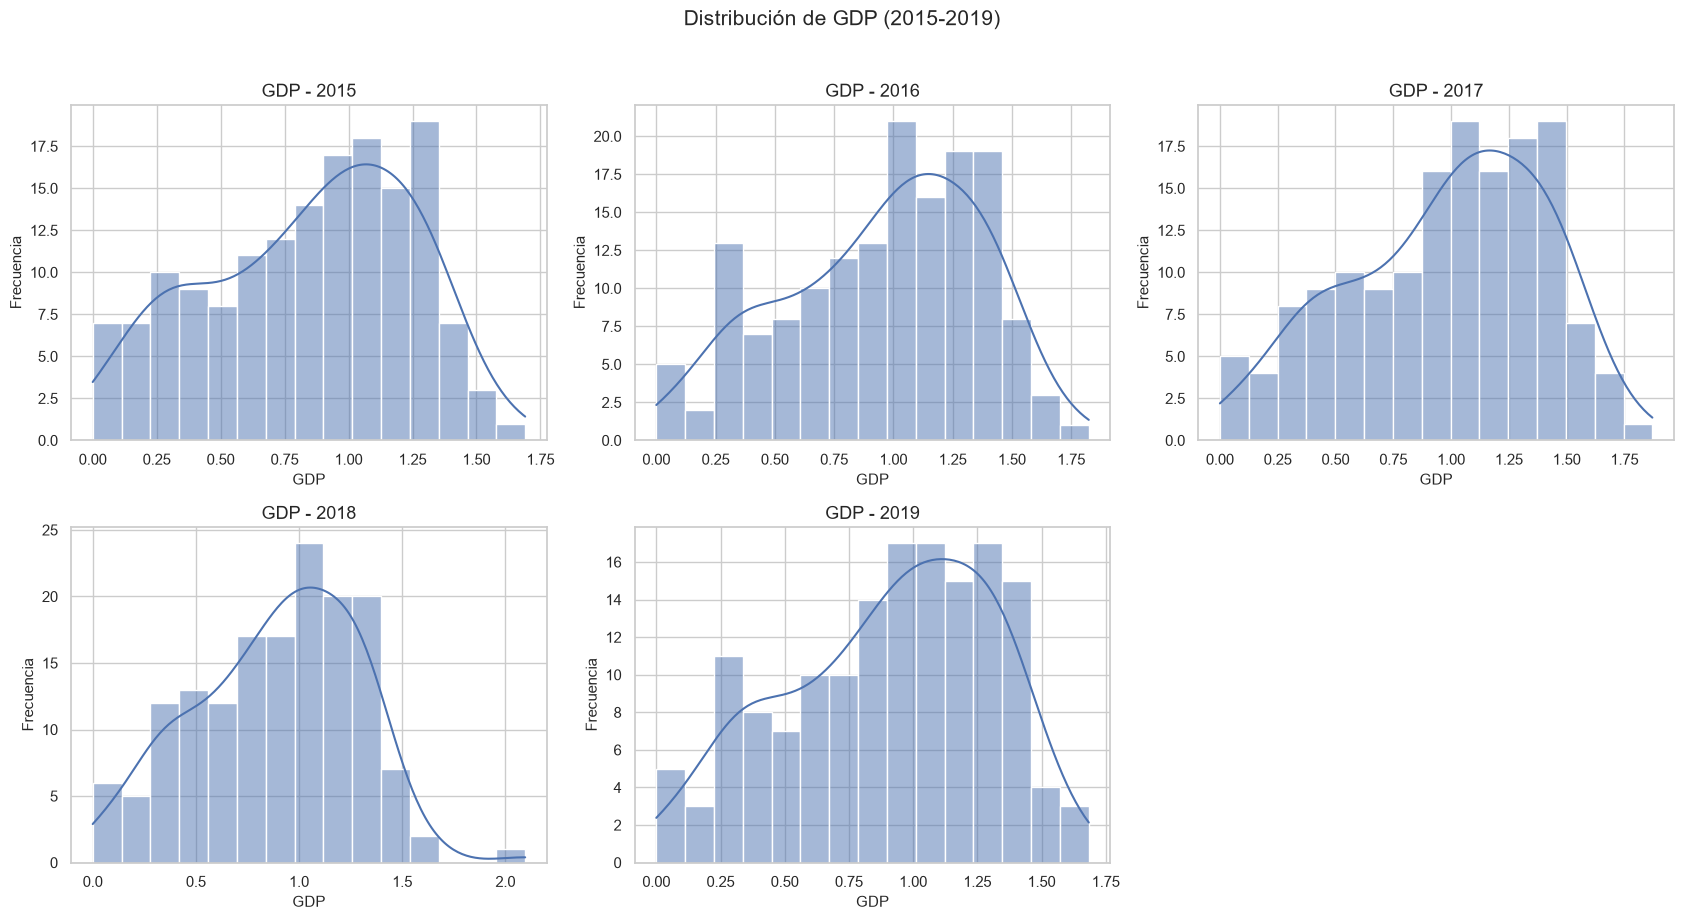

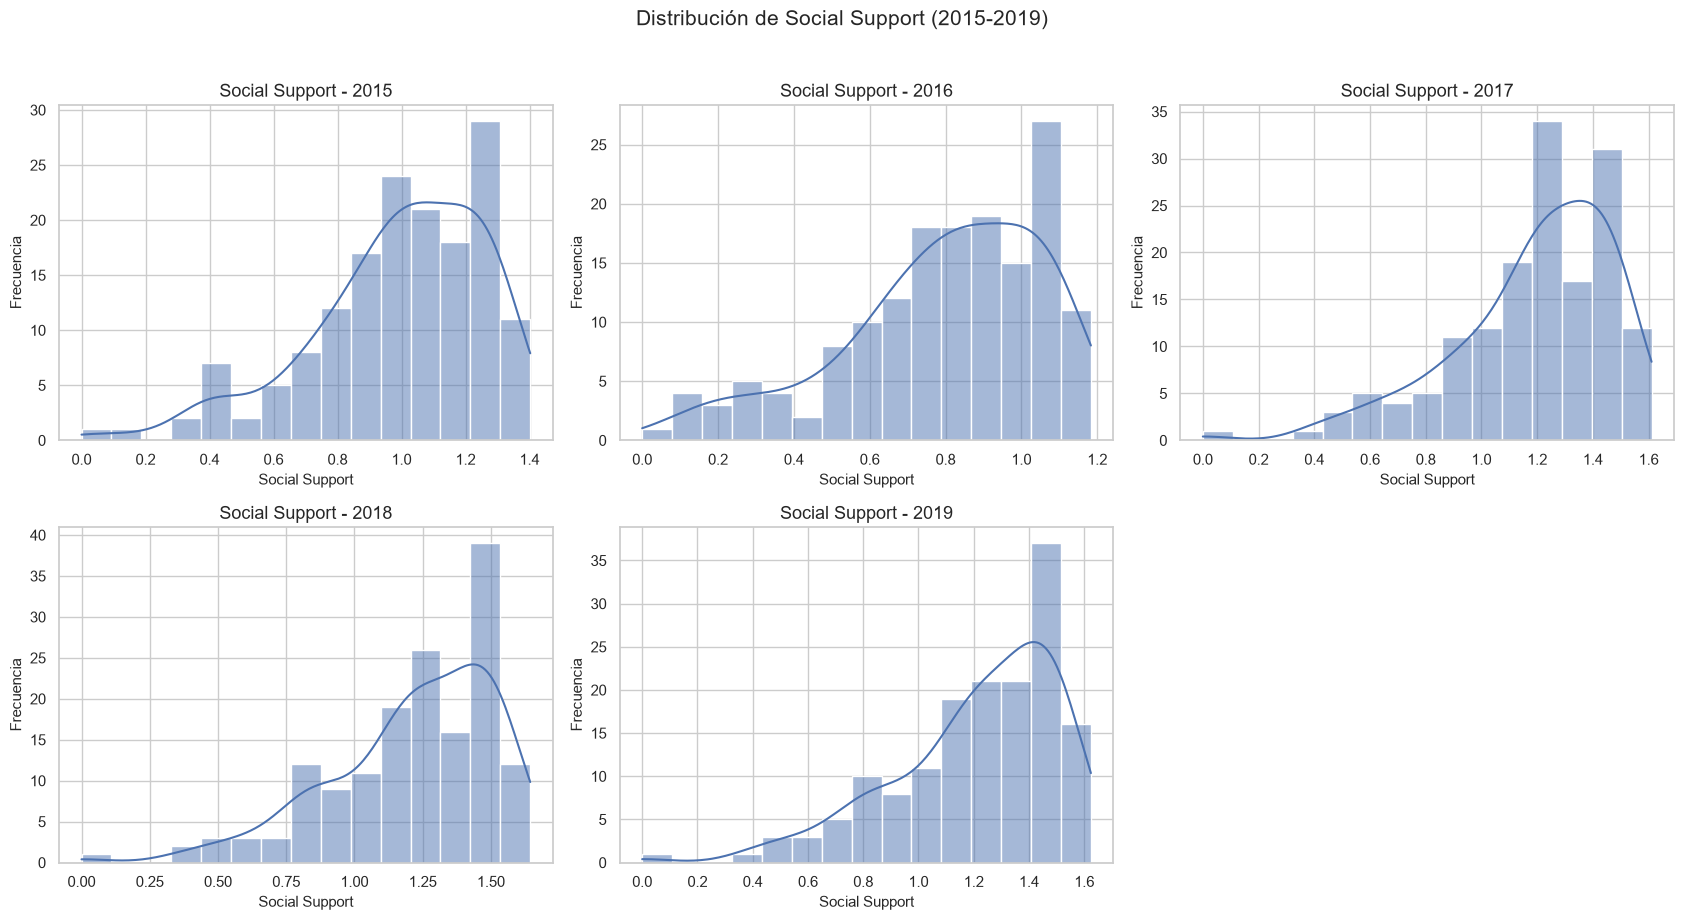

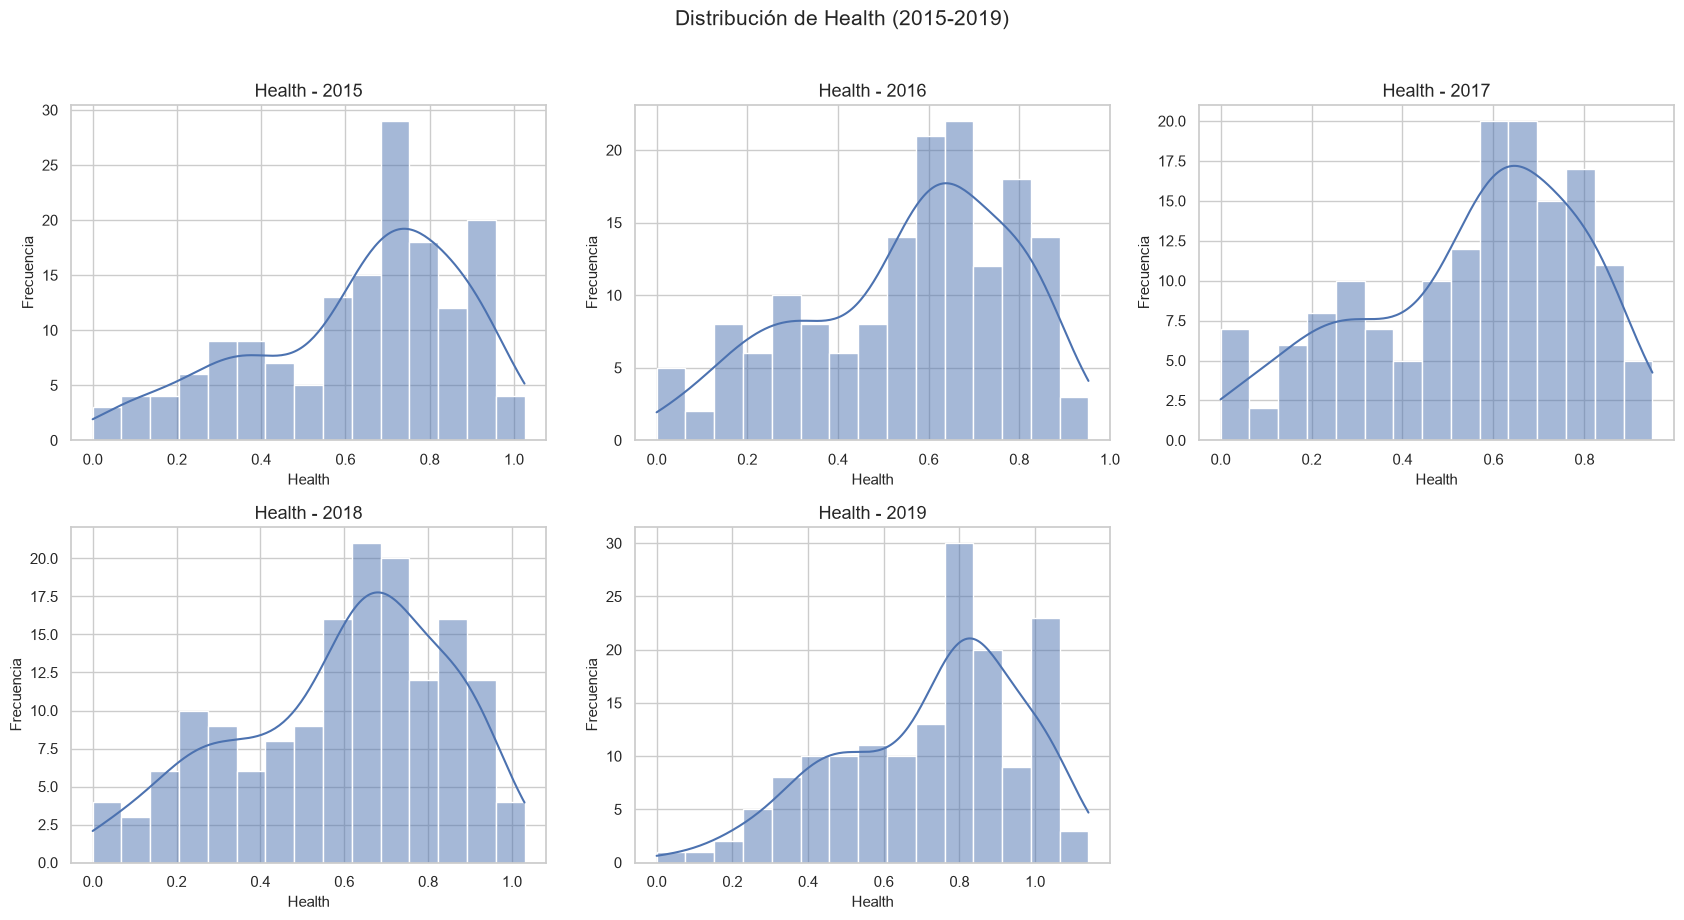

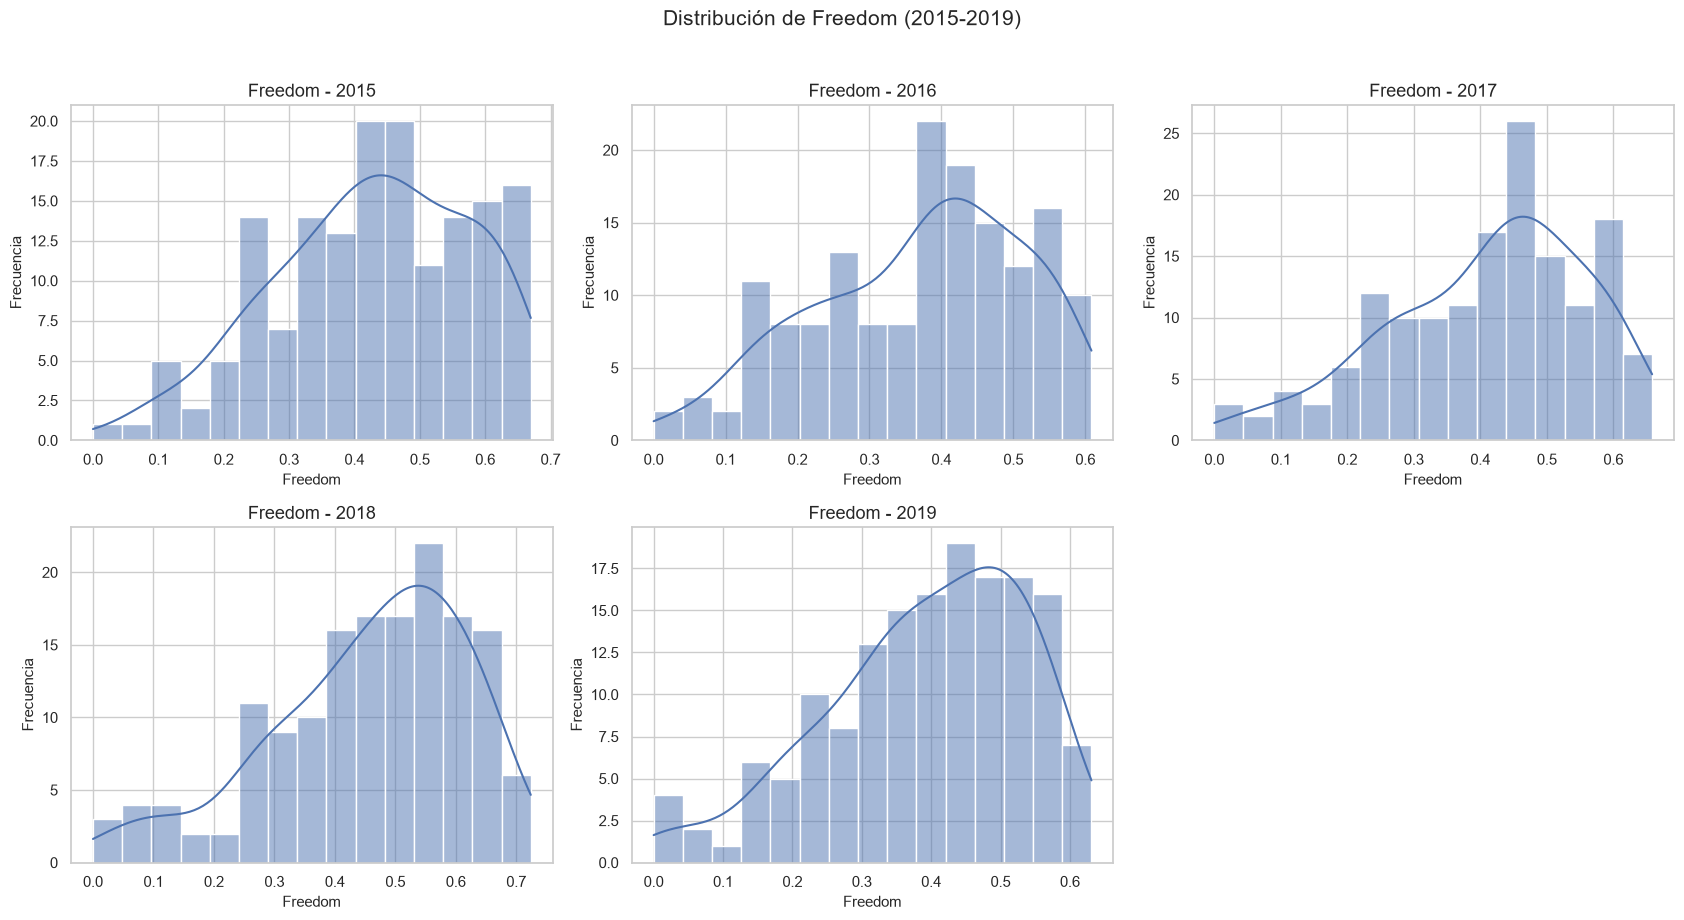

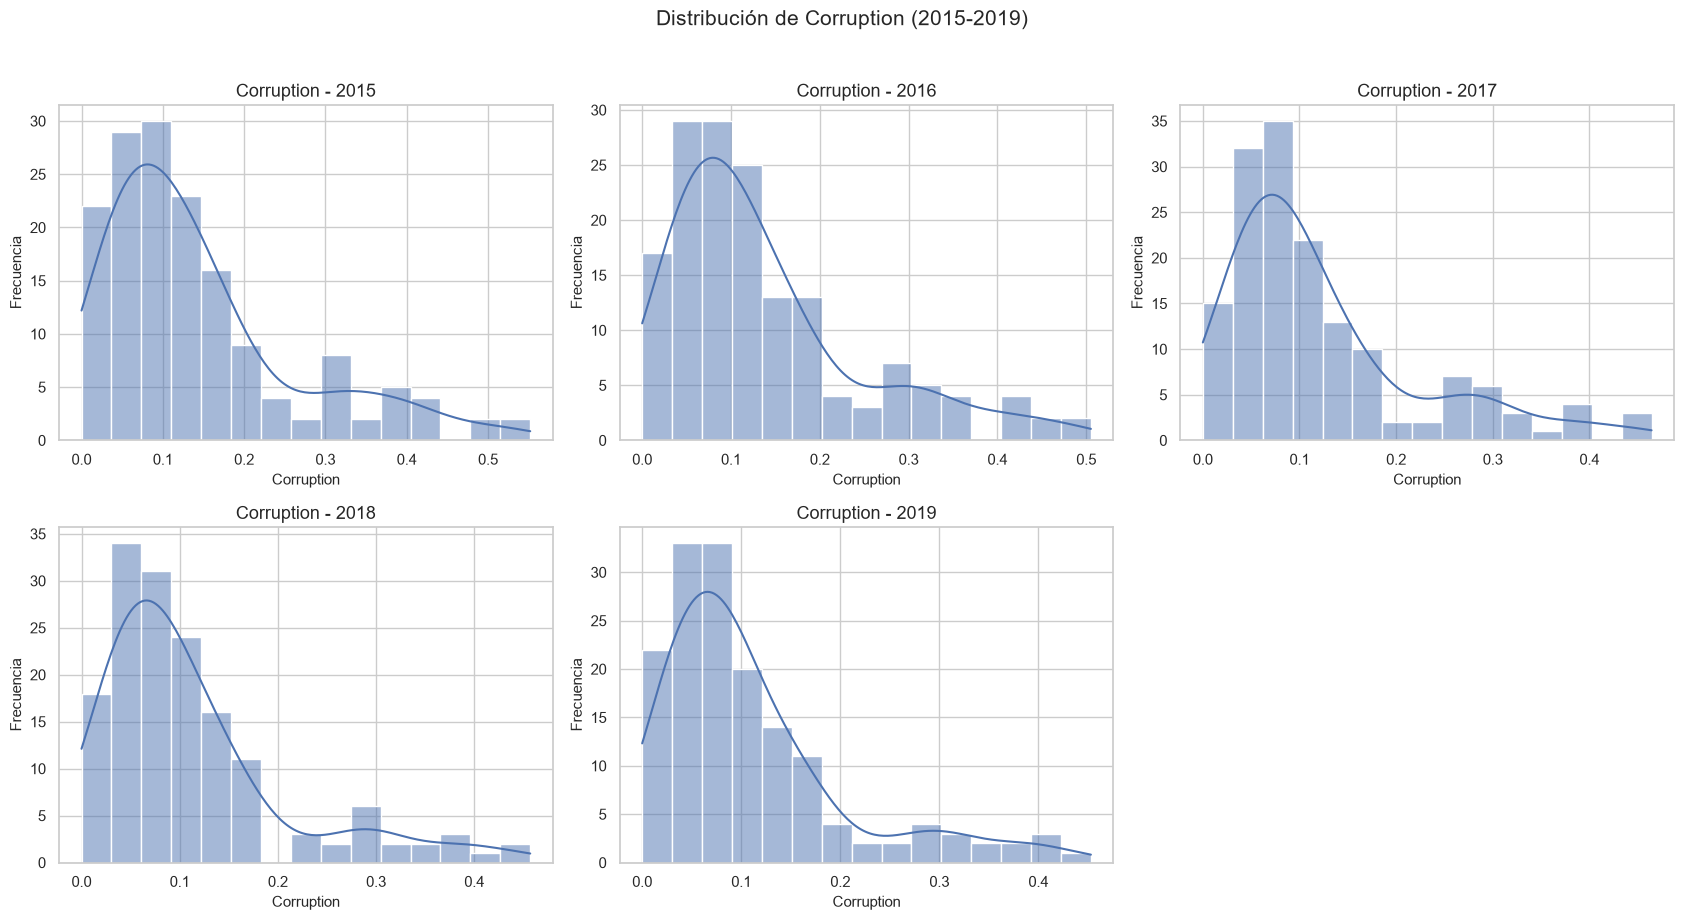

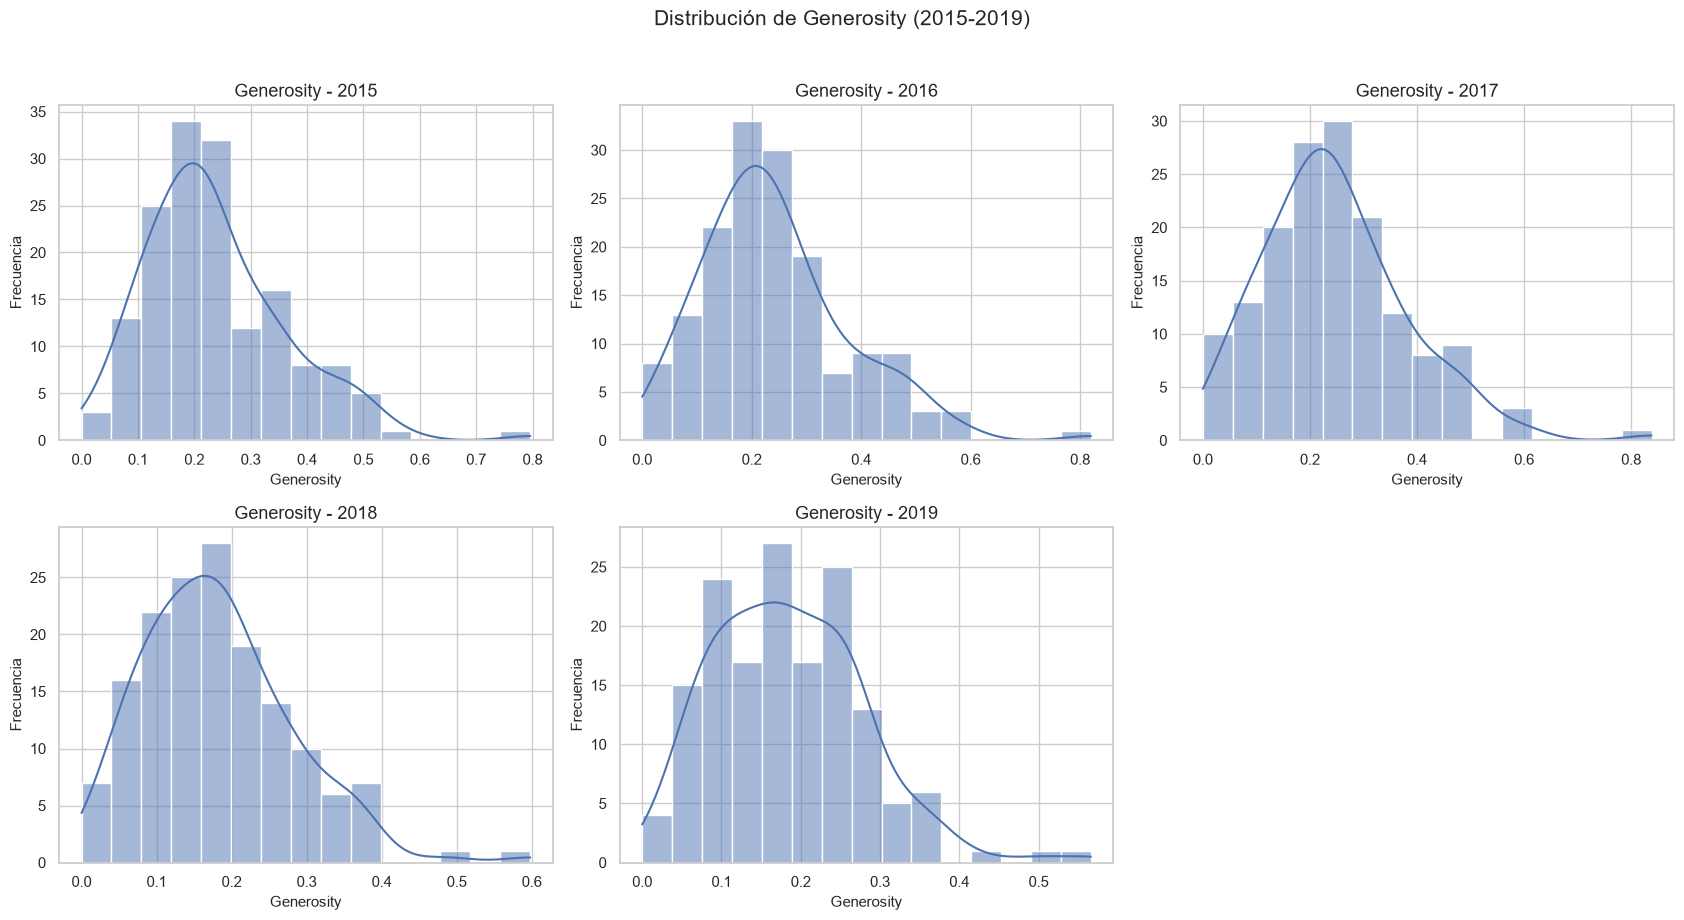

In [105]:
# ============================================================
# 3. HISTOGRAMAS POR INDICADOR Y AÑO
# ============================================================

for indicador, columnas in INDICADORES.items():

    fig, axes = plt.subplots(2, 3, figsize=(17, 9))

    axes = axes.flatten()

    for i, year in enumerate(YEARS):

        columna = columnas[year]

        serie = datasets[year][columna].dropna()

        sns.histplot(
            serie,
            bins=15,
            kde=True,
            ax=axes[i]
        )

        axes[i].set_title(f"{indicador} - {year}")
        axes[i].set_xlabel(indicador)
        axes[i].set_ylabel("Frecuencia")

    axes[5].set_visible(False)

    fig.suptitle(
        f"Distribución de {indicador} (2015-2019)",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

### 2.4. Identificación visual de valores extremos

Se construirán diagramas de caja para cada indicador, comparando
sus distribuciones entre los cinco años. Se observarán la mediana,
el rango intercuartílico y las observaciones que puedan encontrarse
fuera de los límites establecidos por el criterio IQR.

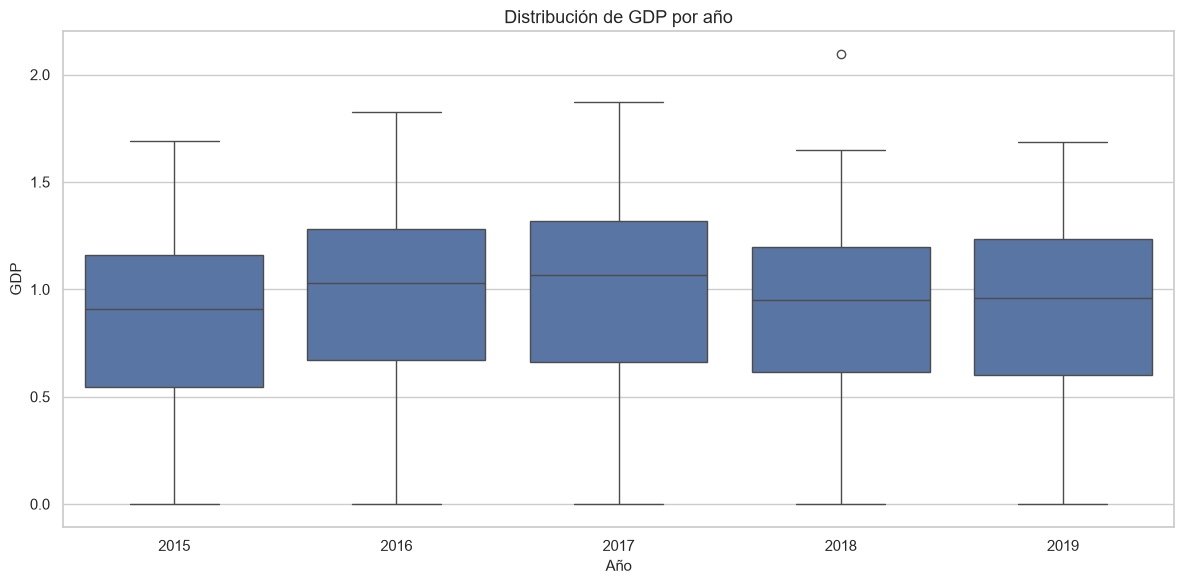

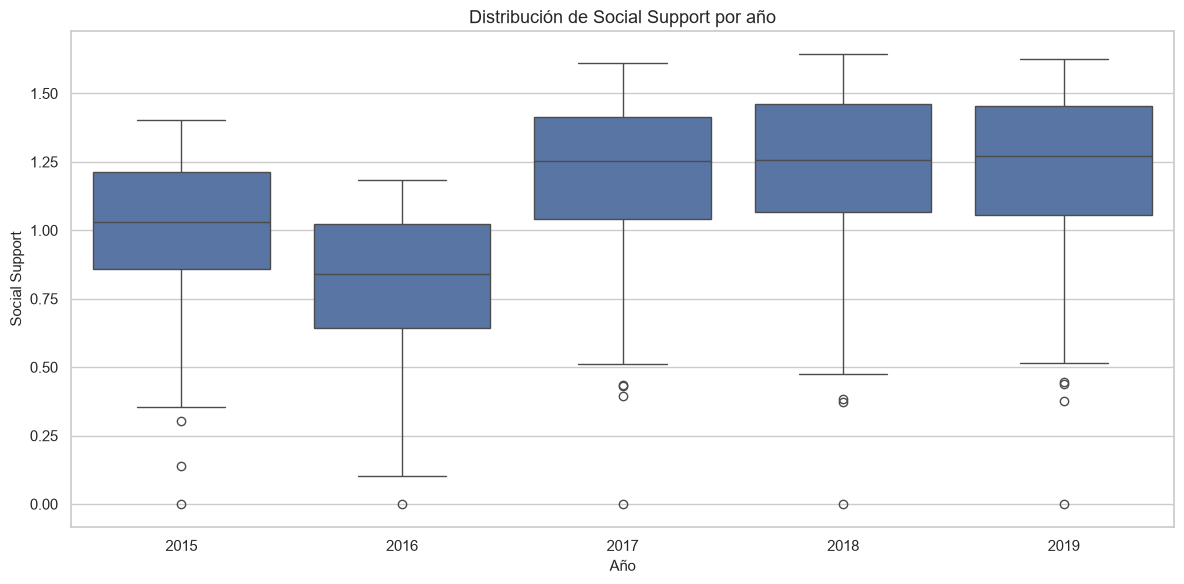

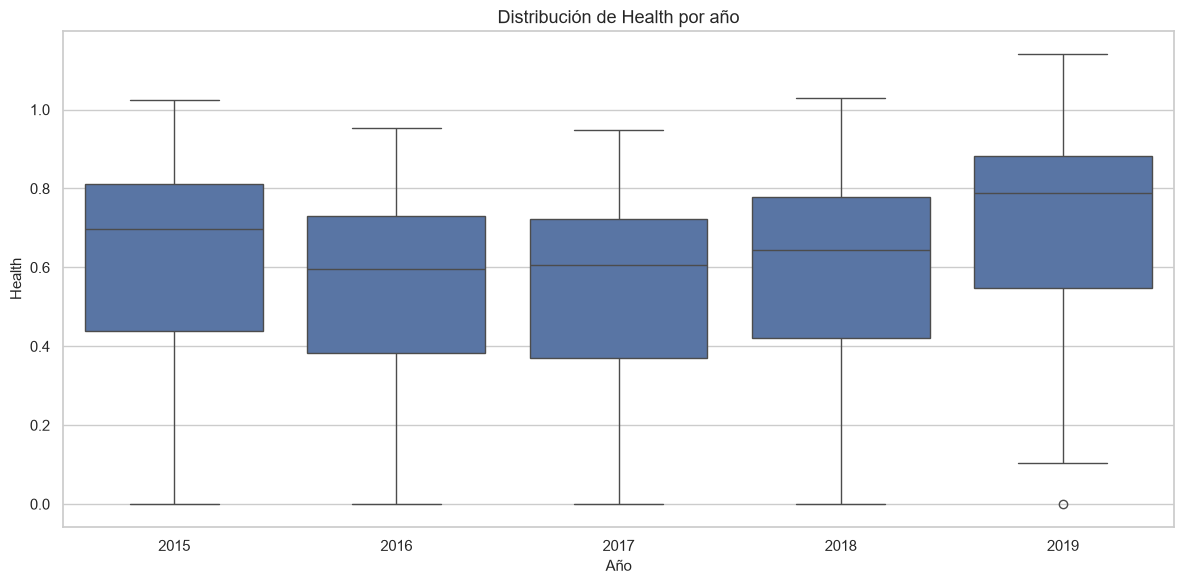

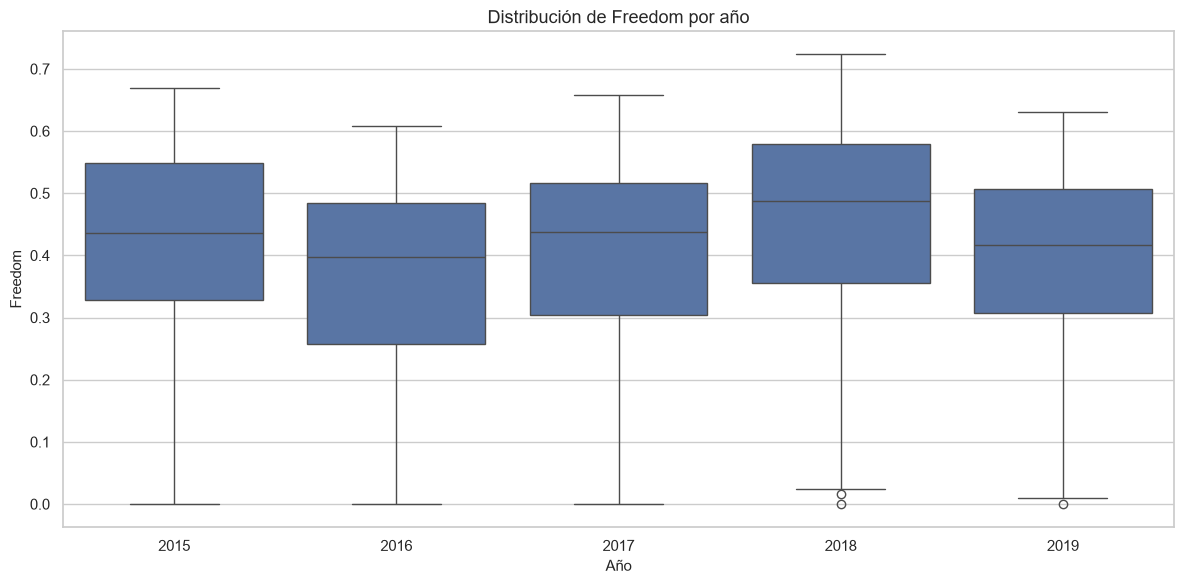

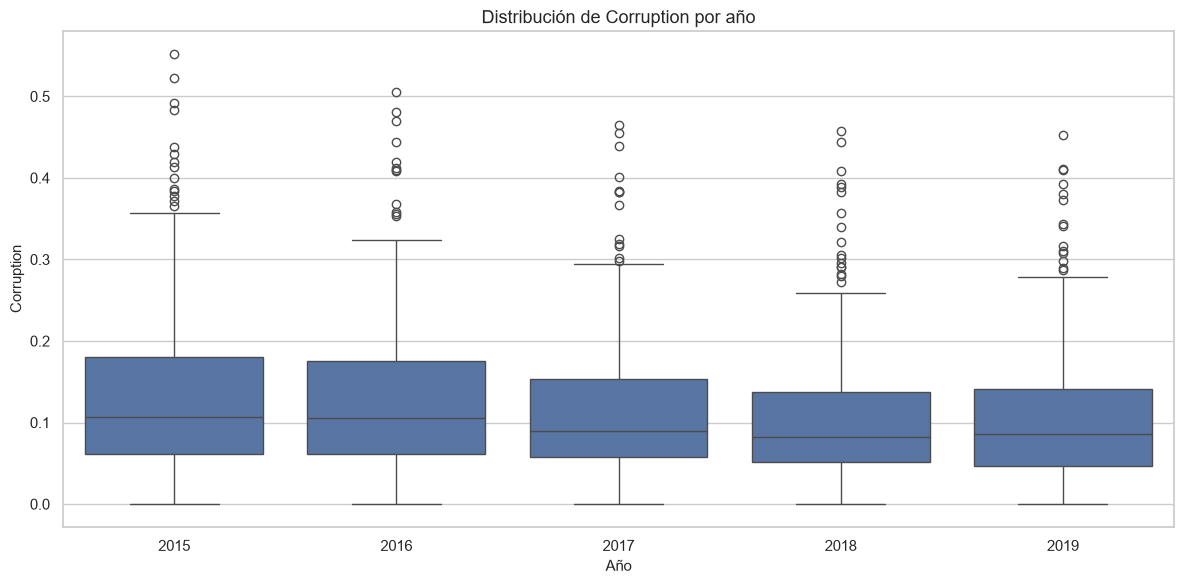

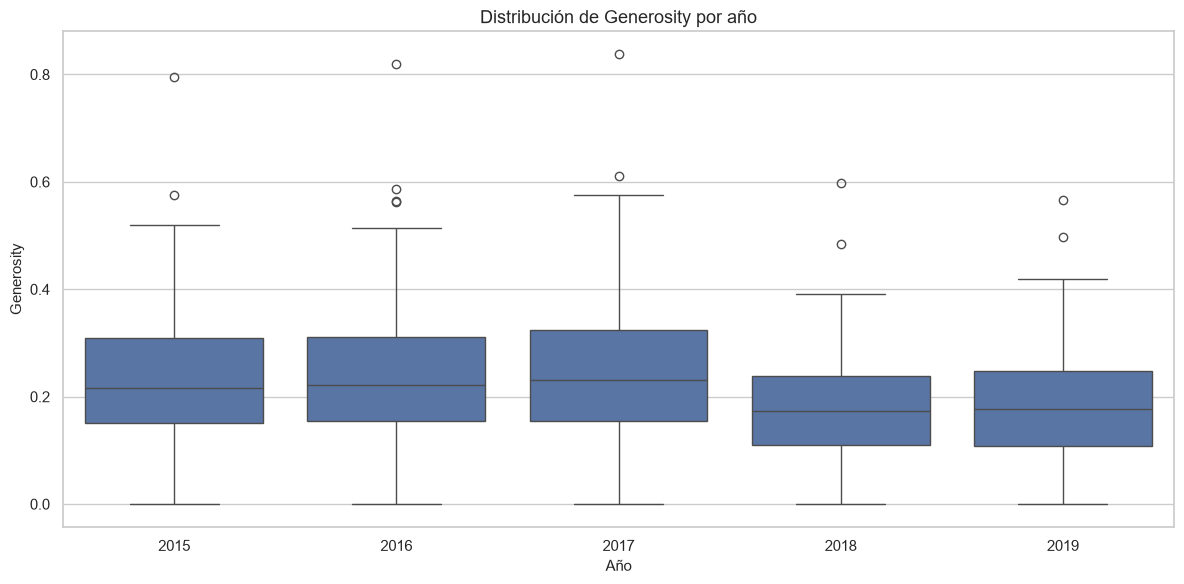

In [106]:
# ============================================================
# 4. BOXPLOTS POR INDICADOR Y AÑO
# ============================================================

for indicador, columnas in INDICADORES.items():

    datos = []

    for year, columna in columnas.items():

        temporal = pd.DataFrame({
            "year": year,
            "value": datasets[year][columna]
        })

        datos.append(temporal)

    df_temporal = pd.concat(datos, ignore_index=True)

    plt.figure(figsize=(12, 6))

    sns.boxplot(
        data=df_temporal,
        x="year",
        y="value"
    )

    plt.title(f"Distribución de {indicador} por año")
    plt.xlabel("Año")
    plt.ylabel(indicador)

    plt.tight_layout()
    plt.show()

### 2.5. Detección estadística de posibles valores atípicos

Se aplicará el criterio de 1.5 veces el rango intercuartílico (IQR)
a cada indicador y año. Se contabilizarán las observaciones que superen
los límites inferior o superior, sin modificar ni eliminar registros.

In [107]:
# ============================================================
# 5. RESUMEN DE OUTLIERS POR INDICADOR Y AÑO
# ============================================================

resumen_outliers = []

for indicador, columnas in INDICADORES.items():

    for year, columna in columnas.items():

        serie = datasets[year][columna].dropna()

        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)

        iqr = q3 - q1

        limite_inferior = q1 - (1.5 * iqr)
        limite_superior = q3 + (1.5 * iqr)

        mascara_outliers = (
            (serie < limite_inferior) |
            (serie > limite_superior)
        )

        cantidad = mascara_outliers.sum()

        resumen_outliers.append({
            "indicator": indicador,
            "year": year,
            "total_values": len(serie),
            "outlier_count": cantidad,
            "outlier_percentage": (
                cantidad / len(serie) * 100
                if len(serie) > 0 else 0
            ),
            "lower_limit": limite_inferior,
            "upper_limit": limite_superior
        })

df_resumen_outliers = pd.DataFrame(resumen_outliers)

df_resumen_outliers.round(3)

,indicator,year,total_values,outlier_count,outlier_percentage,lower_limit,upper_limit
0,GDP,2015,158,0,0.000,-0.373,2.077
1,GDP,2016,157,0,0.000,-0.244,2.194
2,GDP,2017,155,0,0.000,-0.319,2.300
3,GDP,2018,156,1,0.641,-0.256,2.070
4,GDP,2019,156,0,0.000,-0.342,2.177
5,Social Support,2015,158,3,1.899,0.320,1.751
6,Social Support,2016,157,1,0.637,0.072,1.591
7,Social Support,2017,155,4,2.581,0.485,1.972
8,Social Support,2018,156,3,1.923,0.472,2.057
9,Social Support,2019,156,4,2.564,0.461,2.048


### 2.6. Revisión de observaciones potencialmente atípicas

Se identificarán los países cuyos valores se encuentran fuera de los
límites IQR para cada indicador y año. También se revisarán los valores
iguales a cero para distinguir observaciones que requieren verificación.

Esta revisión es exclusivamente diagnóstica y no modifica los datos.

In [108]:
# ============================================================
# 6. DETALLE DE OBSERVACIONES ATÍPICAS
# ============================================================

detalle_outliers = []

for indicador, columnas in INDICADORES.items():

    for year, columna in columnas.items():

        df = datasets[year]

        serie = df[columna]

        q1 = serie.quantile(0.25)
        q3 = serie.quantile(0.75)
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        mascara = (
            (serie < limite_inferior) |
            (serie > limite_superior)
        )

        for indice in df.index[mascara]:

            valor = serie.loc[indice]

            detalle_outliers.append({
                "year": year,
                "indicator": indicador,
                "country": df.loc[indice].get(
                    "Country",
                    df.loc[indice].get("Country or region")
                ),
                "value": valor,
                "type": (
                    "Inferior"
                    if valor < limite_inferior
                    else "Superior"
                ),
                "lower_limit": limite_inferior,
                "upper_limit": limite_superior
            })

df_detalle_outliers = pd.DataFrame(detalle_outliers)

df_detalle_outliers.sort_values(
    ["indicator", "year", "type", "value"]
).reset_index(drop=True)

,year,indicator,country,value,type,lower_limit,upper_limit
0,2015,Corruption,Norway,0.36503,Superior,-0.116195,0.358125
1,2015,Corruption,Hong Kong,0.37124,Superior,-0.116195,0.358125
2,2015,Corruption,Luxembourg,0.37798,Superior,-0.116195,0.358125
3,2015,Corruption,Georgia,0.38331,Superior,-0.116195,0.358125
4,2015,Corruption,United Arab Emirates,0.38583,Superior,-0.116195,0.358125
...,...,...,...,...,...,...,...
97,2018,Social Support,Syria,0.38200,Inferior,0.472375,2.057375
98,2019,Social Support,Central African Republic,0.00000,Inferior,0.460625,2.047625
99,2019,Social Support,Syria,0.37800,Inferior,0.460625,2.047625
100,2019,Social Support,Benin,0.43700,Inferior,0.460625,2.047625


In [109]:
# ============================================================
# 7. IDENTIFICACIÓN DE VALORES IGUALES A CERO
# ============================================================

valores_cero = []

for indicador, columnas in INDICADORES.items():

    for year, columna in columnas.items():

        df = datasets[year]

        mascara = df[columna] == 0

        for indice in df.index[mascara]:

            valores_cero.append({
                "year": year,
                "indicator": indicador,
                "country": df.loc[indice].get(
                    "Country",
                    df.loc[indice].get("Country or region")
                ),
                "value": df.loc[indice, columna]
            })

df_valores_cero = pd.DataFrame(valores_cero)

df_valores_cero

,year,indicator,country,value
0,2015,GDP,Congo (Kinshasa),0.0
1,2016,GDP,Somalia,0.0
2,2017,GDP,Central African Republic,0.0
3,2018,GDP,Somalia,0.0
4,2019,GDP,Somalia,0.0
5,2015,Social Support,Central African Republic,0.0
6,2016,Social Support,Togo,0.0
7,2017,Social Support,Central African Republic,0.0
8,2018,Social Support,Central African Republic,0.0
9,2019,Social Support,Central African Republic,0.0


### 2.7. Conclusiones de la distribución de indicadores

El análisis de los seis indicadores socioeconómicos durante el periodo
2015-2019 permitió identificar diferencias importantes en sus
distribuciones.

GDP y Freedom presentan comportamientos relativamente estables,
mientras que Social Support y Health muestran variaciones entre
ediciones. Generosity presenta una disminución en sus valores medios
desde 2018.

Corruption destaca por presentar distribuciones asimétricas y una
mayor cantidad de observaciones identificadas como potencialmente
atípicas mediante el criterio IQR.

La aplicación de este criterio permitió identificar observaciones
extremas en diferentes indicadores y años. Sin embargo, estos
resultados representan alertas estadísticas y no evidencias de
errores en los registros.

Se decidió conservar todas las observaciones, documentando los
posibles valores atípicos para su posterior evaluación.

Adicionalmente, se identificó un valor de cero en Healthy life
expectancy para Swaziland en 2019, que queda pendiente de verificación.

Finalmente, las diferencias metodológicas y de nomenclatura entre
las ediciones deberán considerarse antes de realizar comparaciones
temporales o interpretar cambios en los indicadores.

### 3. Análisis de relaciones entre indicadores

Se prepararán los datos de cada edición utilizando nombres comunes
para Happiness Score y los seis indicadores socioeconómicos.

Esta estructura facilitará el análisis de correlaciones y relaciones
entre variables, conservando la identificación del año y del país.

In [110]:
# ============================================================
# 1. PREPARACIÓN DE DATOS ARMONIZADOS
# ============================================================

datos_relaciones = []

for year in YEARS:

    df = datasets[year]

    # Identificar columna del país
    columna_pais = (
        "Country"
        if "Country" in df.columns
        else "Country or region"
    )

    # Crear estructura común
    temporal = pd.DataFrame({
        "year": year,
        "country": df[columna_pais],
        "happiness_score": df[COLUMNAS_SCORE[year]]
    })

    # Incorporar indicadores
    for indicador, columnas in INDICADORES.items():

        temporal[indicador] = df[columnas[year]]

    datos_relaciones.append(temporal)


df_relaciones = pd.concat(
    datos_relaciones,
    ignore_index=True
)

print("Registros:", len(df_relaciones))
print("Columnas:", df_relaciones.columns.tolist())

df_relaciones.head()

Registros: 782
Columnas: ['year', 'country', 'happiness_score', 'GDP', 'Social Support', 'Health', 'Freedom', 'Corruption', 'Generosity']


,year,country,happiness_score,GDP,Social Support,Health,Freedom,Corruption,Generosity
0,2015,Switzerland,7.587,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678
1,2015,Iceland,7.561,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630
2,2015,Denmark,7.527,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139
3,2015,Norway,7.522,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699
4,2015,Canada,7.427,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811


### 3.2. Matrices de correlación

Se calcularán matrices de correlación de Pearson para cada año,
considerando Happiness Score y los seis indicadores socioeconómicos.

Las matrices permitirán identificar la dirección y fuerza de las
asociaciones lineales entre las variables.

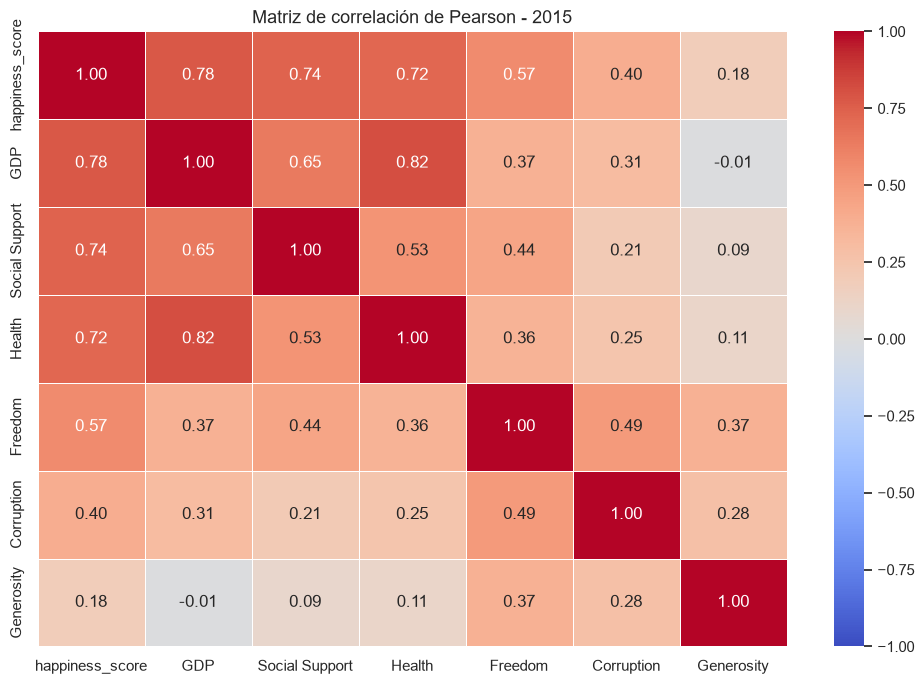

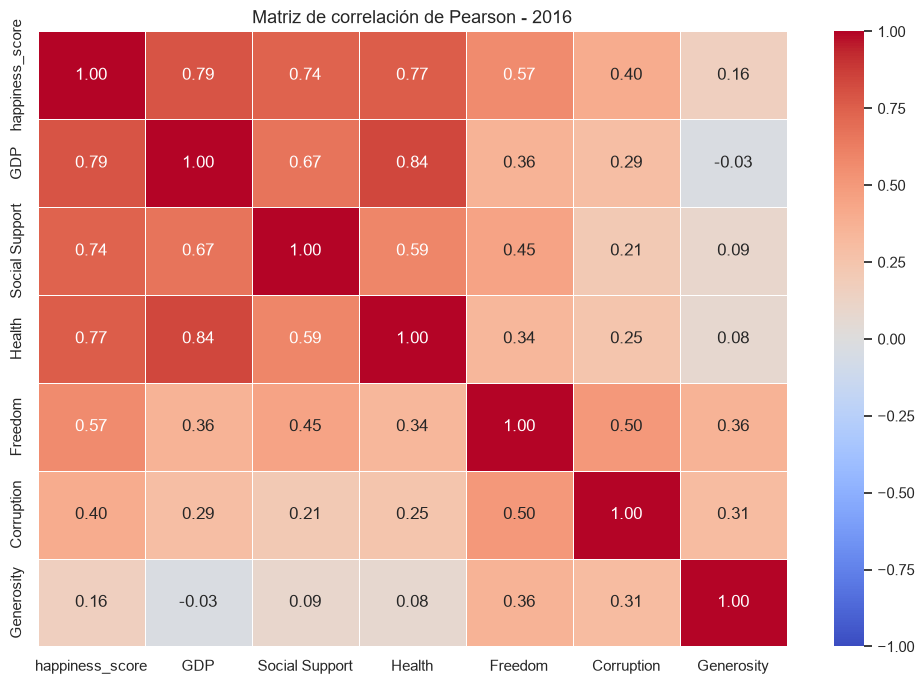

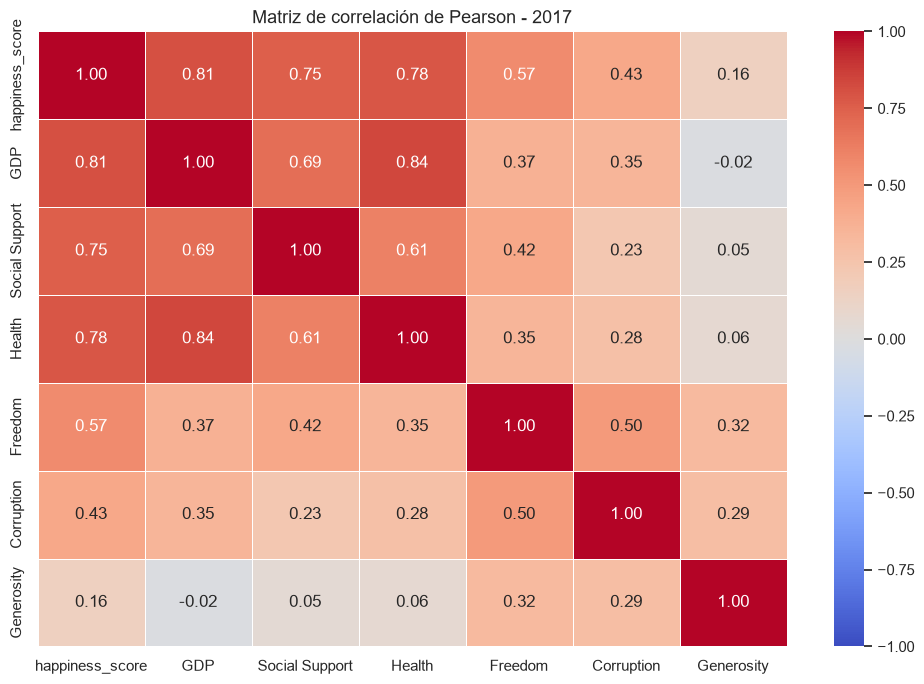

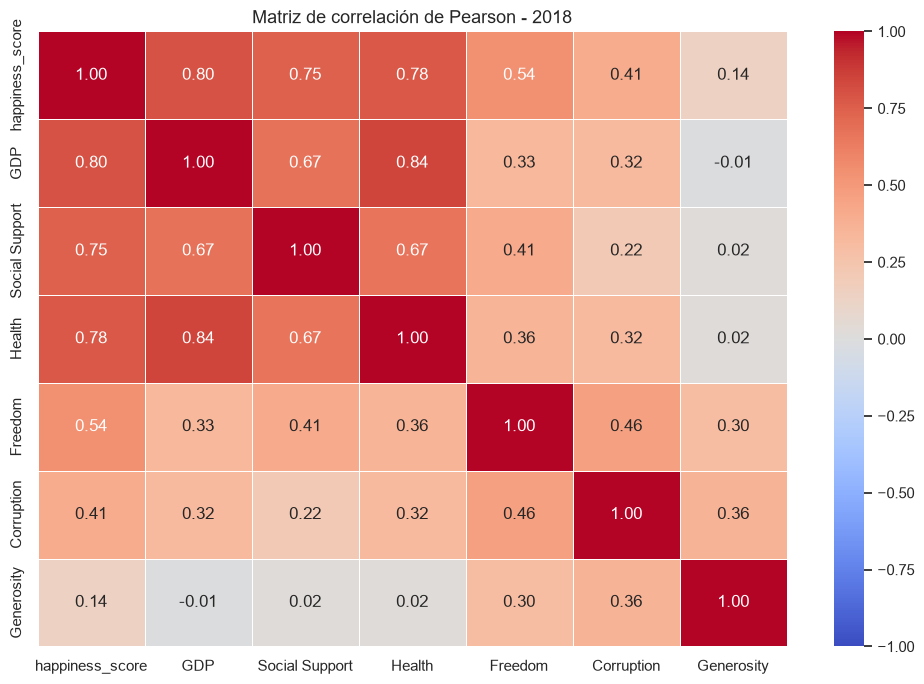

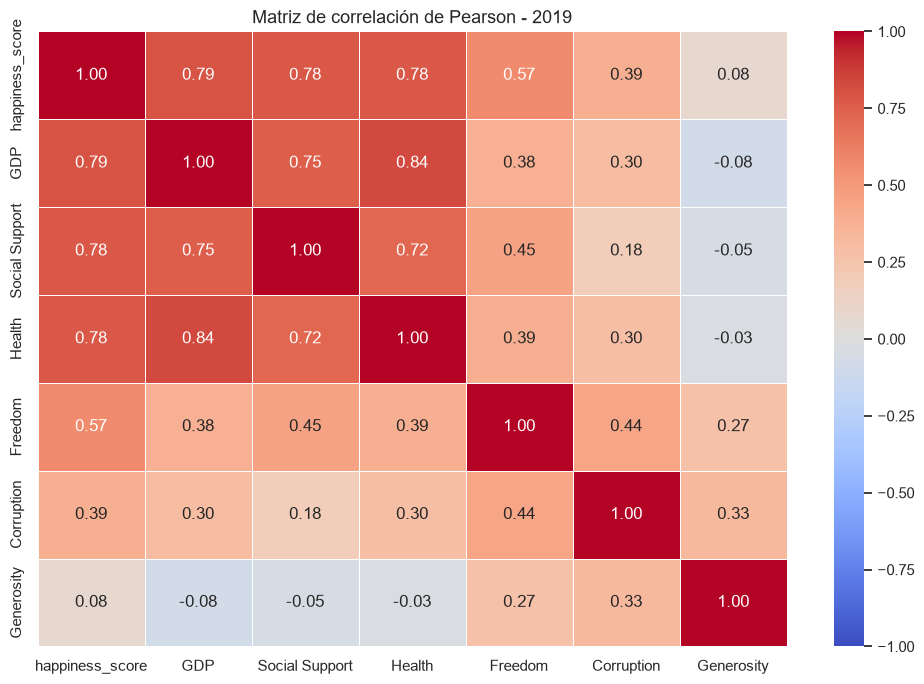

In [111]:
# ============================================================
# 2. MATRICES DE CORRELACIÓN POR AÑO
# ============================================================

VARIABLES_CORRELACION = [
    "happiness_score",
    "GDP",
    "Social Support",
    "Health",
    "Freedom",
    "Corruption",
    "Generosity"
]

matrices_correlacion = {}

for year in YEARS:

    df_anual = df_relaciones[
        df_relaciones["year"] == year
    ]

    matriz = df_anual[
        VARIABLES_CORRELACION
    ].corr(method="pearson")

    matrices_correlacion[year] = matriz

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5
    )

    plt.title(f"Matriz de correlación de Pearson - {year}")
    plt.tight_layout()
    plt.show()

### 3.3. Correlación con Happiness Score

Se extraerán las correlaciones entre Happiness Score y cada indicador
para comparar cuáles presentan asociaciones lineales más fuertes
en cada edición del informe.

In [112]:
# ============================================================
# 3. CORRELACIÓN CON HAPPINESS SCORE
# ============================================================

correlaciones_score = []

for year, matriz in matrices_correlacion.items():

    for indicador in INDICADORES.keys():

        correlaciones_score.append({
            "year": year,
            "indicator": indicador,
            "correlation": matriz.loc[
                "happiness_score",
                indicador
            ]
        })

df_correlaciones_score = pd.DataFrame(
    correlaciones_score
)

df_correlaciones_score.pivot(
    index="indicator",
    columns="year",
    values="correlation"
).round(3)

year,2015,2016,2017,2018,2019
indicator,,,,,
Corruption,0.395,0.402,0.429,0.405,0.386
Freedom,0.568,0.567,0.570,0.544,0.567
GDP,0.781,0.790,0.812,0.802,0.794
Generosity,0.180,0.157,0.155,0.136,0.076
Health,0.724,0.765,0.782,0.776,0.780
Social Support,0.741,0.739,0.753,0.746,0.777


### 3.4. Comparación de correlaciones entre años

Se representarán las correlaciones entre Happiness Score y los
indicadores mediante un mapa de calor. Esto permitirá comparar
visualmente la intensidad y dirección de las asociaciones durante
el periodo 2015-2019.

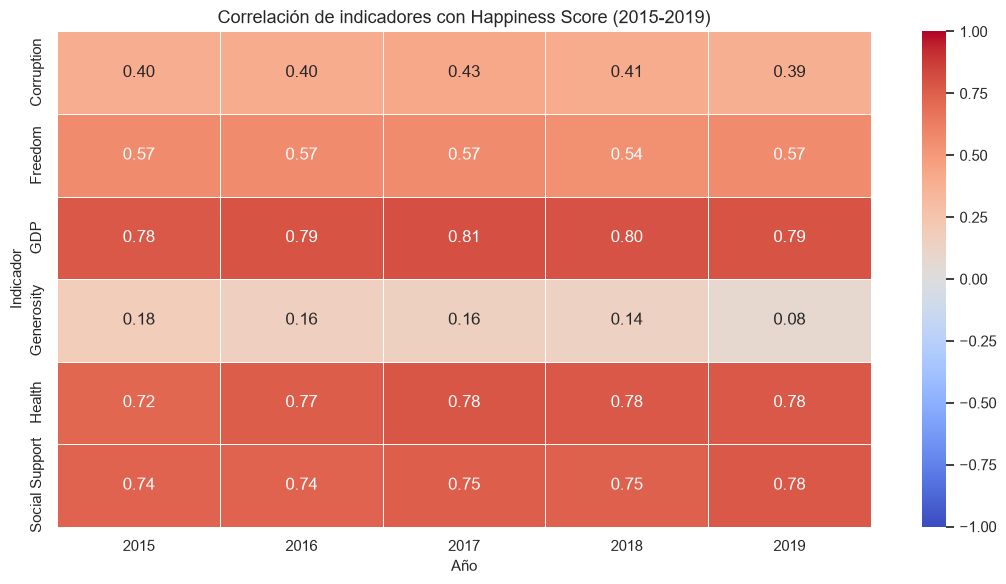

In [113]:
# ============================================================
# 4. HEATMAP DE CORRELACIONES CON HAPPINESS SCORE
# ============================================================

tabla_correlaciones = df_correlaciones_score.pivot(
    index="indicator",
    columns="year",
    values="correlation"
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    tabla_correlaciones,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlación de indicadores con Happiness Score (2015-2019)")
plt.xlabel("Año")
plt.ylabel("Indicador")

plt.tight_layout()
plt.show()

### 3.5. Relaciones entre Happiness Score e indicadores

Se construirán diagramas de dispersión para observar gráficamente
la relación entre Happiness Score y cada indicador socioeconómico.

Se incluirá una línea de regresión como referencia visual para
identificar tendencias lineales, sin asumir relaciones causales.

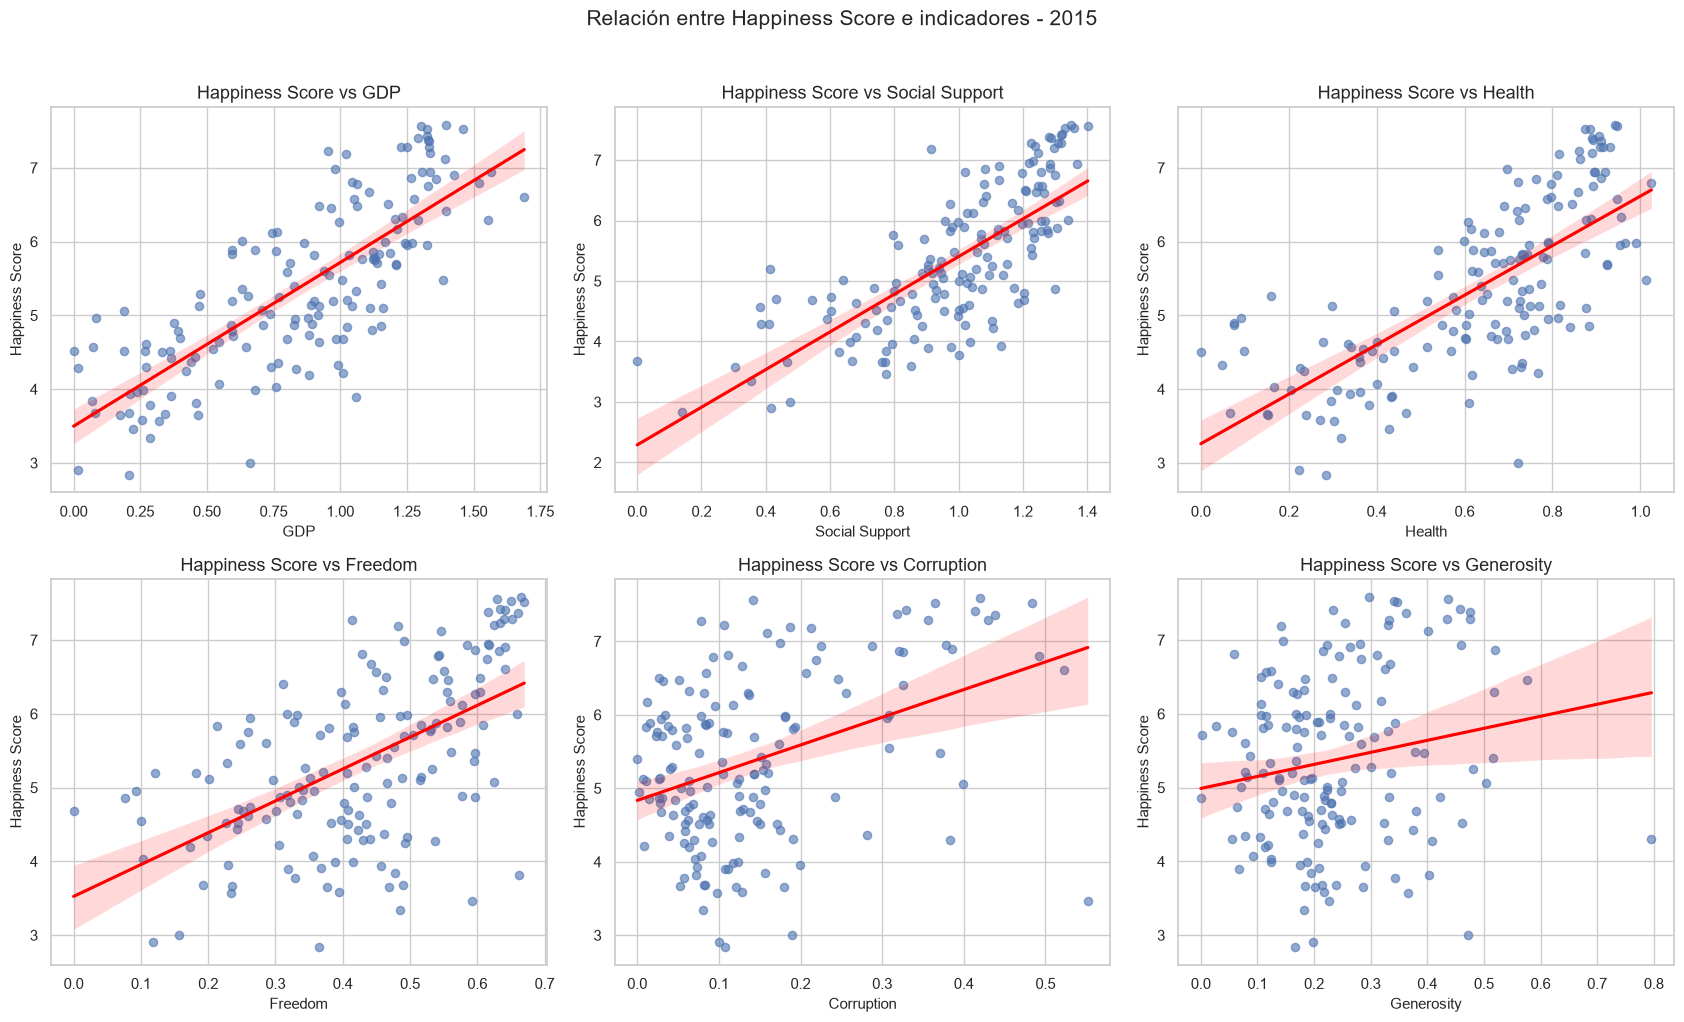

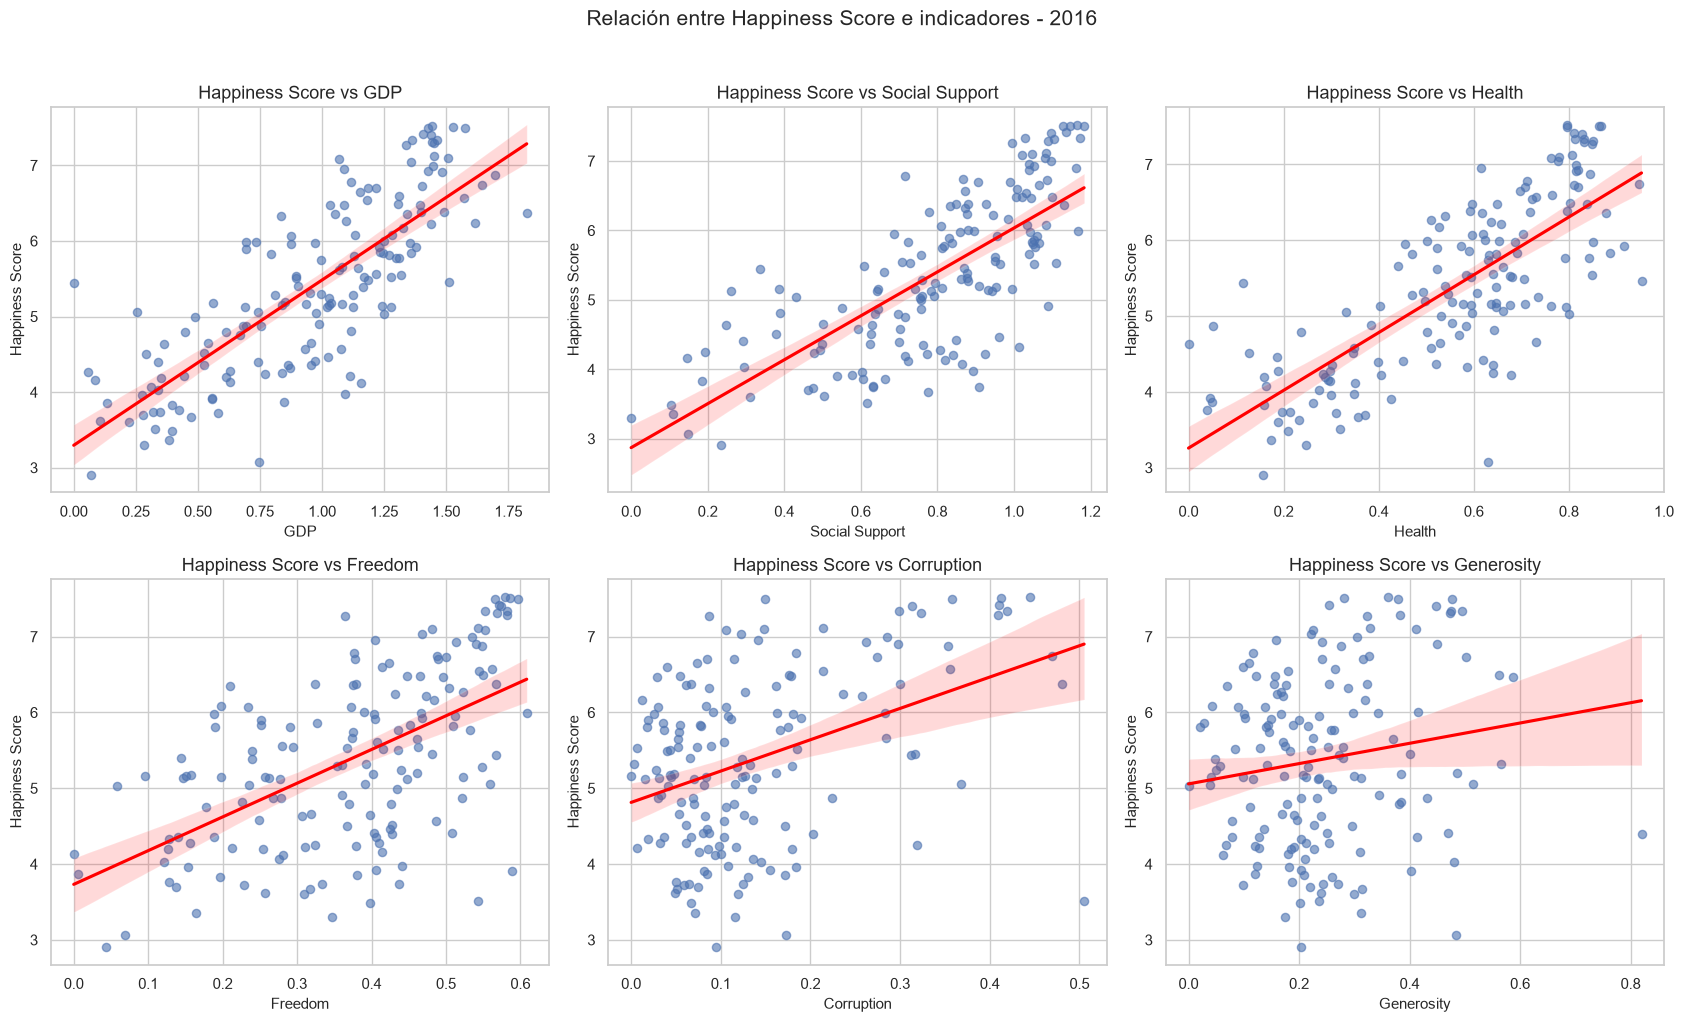

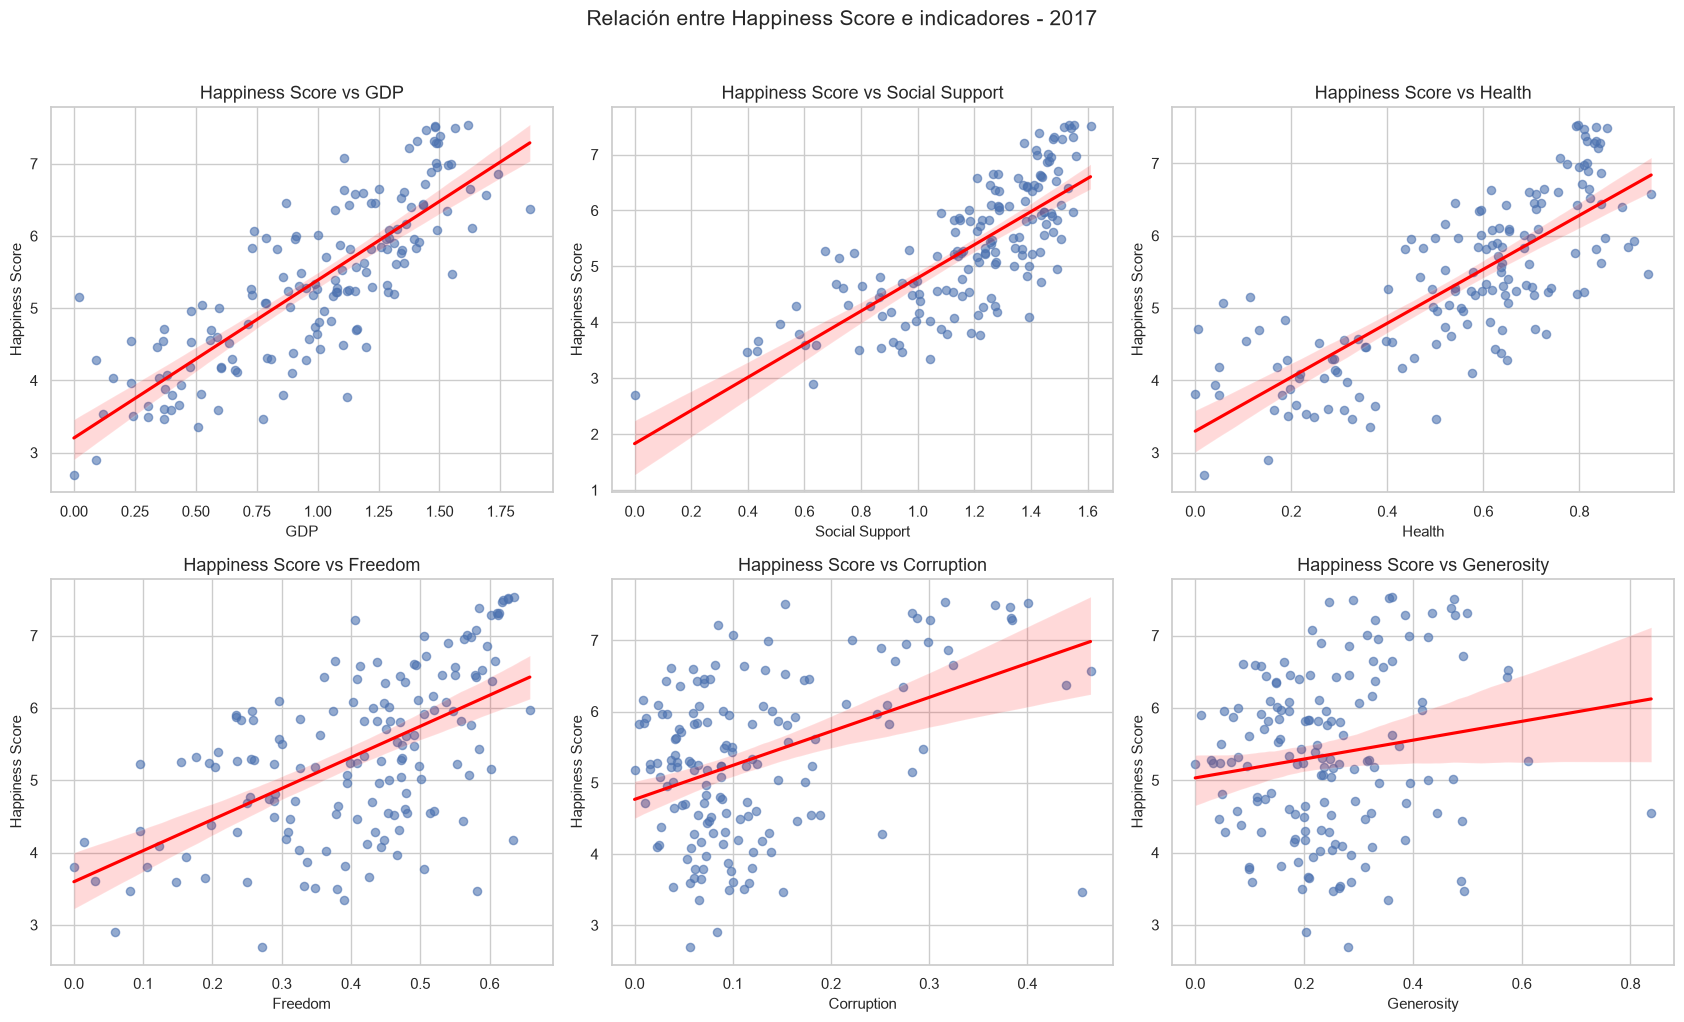

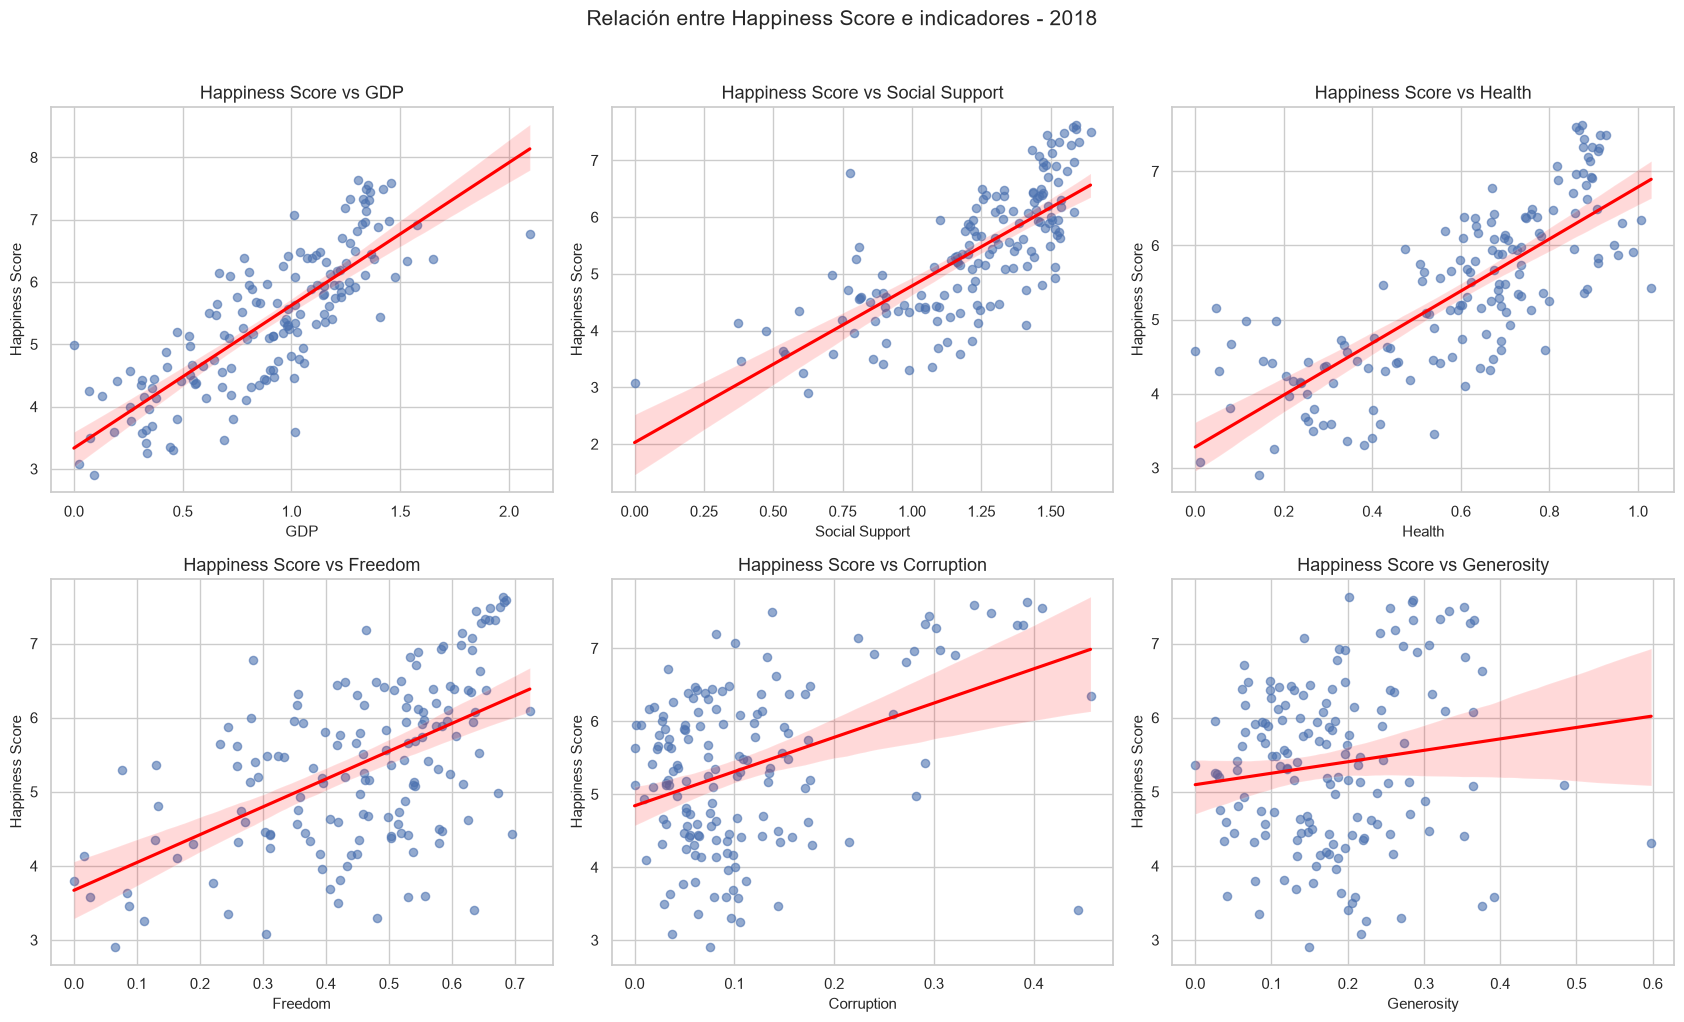

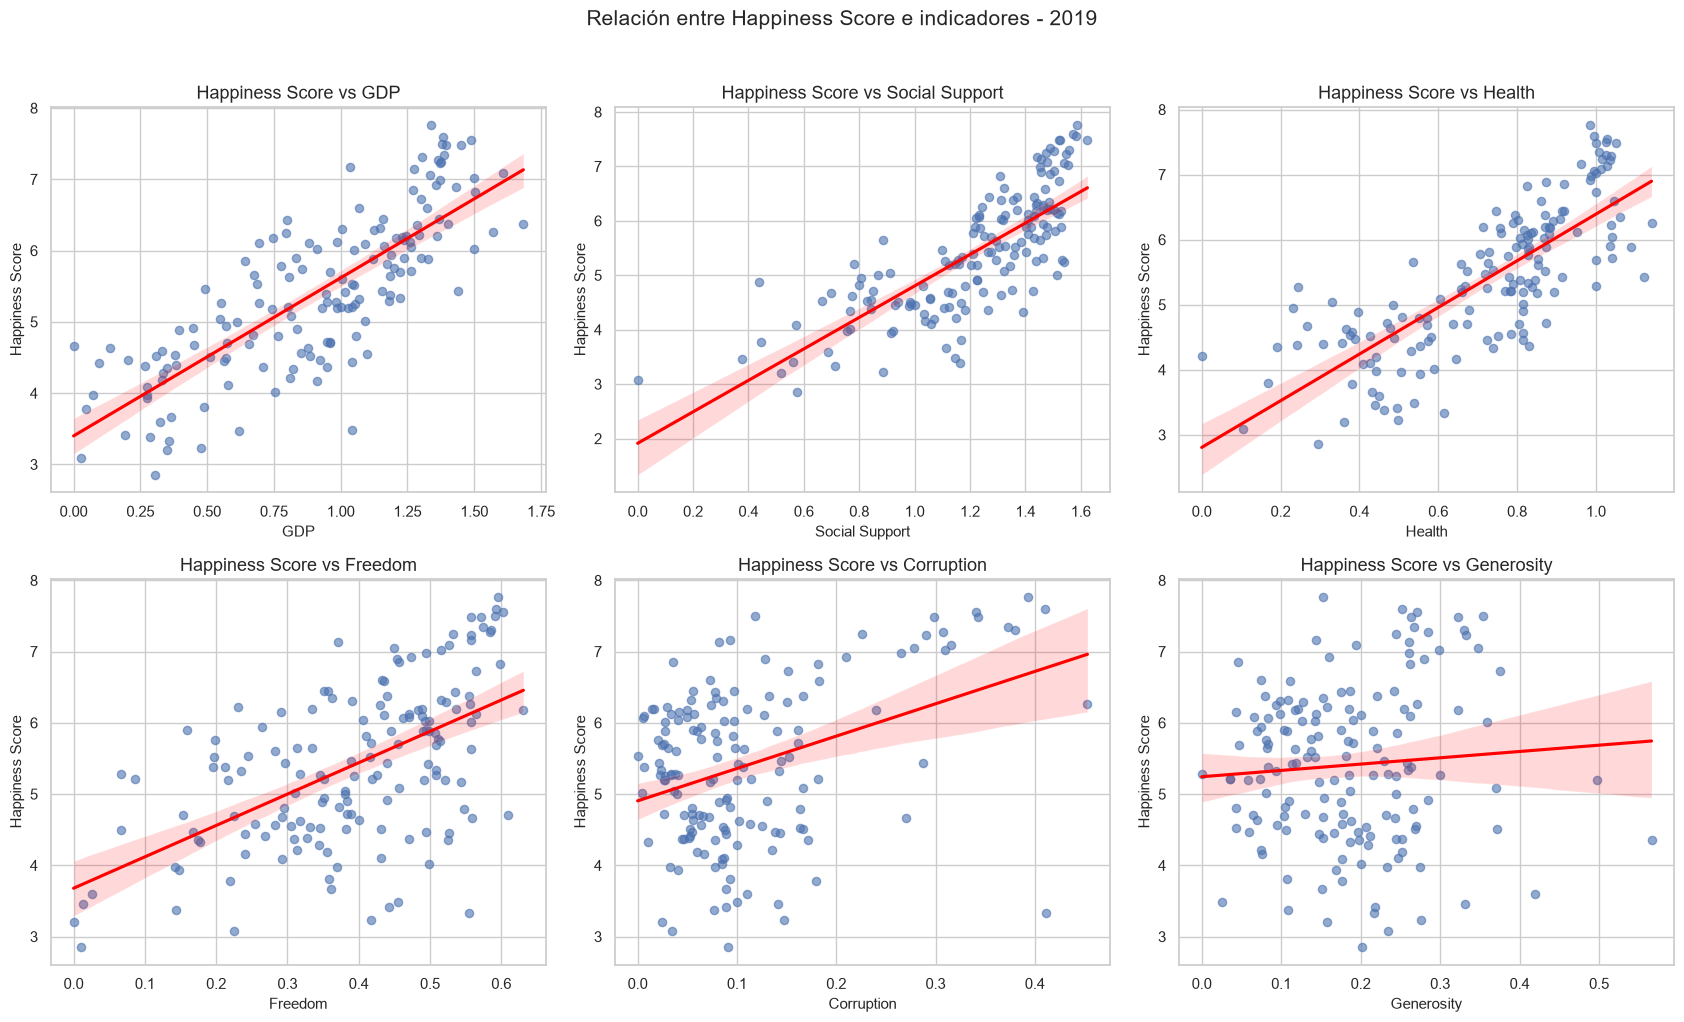

In [114]:
# ============================================================
# 5. DIAGRAMAS DE DISPERSIÓN POR AÑO
# ============================================================

for year in YEARS:

    df_anual = df_relaciones[
        df_relaciones["year"] == year
    ]

    fig, axes = plt.subplots(2, 3, figsize=(17, 10))

    axes = axes.flatten()

    for i, indicador in enumerate(INDICADORES.keys()):

        sns.regplot(
            data=df_anual,
            x=indicador,
            y="happiness_score",
            ax=axes[i],
            scatter_kws={"alpha": 0.6, "s": 35},
            line_kws={"color": "red"}
        )

        axes[i].set_title(
            f"Happiness Score vs {indicador}"
        )

        axes[i].set_xlabel(indicador)
        axes[i].set_ylabel("Happiness Score")

    plt.suptitle(
        f"Relación entre Happiness Score e indicadores - {year}",
        fontsize=15,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

### 3.6. Identificación de asociaciones más fuertes

Se ordenarán las correlaciones de cada año para identificar los
indicadores con asociaciones positivas o negativas más fuertes
respecto a Happiness Score.

In [115]:
# ============================================================
# 6. RANKING DE CORRELACIONES POR AÑO
# ============================================================

for year in YEARS:

    df_anual = df_correlaciones_score[
        df_correlaciones_score["year"] == year
    ].copy()

    df_anual["absolute_correlation"] = (
        df_anual["correlation"].abs()
    )

    df_anual = df_anual.sort_values(
        "absolute_correlation",
        ascending=False
    )

    print(f"\nCorrelaciones - {year}")

    display(
        df_anual[
            ["indicator", "correlation"]
        ].round(3)
    )


Correlaciones - 2015


,indicator,correlation
0,GDP,0.781
1,Social Support,0.741
2,Health,0.724
3,Freedom,0.568
4,Corruption,0.395
5,Generosity,0.180



Correlaciones - 2016


,indicator,correlation
6,GDP,0.790
8,Health,0.765
7,Social Support,0.739
9,Freedom,0.567
10,Corruption,0.402
11,Generosity,0.157



Correlaciones - 2017


,indicator,correlation
12,GDP,0.812
14,Health,0.782
13,Social Support,0.753
15,Freedom,0.570
16,Corruption,0.429
17,Generosity,0.155



Correlaciones - 2018


,indicator,correlation
18,GDP,0.802
20,Health,0.776
19,Social Support,0.746
21,Freedom,0.544
22,Corruption,0.405
23,Generosity,0.136



Correlaciones - 2019


,indicator,correlation
24,GDP,0.794
26,Health,0.780
25,Social Support,0.777
27,Freedom,0.567
28,Corruption,0.386
29,Generosity,0.076


### 3.7. Conclusiones del análisis de relaciones entre indicadores

El análisis de correlación de Pearson durante el periodo 2015-2019
permitió identificar asociaciones positivas entre Happiness Score
y los seis indicadores socioeconómicos estudiados.

GDP, Health y Social Support presentan consistentemente las
correlaciones positivas más elevadas. GDP registra valores entre
0.781 y 0.812, Health entre 0.724 y 0.782, y Social Support entre
0.739 y 0.777.

Freedom mantiene una asociación positiva moderada y estable,
con correlaciones cercanas a 0.56. Corruption presenta asociaciones
positivas de menor intensidad, mientras que Generosity registra
las correlaciones más débiles, mostrando una disminución desde
0.180 en 2015 hasta 0.076 en 2019.

También se identificó una correlación positiva muy fuerte entre
GDP y Health, con valores aproximados de 0.82 a 0.84 durante
las cinco ediciones, lo que evidencia relaciones entre algunos
de los indicadores explicativos.

En general, los resultados muestran patrones de asociación
consistentes entre las variables. Sin embargo, estas relaciones
no implican causalidad y deben interpretarse considerando las
diferencias metodológicas entre las ediciones del informe.

No se eliminaron variables ni observaciones como resultado
de este análisis.

### 4.1. Composición temporal de los países

Se analiza la presencia de los países en las cinco ediciones del World Happiness Report para identificar cuáles tienen registros recurrentes y cuáles aparecen en una única edición. Esto permitirá establecer los conjuntos adecuados para las comparaciones longitudinales.

In [116]:
# ============================================================
# 4.1. IDENTIFICACIÓN DE PAÍSES RECURRENTES
# ============================================================

# Identificar la columna de país y normalizar sus nombres
paises_por_anio = {}

for year in YEARS:
    df = datasets[year]

    columna_pais = (
        "Country" if "Country" in df.columns
        else "Country or region"
    )

    paises = (
        df[columna_pais]
        .dropna()
        .astype(str)
        .str.strip()
    )

    paises_por_anio[year] = set(paises.str.casefold())


# Frecuencia de aparición de cada país
frecuencia_paises = {}

for paises in paises_por_anio.values():
    for pais in paises:
        frecuencia_paises[pais] = (
            frecuencia_paises.get(pais, 0) + 1
        )


# Clasificación de países
resumen_presencia = pd.DataFrame([
    {
        "categoria": "Una edición",
        "cantidad": sum(v == 1 for v in frecuencia_paises.values())
    },
    {
        "categoria": "Dos o más ediciones",
        "cantidad": sum(v >= 2 for v in frecuencia_paises.values())
    },
    {
        "categoria": "Cinco ediciones",
        "cantidad": sum(v == 5 for v in frecuencia_paises.values())
    }
])

print("RESUMEN DE PRESENCIA DE PAÍSES")
display(resumen_presencia)


# Países presentes en las cinco ediciones
paises_comunes = set.intersection(
    *paises_por_anio.values()
)

print(f"\nPaíses presentes en los cinco años: {len(paises_comunes)}")


# Distribución de frecuencia
distribucion_presencia = (
    pd.Series(frecuencia_paises)
    .value_counts()
    .sort_index()
    .rename_axis("numero_ediciones")
    .reset_index(name="cantidad_paises")
)

print("\nDISTRIBUCIÓN POR NÚMERO DE EDICIONES")
display(distribucion_presencia)


# Países compartidos entre años consecutivos
comparacion_consecutiva = []

for anio_actual, anio_siguiente in zip(YEARS[:-1], YEARS[1:]):
    comunes = (
        paises_por_anio[anio_actual]
        & paises_por_anio[anio_siguiente]
    )

    comparacion_consecutiva.append({
        "periodo": f"{anio_actual}-{anio_siguiente}",
        "paises_comunes": len(comunes),
        "paises_solo_anio_inicial": len(
            paises_por_anio[anio_actual] - paises_por_anio[anio_siguiente]
        ),
        "paises_solo_anio_final": len(
            paises_por_anio[anio_siguiente] - paises_por_anio[anio_actual]
        )
    })

df_comparacion_presencia = pd.DataFrame(comparacion_consecutiva)

print("\nCOMPARACIÓN ENTRE AÑOS CONSECUTIVOS")
display(df_comparacion_presencia)

RESUMEN DE PRESENCIA DE PAÍSES


,categoria,cantidad
0,Una edición,7
1,Dos o más ediciones,162
2,Cinco ediciones,141



Países presentes en los cinco años: 141

DISTRIBUCIÓN POR NÚMERO DE EDICIONES


,numero_ediciones,cantidad_paises
0,1,7
1,2,5
2,3,4
3,4,12
4,5,141



COMPARACIÓN ENTRE AÑOS CONSECUTIVOS


,periodo,paises_comunes,paises_solo_anio_inicial,paises_solo_anio_final
0,2015-2016,152,6,5
1,2016-2017,150,7,5
2,2017-2018,151,4,5
3,2018-2019,152,4,4


### 4.2. Evolución de Happiness Score en el panel común

Se compara la evolución anual del Happiness Score utilizando exclusivamente los países presentes en las cinco ediciones. Los resultados se contrastan con las estadísticas generales de cada año para identificar posibles diferencias asociadas a cambios en la composición de países.

ESTADÍSTICAS DEL PANEL COMÚN


,year,count,mean,median,std,min,max
0,2015,141,5.407,5.286,1.170,2.839,7.587
1,2016,141,5.398,5.314,1.160,2.905,7.526
2,2017,141,5.408,5.311,1.123,2.905,7.537
3,2018,141,5.440,5.472,1.110,2.905,7.632
4,2019,141,5.485,5.467,1.096,3.203,7.769



COMPARACIÓN ENTRE PANEL COMÚN Y TOTAL ANUAL


,year,media_panel,mediana_panel,media_general,mediana_general,diferencia_media,diferencia_mediana
0,2015,5.407,5.286,5.376,5.232,0.031,0.053
1,2016,5.398,5.314,5.382,5.314,0.016,0.000
2,2017,5.408,5.311,5.354,5.279,0.054,0.032
3,2018,5.440,5.472,5.376,5.378,0.064,0.094
4,2019,5.485,5.467,5.407,5.380,0.078,0.087


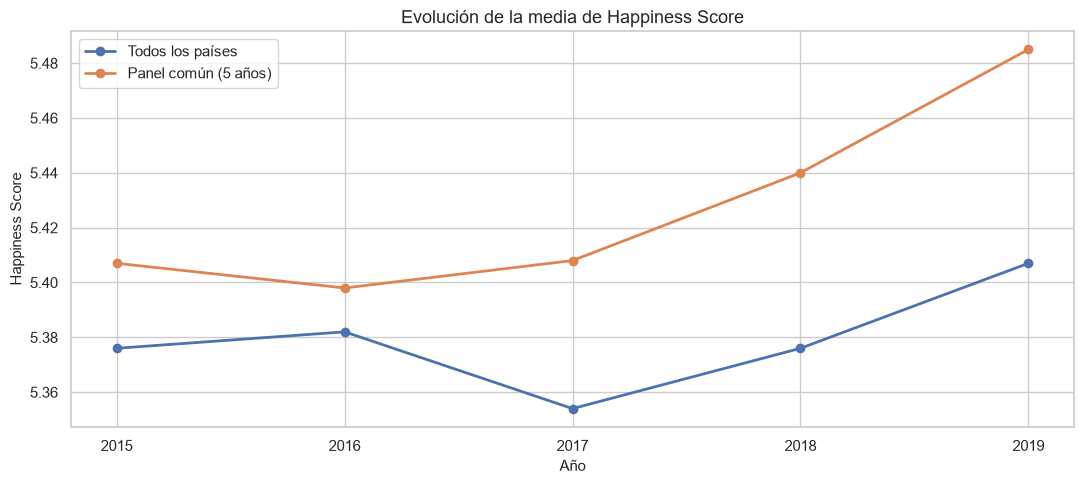

In [117]:
# ============================================================
# 4.2. EVOLUCIÓN DE HAPPINESS SCORE EN EL PANEL COMÚN
# ============================================================

# Construir dataset con países presentes en los cinco años
datos_panel = []

for year in YEARS:
    df = datasets[year]

    columna_pais = (
        "Country" if "Country" in df.columns
        else "Country or region"
    )

    temporal = pd.DataFrame({
        "year": year,
        "country": df[columna_pais].astype(str).str.strip(),
        "happiness_score": df[COLUMNAS_SCORE[year]]
    })

    temporal["country_normalizado"] = (
        temporal["country"].str.casefold()
    )

    temporal = temporal[
        temporal["country_normalizado"].isin(paises_comunes)
    ]

    datos_panel.append(temporal)

df_panel = pd.concat(datos_panel, ignore_index=True)


# Estadísticas anuales del panel común
estadisticas_panel = (
    df_panel.groupby("year")["happiness_score"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .reset_index()
    .round(3)
)

print("ESTADÍSTICAS DEL PANEL COMÚN")
display(estadisticas_panel)


# Estadísticas generales de cada año
estadisticas_generales = []

for year in YEARS:
    score = datasets[year][COLUMNAS_SCORE[year]]

    estadisticas_generales.append({
        "year": year,
        "count": score.count(),
        "mean": score.mean(),
        "median": score.median()
    })

df_generales = pd.DataFrame(estadisticas_generales)


# Comparación entre panel común y población disponible
comparacion_medias = (
    estadisticas_panel[["year", "mean", "median"]]
    .rename(columns={
        "mean": "media_panel",
        "median": "mediana_panel"
    })
    .merge(
        df_generales[["year", "mean", "median"]],
        on="year"
    )
    .rename(columns={
        "mean": "media_general",
        "median": "mediana_general"
    })
)

comparacion_medias["diferencia_media"] = (
    comparacion_medias["media_panel"]
    - comparacion_medias["media_general"]
)

comparacion_medias["diferencia_mediana"] = (
    comparacion_medias["mediana_panel"]
    - comparacion_medias["mediana_general"]
)

comparacion_medias = comparacion_medias.round(3)

print("\nCOMPARACIÓN ENTRE PANEL COMÚN Y TOTAL ANUAL")
display(comparacion_medias)


# Visualización de medias
plt.figure(figsize=(11, 5))

plt.plot(
    comparacion_medias["year"],
    comparacion_medias["media_general"],
    marker="o",
    linewidth=2,
    label="Todos los países"
)

plt.plot(
    comparacion_medias["year"],
    comparacion_medias["media_panel"],
    marker="o",
    linewidth=2,
    label="Panel común (5 años)"
)

plt.title("Evolución de la media de Happiness Score")
plt.xlabel("Año")
plt.ylabel("Happiness Score")
plt.xticks(YEARS)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusiones

El análisis del panel común de 141 países permite observar una evolución ligeramente positiva del Happiness Score entre 2015 y 2019. Aunque se presenta una pequeña disminución en 2016, a partir de 2017 se observa una tendencia ascendente, alcanzando una media de 5.485 en 2019 frente a 5.407 en 2015.

Al comparar estos resultados con las estadísticas generales de cada edición, se identifica que el panel común presenta medias superiores en todos los años. La diferencia aumenta progresivamente, pasando de 0.031 puntos en 2015 a 0.078 en 2019. Esto evidencia que la composición de países puede influir en las estadísticas agregadas y justifica la utilización de conjuntos comparables para los análisis longitudinales.

Adicionalmente, la desviación estándar del panel disminuye de 1.170 a 1.096, lo que refleja una menor dispersión del Happiness Score entre los países analizados.

Estos resultados describen tendencias agregadas y no permiten determinar qué países experimentaron mejoras o deterioros individuales. Para ello se requiere analizar los cambios de cada país entre las distintas ediciones.

### 4.3. Cambios individuales de Happiness Score (2015–2019)

Se comparan los resultados de Happiness Score de los países presentes en las cinco ediciones, calculando la variación absoluta y porcentual entre 2015 y 2019. El objetivo es identificar los países con mayores incrementos y disminuciones durante el periodo.

In [118]:
# ============================================================
# 4.3. CAMBIOS INDIVIDUALES DE HAPPINESS SCORE (2015-2019)
# ============================================================

# Construir tabla de comparación por país
comparacion_2015_2019 = df_panel[
    df_panel["year"].isin([2015, 2019])
].pivot(
    index="country_normalizado",
    columns="year",
    values="happiness_score"
).reset_index()

# Recuperar nombres de países
nombres_paises = (
    df_panel[["country_normalizado", "country"]]
    .drop_duplicates("country_normalizado")
    .set_index("country_normalizado")["country"]
)

comparacion_2015_2019["country"] = (
    comparacion_2015_2019["country_normalizado"]
    .map(nombres_paises)
)

# Calcular variaciones
comparacion_2015_2019["variacion_absoluta"] = (
    comparacion_2015_2019[2019]
    - comparacion_2015_2019[2015]
)

comparacion_2015_2019["variacion_porcentual"] = (
    comparacion_2015_2019["variacion_absoluta"]
    / comparacion_2015_2019[2015]
) * 100

# Ordenar por variación
comparacion_2015_2019 = (
    comparacion_2015_2019
    .sort_values("variacion_absoluta", ascending=False)
    .reset_index(drop=True)
)

# Mostrar columnas relevantes
columnas_resultado = [
    "country",
    2015,
    2019,
    "variacion_absoluta",
    "variacion_porcentual"
]

print("PAÍSES CON MAYORES INCREMENTOS")
display(
    comparacion_2015_2019[columnas_resultado]
    .head(10)
    .round(3)
)

print("\nPAÍSES CON MAYORES DISMINUCIONES")
display(
    comparacion_2015_2019[columnas_resultado]
    .tail(10)
    .sort_values("variacion_absoluta")
    .round(3)
)

# Resumen general de variaciones
print("\nRESUMEN DE VARIACIONES")

display(
    comparacion_2015_2019["variacion_absoluta"]
    .describe()
    .round(3)
)

# Clasificación de cambios
comparacion_2015_2019["tipo_cambio"] = (
    comparacion_2015_2019["variacion_absoluta"]
    .apply(
        lambda x: (
            "Incremento" if x > 0
            else "Disminución" if x < 0
            else "Sin cambio"
        )
    )
)

print("\nCLASIFICACIÓN DE PAÍSES")
display(
    comparacion_2015_2019["tipo_cambio"]
    .value_counts()
    .rename_axis("tipo_cambio")
    .reset_index(name="cantidad_paises")
)

PAÍSES CON MAYORES INCREMENTOS


year,country,2015,2019,variacion_absoluta,variacion_porcentual
0,Benin,3.340,4.883,1.543,46.198
1,Ivory Coast,3.655,4.944,1.289,35.267
2,Togo,2.839,4.085,1.246,43.889
3,Honduras,4.788,5.860,1.072,22.389
4,Burkina Faso,3.587,4.587,1.000,27.878
5,Hungary,4.800,5.758,0.958,19.958
6,Romania,5.124,6.070,0.946,18.462
7,Gabon,3.896,4.799,0.903,23.178
8,Cambodia,3.819,4.700,0.881,23.069
9,Guinea,3.656,4.534,0.878,24.015



PAÍSES CON MAYORES DISMINUCIONES


year,country,2015,2019,variacion_absoluta,variacion_porcentual
140,Venezuela,6.810,4.707,-2.103,-30.881
139,Zambia,5.129,4.107,-1.022,-19.926
138,Zimbabwe,4.610,3.663,-0.947,-20.542
137,Haiti,4.518,3.597,-0.921,-20.385
136,Malawi,4.292,3.410,-0.882,-20.550
135,Botswana,4.332,3.488,-0.844,-19.483
134,Yemen,4.077,3.380,-0.697,-17.096
133,Brazil,6.983,6.300,-0.683,-9.781
132,Liberia,4.571,3.975,-0.596,-13.039
131,Mexico,7.187,6.595,-0.592,-8.237



RESUMEN DE VARIACIONES


count    141.000
mean       0.079
std        0.507
min       -2.103
25%       -0.226
50%        0.041
75%        0.363
max        1.543
Name: variacion_absoluta, dtype: float64


CLASIFICACIÓN DE PAÍSES


,tipo_cambio,cantidad_paises
0,Incremento,75
1,Disminución,66


### Conclusiones

La comparación individual del Happiness Score entre 2015 y 2019 evidencia una evolución heterogénea entre los 141 países del panel común.

Se identificaron 75 países con incrementos y 66 con disminuciones. Entre los mayores incrementos destacan Benin (+1.543), Ivory Coast (+1.289) y Togo (+1.246). Por el contrario, Venezuela presentó la mayor disminución (-2.103), seguida de Zambia (-1.022) y Zimbabwe (-0.947).

La variación media fue de +0.079 puntos y la mediana de +0.041, lo que indica una tendencia agregada ligeramente positiva. Sin embargo, la desviación estándar de 0.507 evidencia diferencias importantes entre las trayectorias individuales.

Estos resultados muestran que el incremento general del Happiness Score no representa una mejora uniforme para todos los países. Es necesario considerar las diferencias individuales y evitar interpretar los cambios del indicador como una medición directa de la evolución de la felicidad real de las poblaciones.

### 4.4. Variaciones de Happiness Score entre años consecutivos

Se calculan las variaciones absolutas del Happiness Score entre ediciones consecutivas para los países presentes en ambos años. Este análisis permite identificar cambios interanuales, observar la continuidad de las tendencias y detectar diferencias respecto a la comparación global de 2015 a 2019.

In [119]:
# ============================================================
# 4.4. VARIACIONES ENTRE AÑOS CONSECUTIVOS
# ============================================================

variaciones_anuales = []

for anio_inicial, anio_final in zip(YEARS[:-1], YEARS[1:]):

    df_inicial = df_panel[
        df_panel["year"] == anio_inicial
    ][["country_normalizado", "country", "happiness_score"]]

    df_final = df_panel[
        df_panel["year"] == anio_final
    ][["country_normalizado", "happiness_score"]]

    comparacion = df_inicial.merge(
        df_final,
        on="country_normalizado",
        suffixes=("_inicial", "_final")
    )

    comparacion["periodo"] = (
        f"{anio_inicial}-{anio_final}"
    )

    comparacion["variacion_absoluta"] = (
        comparacion["happiness_score_final"]
        - comparacion["happiness_score_inicial"]
    )

    variaciones_anuales.append(comparacion)


df_variaciones_anuales = pd.concat(
    variaciones_anuales,
    ignore_index=True
)


# Resumen estadístico por periodo
resumen_variaciones = (
    df_variaciones_anuales
    .groupby("periodo")
    .agg(
        paises=("country_normalizado", "nunique"),
        media=("variacion_absoluta", "mean"),
        mediana=("variacion_absoluta", "median"),
        desviacion=("variacion_absoluta", "std"),
        minimo=("variacion_absoluta", "min"),
        maximo=("variacion_absoluta", "max")
    )
    .round(3)
    .reset_index()
)

print("RESUMEN DE VARIACIONES INTERANUALES")
display(resumen_variaciones)


# Cantidad de países que aumentaron o disminuyeron
clasificacion_anual = (
    df_variaciones_anuales
    .assign(
        tipo_cambio=lambda x: x["variacion_absoluta"].apply(
            lambda v: (
                "Incremento" if v > 0
                else "Disminución" if v < 0
                else "Sin cambio"
            )
        )
    )
    .groupby(["periodo", "tipo_cambio"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("\nCLASIFICACIÓN DE CAMBIOS POR PERIODO")
display(clasificacion_anual)


# Diez mayores incrementos y disminuciones de cada periodo

for periodo in df_variaciones_anuales["periodo"].unique():

    temporal = df_variaciones_anuales[
        df_variaciones_anuales["periodo"] == periodo
    ]

    columnas_resultado = [
        "country",
        "happiness_score_inicial",
        "happiness_score_final",
        "variacion_absoluta"
    ]

    print(f"\nMAYORES INCREMENTOS: {periodo}")

    display(
        temporal.nlargest(
            5, "variacion_absoluta"
        )[columnas_resultado].round(3)
    )

    print(f"MAYORES DISMINUCIONES: {periodo}")

    display(
        temporal.nsmallest(
            5, "variacion_absoluta"
        )[columnas_resultado].round(3)
    )

RESUMEN DE VARIACIONES INTERANUALES


,periodo,paises,media,mediana,desviacion,minimo,maximo
0,2015-2016,141,-0.009,-0.001,0.218,-0.949,0.750
1,2016-2017,141,0.010,0.001,0.181,-0.834,0.497
2,2017-2018,141,0.032,0.018,0.194,-0.577,0.579
3,2018-2019,141,0.045,0.033,0.202,-0.983,0.870



CLASIFICACIÓN DE CAMBIOS POR PERIODO


tipo_cambio,periodo,Disminución,Incremento,Sin cambio
0,2015-2016,71,69,1
1,2016-2017,69,71,1
2,2017-2018,62,79,0
3,2018-2019,53,84,4



MAYORES INCREMENTOS: 2015-2016


,country,happiness_score_inicial,happiness_score_final,variacion_absoluta
62,Algeria,5.605,6.355,0.750
140,Togo,2.839,3.303,0.464
82,Latvia,5.098,5.560,0.462
79,Romania,5.124,5.528,0.404
91,Hungary,4.800,5.145,0.345


... (10 outputs left out)


MAYORES INCREMENTOS: 2018-2019


,country,happiness_score_inicial,happiness_score_final,variacion_absoluta
563,Burundi,2.905,3.775,0.870
548,Benin,4.141,4.883,0.742
551,Guinea,3.964,4.534,0.570
558,Liberia,3.495,3.975,0.480
546,Niger,4.166,4.628,0.462


MAYORES DISMINUCIONES: 2018-2019


,country,happiness_score_inicial,happiness_score_final,variacion_absoluta
456,Malaysia,6.322,5.339,-0.983
554,Afghanistan,3.632,3.203,-0.429
486,Turkmenistan,5.636,5.247,-0.389
450,Argentina,6.388,6.086,-0.302
537,Zambia,4.377,4.107,-0.270


### Conclusiones

El análisis de las variaciones interanuales del Happiness Score muestra una evolución progresivamente positiva durante el periodo estudiado.

Entre 2015 y 2016 se registró una variación media de -0.009 puntos, con predominio de países que experimentaron disminuciones. En el periodo 2016-2017 el promedio pasó a ser positivo (+0.010), tendencia que se fortaleció en los dos periodos siguientes, alcanzando +0.045 puntos entre 2018 y 2019.

También se observa un incremento progresivo en la cantidad de países con variaciones positivas, pasando de 69 en el primer periodo a 84 en el último. La desviación estándar se mantuvo relativamente estable, lo que indica que continuaron existiendo diferencias importantes entre las trayectorias individuales.

En conjunto, estos resultados respaldan la tendencia positiva observada en el análisis agregado del panel común, aunque evidencian que la evolución no fue homogénea entre países.

### 5.1. Evolución longitudinal de los indicadores

Se construye una tabla longitudinal con los seis indicadores socioeconómicos y Happiness Score para los 141 países presentes en las cinco ediciones. Se calcularán estadísticas descriptivas por año para examinar la evolución de sus valores promedio y dispersión durante el periodo 2015-2019.

In [120]:
# ============================================================
# 5.1. CONSTRUCCIÓN DEL PANEL LONGITUDINAL DE INDICADORES
# ============================================================

datos_longitudinales = []

for year in YEARS:

    df = datasets[year]

    columna_pais = (
        "Country" if "Country" in df.columns
        else "Country or region"
    )

    temporal = pd.DataFrame({
        "year": year,
        "country": df[columna_pais].astype(str).str.strip(),
        "happiness_score": df[COLUMNAS_SCORE[year]]
    })

    temporal["country_normalizado"] = (
        temporal["country"].str.casefold()
    )

    # Incorporar los seis indicadores
    for indicador, columnas in INDICADORES.items():
        temporal[indicador] = df[columnas[year]]

    # Conservar exclusivamente el panel común
    temporal = temporal[
        temporal["country_normalizado"].isin(paises_comunes)
    ]

    datos_longitudinales.append(temporal)


df_longitudinal = pd.concat(
    datos_longitudinales,
    ignore_index=True
)


# Validaciones básicas
print("DIMENSIONES DEL PANEL LONGITUDINAL")
print(df_longitudinal.shape)

print("\nPAÍSES POR AÑO")
display(
    df_longitudinal.groupby("year")["country_normalizado"]
    .nunique()
)

print("\nVALORES FALTANTES")
display(
    df_longitudinal[
        ["happiness_score"] + list(INDICADORES.keys())
    ].isna().sum()
)

print("\nVISTA DEL DATASET")
display(df_longitudinal.head())

DIMENSIONES DEL PANEL LONGITUDINAL
(705, 10)

PAÍSES POR AÑO


year
2015    141
2016    141
2017    141
2018    141
2019    141
Name: country_normalizado, dtype: int64


VALORES FALTANTES


happiness_score    0
GDP                0
Social Support     0
Health             0
Freedom            0
Corruption         1
Generosity         0
dtype: int64


VISTA DEL DATASET


,year,country,happiness_score,country_normalizado,GDP,Social Support,Health,Freedom,Corruption,Generosity
0,2015,Switzerland,7.587,switzerland,1.39651,1.34951,0.94143,0.66557,0.41978,0.29678
1,2015,Iceland,7.561,iceland,1.30232,1.40223,0.94784,0.62877,0.14145,0.43630
2,2015,Denmark,7.527,denmark,1.32548,1.36058,0.87464,0.64938,0.48357,0.34139
3,2015,Norway,7.522,norway,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699
4,2015,Canada,7.427,canada,1.32629,1.32261,0.90563,0.63297,0.32957,0.45811


### 5.2. Estadísticas descriptivas longitudinales

Se calculan la media, mediana, desviación estándar, mínimo y máximo de cada indicador para los cinco años. Esto permitirá identificar tendencias agregadas y cambios en la dispersión de los valores entre los países del panel común.

In [121]:
# ============================================================
# 5.2. ESTADÍSTICAS DESCRIPTIVAS POR INDICADOR Y AÑO
# ============================================================

INDICADORES_ANALISIS = [
    "happiness_score",
    "GDP",
    "Social Support",
    "Health",
    "Freedom",
    "Corruption",
    "Generosity"
]

resumen_longitudinal = (
    df_longitudinal
    .groupby("year")[INDICADORES_ANALISIS]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(3)
)

print("ESTADÍSTICAS LONGITUDINALES")
display(resumen_longitudinal)

ESTADÍSTICAS LONGITUDINALES


happiness_score                                      GDP                \
               count   mean median    std    min    max count   mean median   
year                                                                          
2015             141  5.407  5.286  1.170  2.839  7.587   141  0.861  0.920   
2016             141  5.398  5.314  1.160  2.905  7.526   141  0.963  1.030   
2017             141  5.408  5.311  1.123  2.905  7.537   141  1.002  1.075   
2018             141  5.440  5.472  1.110  2.905  7.632   141  0.909  0.975   
2019             141  5.485  5.467  1.096  3.203  7.769   141  0.928  0.987   

             ... Corruption                    Generosity                \
        std  ...     median    std  min    max      count   mean median   
year         ...                                                          
2015  0.395  ...      0.105  0.120  0.0  0.552        141  0.236  0.215   
2016  0.407  ...      0.103  0.112  0.0  0.505        141  0.241  0.217   
2017  0.408  ...      0.088  0.104  0.0  0.464        141  0.247  0.229   
2018  0.382  ...      0.082  0.098  0.0  0.457        141  0.182  0.172   
2019  0.382  ...      0.082  0.096  0.0  0.453        141  0.183  0.175   

                         
        std  min    max  
year                     
2015  0.129  0.0  0.796  
2016  0.136  0.0  0.820  
2017  0.139  0.0  0.838  
2018  0.102  0.0  0.598  
2019  0.098  0.0  0.566  

[5 rows x 42 columns]

### 5.3. Tendencias temporales de los indicadores

Se representan las medias anuales de Happiness Score y los seis indicadores para identificar tendencias crecientes, decrecientes o relativamente estables durante el periodo 2015-2019.

,happiness_score,GDP,Social Support,Health,Freedom,Corruption,Generosity
year,,,,,,,
2015,5.407,0.861,1.000,0.649,0.431,0.140,0.236
2016,5.398,0.963,0.802,0.568,0.372,0.136,0.241
2017,5.408,1.002,1.206,0.569,0.413,0.123,0.247
2018,5.440,0.909,1.230,0.615,0.459,0.111,0.182
2019,5.485,0.928,1.229,0.747,0.396,0.109,0.183


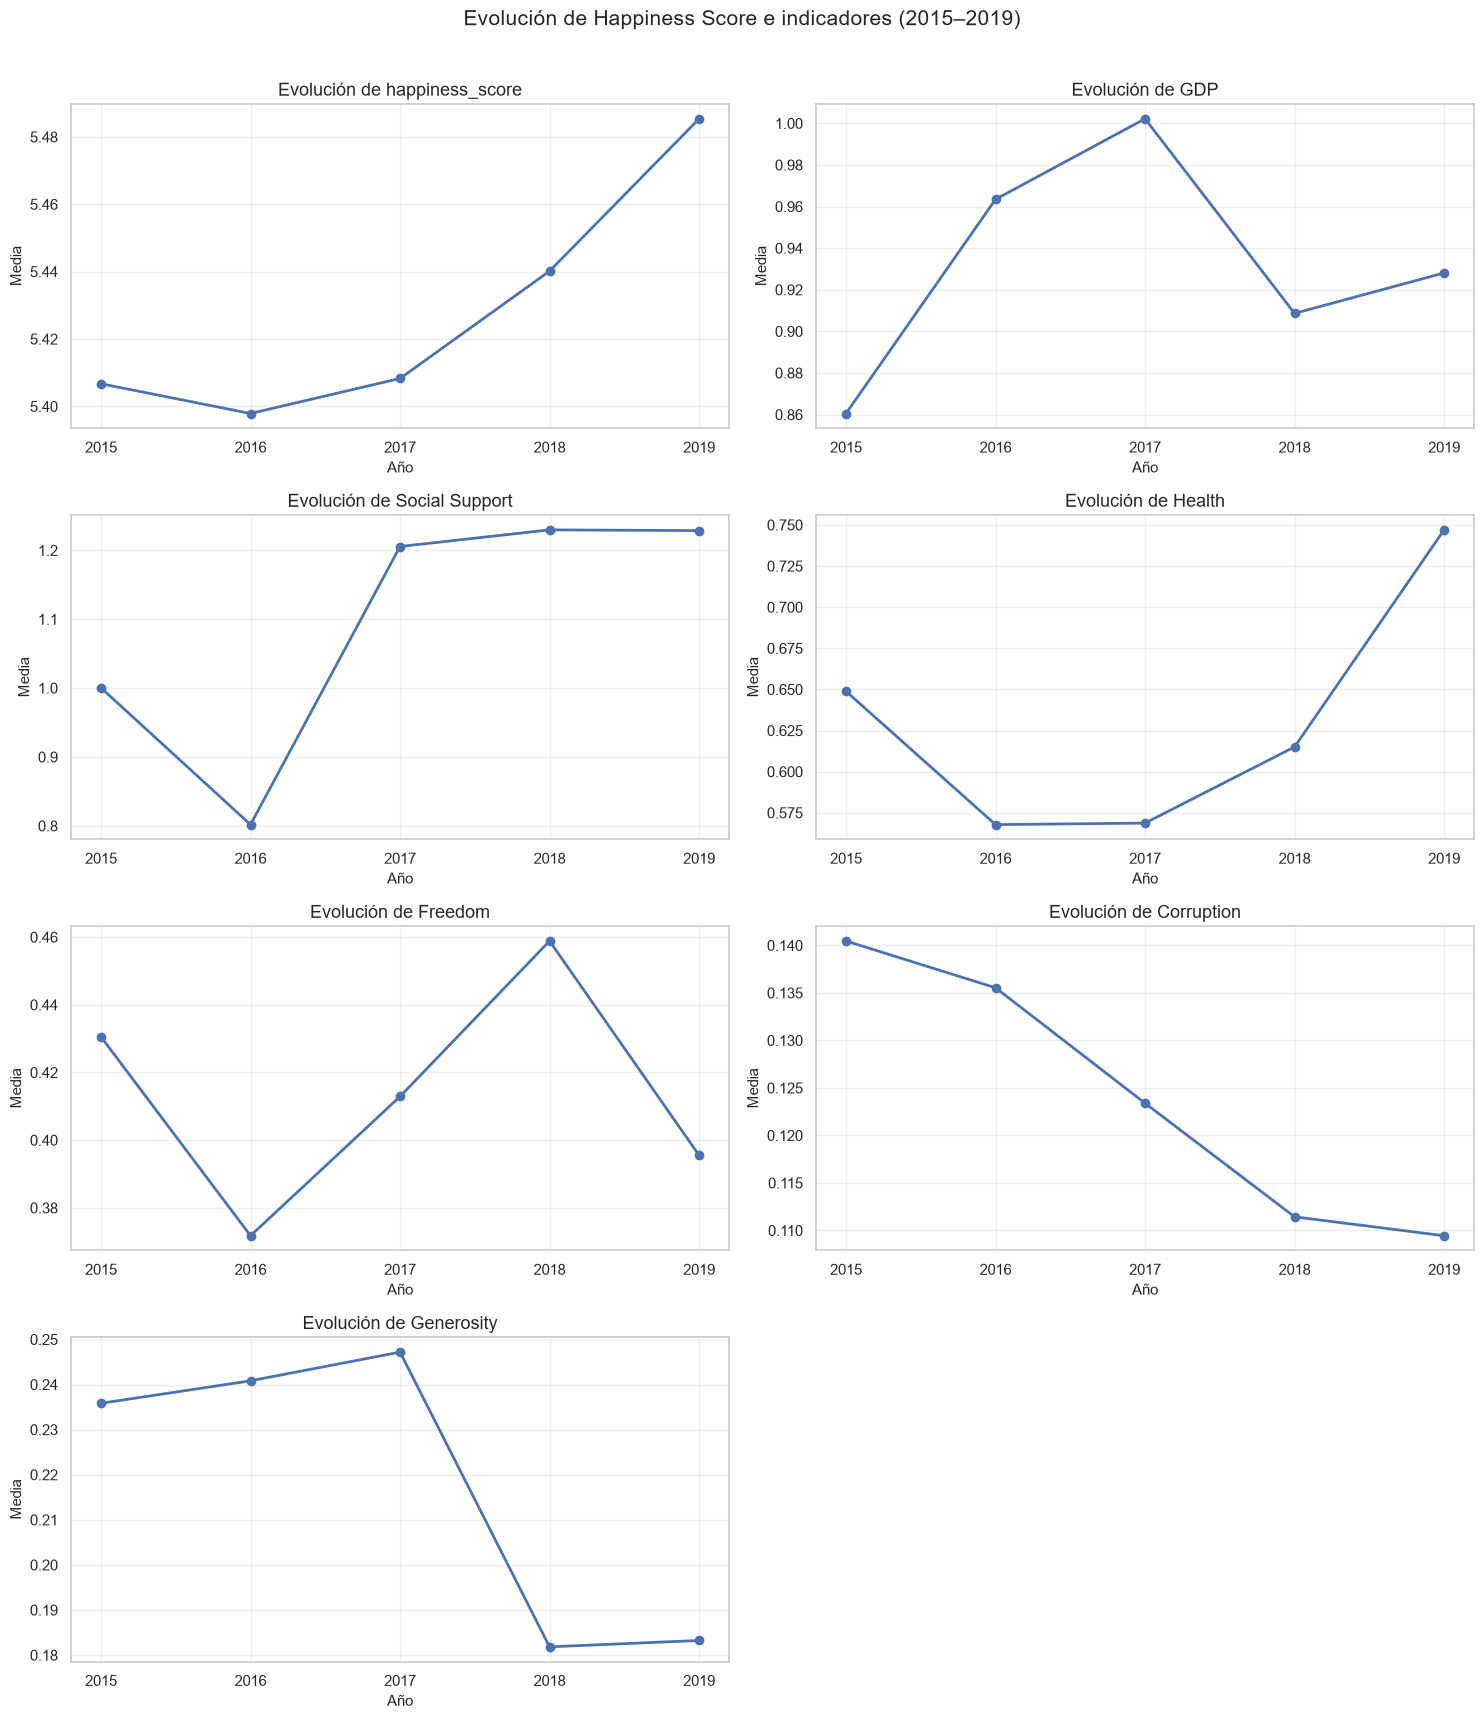

In [122]:
# ============================================================
# 5.3. EVOLUCIÓN TEMPORAL DE LOS INDICADORES
# ============================================================

# Calcular la media anual de cada indicador
medias_longitudinales = (
    df_longitudinal
    .groupby("year")[INDICADORES_ANALISIS]
    .mean()
)

display(medias_longitudinales.round(3))

# Crear gráficos independientes
fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 17)
)

axes = axes.flatten()

for i, indicador in enumerate(INDICADORES_ANALISIS):

    axes[i].plot(
        medias_longitudinales.index,
        medias_longitudinales[indicador],
        marker="o",
        linewidth=2
    )

    axes[i].set_title(f"Evolución de {indicador}")
    axes[i].set_xlabel("Año")
    axes[i].set_ylabel("Media")
    axes[i].set_xticks(YEARS)
    axes[i].grid(True, alpha=0.3)

# Ocultar el último espacio sin gráfico
axes[-1].set_visible(False)

plt.suptitle(
    "Evolución de Happiness Score e indicadores (2015–2019)",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()



### 5.4. Variaciones acumuladas de los indicadores (2015-2019)

Se comparan las medias de los indicadores en 2015 y 2019 para calcular sus variaciones absolutas y porcentuales. El objetivo es identificar cuáles experimentaron incrementos o disminuciones agregadas durante el periodo.

In [123]:
# ============================================================
# 5.4. VARIACIONES ACUMULADAS 2015-2019
# ============================================================

medias_por_anio = (
    df_longitudinal
    .groupby("year")[INDICADORES_ANALISIS]
    .mean()
)

resultado_variaciones = []

for indicador in INDICADORES_ANALISIS:

    valor_2015 = medias_por_anio.loc[2015, indicador]
    valor_2019 = medias_por_anio.loc[2019, indicador]

    variacion_absoluta = valor_2019 - valor_2015

    variacion_porcentual = (
        (variacion_absoluta / valor_2015) * 100
        if valor_2015 != 0 else float("nan")
    )

    resultado_variaciones.append({
        "indicador": indicador,
        "media_2015": valor_2015,
        "media_2019": valor_2019,
        "variacion_absoluta": variacion_absoluta,
        "variacion_porcentual": variacion_porcentual
    })


df_variaciones_indicadores = (
    pd.DataFrame(resultado_variaciones)
    .round(3)
)

print("VARIACIONES ACUMULADAS DE LOS INDICADORES")
display(
    df_variaciones_indicadores
    .sort_values("variacion_absoluta", ascending=False)
    .reset_index(drop=True)
)

VARIACIONES ACUMULADAS DE LOS INDICADORES


,indicador,media_2015,media_2019,variacion_absoluta,variacion_porcentual
0,Social Support,1.000,1.229,0.228,22.812
1,Health,0.649,0.747,0.098,15.121
2,happiness_score,5.407,5.485,0.079,1.455
3,GDP,0.861,0.928,0.068,7.852
4,Corruption,0.140,0.109,-0.031,-22.085
5,Freedom,0.431,0.396,-0.035,-8.134
6,Generosity,0.236,0.183,-0.053,-22.302


### 6.1. Construcción de la tabla de variaciones 2015–2019

Se construirá una tabla con un registro por país, que contendrá los valores de 2015 y 2019 de Happiness Score y los seis indicadores. A partir de ellos se calcularán las variaciones absolutas individuales.

In [124]:
# ============================================================
# 6.1. CONSTRUCCIÓN DE VARIACIONES INDIVIDUALES 2015-2019
# ============================================================

# Seleccionar los registros de los años inicial y final
df_inicio = df_longitudinal[
    df_longitudinal["year"] == 2015
].copy()

df_final = df_longitudinal[
    df_longitudinal["year"] == 2019
].copy()

# Indicadores que serán comparados
COLUMNAS_COMPARACION = [
    "happiness_score",
    "GDP",
    "Social Support",
    "Health",
    "Freedom",
    "Corruption",
    "Generosity"
]

# Preparar tabla inicial
df_inicio = df_inicio[
    ["country_normalizado", "country"] + COLUMNAS_COMPARACION
].copy()

df_inicio = df_inicio.rename(
    columns={
        indicador: f"{indicador}_2015"
        for indicador in COLUMNAS_COMPARACION
    }
)

# Preparar tabla final
df_final = df_final[
    ["country_normalizado"] + COLUMNAS_COMPARACION
].copy()

df_final = df_final.rename(
    columns={
        indicador: f"{indicador}_2019"
        for indicador in COLUMNAS_COMPARACION
    }
)

# Unir ambos años por país
df_variaciones = df_inicio.merge(
    df_final,
    on="country_normalizado",
    how="inner",
    validate="one_to_one"
)

# Calcular variaciones absolutas
for indicador in COLUMNAS_COMPARACION:
    df_variaciones[f"delta_{indicador}"] = (
        df_variaciones[f"{indicador}_2019"]
        - df_variaciones[f"{indicador}_2015"]
    )

print("DIMENSIONES DE LA TABLA DE VARIACIONES")
print(df_variaciones.shape)

print("\nVALORES FALTANTES")
display(df_variaciones.isna().sum())

print("\nVISTA DE LAS VARIACIONES")
display(
    df_variaciones[
        ["country"] +
        [f"delta_{indicador}" for indicador in COLUMNAS_COMPARACION]
    ].head()
)

DIMENSIONES DE LA TABLA DE VARIACIONES
(141, 23)

VALORES FALTANTES


country_normalizado      0
country                  0
happiness_score_2015     0
GDP_2015                 0
Social Support_2015      0
Health_2015              0
Freedom_2015             0
Corruption_2015          0
Generosity_2015          0
happiness_score_2019     0
GDP_2019                 0
Social Support_2019      0
Health_2019              0
Freedom_2019             0
Corruption_2019          0
Generosity_2019          0
delta_happiness_score    0
delta_GDP                0
delta_Social Support     0
delta_Health             0
delta_Freedom            0
delta_Corruption         0
delta_Generosity         0
dtype: int64


VISTA DE LAS VARIACIONES


,country,delta_happiness_score,delta_GDP,delta_Social Support,delta_Health,delta_Freedom,delta_Corruption,delta_Generosity
0,Switzerland,-0.107,0.05549,0.17649,0.11057,-0.09357,-0.07678,-0.03378
1,Iceland,-0.067,0.07768,0.22177,0.07816,-0.03777,-0.02345,-0.08230
2,Denmark,0.073,0.05752,0.21242,0.12136,-0.05738,-0.07357,-0.08939
3,Norway,0.032,0.02900,0.25105,0.14279,-0.06673,-0.02403,-0.07599
4,Canada,-0.149,0.03871,0.18239,0.13337,-0.04897,-0.02157,-0.17311


### 6.2. Correlación entre las variaciones

Se calcularán las correlaciones de Pearson y Spearman entre la variación de Happiness Score y la variación de cada indicador. El análisis permitirá identificar qué dimensiones presentan una asociación más fuerte con los cambios en el puntaje de felicidad.

In [125]:
# ============================================================
# 6.2. CORRELACIÓN ENTRE VARIACIONES DE LOS INDICADORES
# ============================================================

INDICADORES_VARIACION = [
    "GDP",
    "Social Support",
    "Health",
    "Freedom",
    "Corruption",
    "Generosity"
]

columna_objetivo = "delta_happiness_score"

resultados_correlacion = []

for indicador in INDICADORES_VARIACION:

    columna_indicador = f"delta_{indicador}"

    # Correlación de Pearson
    pearson = df_variaciones[columna_objetivo].corr(
        df_variaciones[columna_indicador],
        method="pearson"
    )

    # Correlación de Spearman
    spearman = df_variaciones[columna_objetivo].corr(
        df_variaciones[columna_indicador],
        method="spearman"
    )

    resultados_correlacion.append({
        "indicador": indicador,
        "pearson": pearson,
        "spearman": spearman,
        "observaciones": df_variaciones[
            [columna_objetivo, columna_indicador]
        ].dropna().shape[0]
    })

df_correlaciones_variaciones = (
    pd.DataFrame(resultados_correlacion)
    .sort_values(
        by="pearson",
        key=lambda serie: serie.abs(),
        ascending=False
    )
    .reset_index(drop=True)
    .round(3)
)

print("CORRELACIÓN ENTRE VARIACIONES (2015–2019)")
display(df_correlaciones_variaciones)

CORRELACIÓN ENTRE VARIACIONES (2015–2019)


,indicador,pearson,spearman,observaciones
0,GDP,0.193,0.194,141
1,Corruption,0.160,0.210,141
2,Health,-0.109,0.026,141
3,Freedom,0.100,0.021,141
4,Social Support,0.100,0.151,141
5,Generosity,-0.010,-0.014,141


### 6.3. Análisis de la dirección de los cambios

Se contabilizará la dirección de las variaciones de cada indicador respecto a Happiness Score para los 141 países. También se calculará el porcentaje que representa cada categoría sobre el total de países.

In [126]:
# ============================================================
# 6.3. DIRECCIÓN DE LOS CAMBIOS POR PAÍS
# ============================================================

resultados_direccion = []

delta_happiness = df_variaciones["delta_happiness_score"]

for indicador in INDICADORES_VARIACION:

    delta_indicador = df_variaciones[f"delta_{indicador}"]

    # Clasificación de las variaciones
    felicidad_aumenta = delta_happiness > 0
    felicidad_disminuye = delta_happiness < 0
    felicidad_sin_cambio = delta_happiness == 0

    indicador_aumenta = delta_indicador > 0
    indicador_disminuye = delta_indicador < 0
    indicador_sin_cambio = delta_indicador == 0

    # Conteo de coincidencias y diferencias
    aumento_conjunto = (
        felicidad_aumenta & indicador_aumenta
    ).sum()

    disminucion_conjunta = (
        felicidad_disminuye & indicador_disminuye
    ).sum()

    direcciones_opuestas = (
        (felicidad_aumenta & indicador_disminuye) |
        (felicidad_disminuye & indicador_aumenta)
    ).sum()

    felicidad_sin_cambio_count = felicidad_sin_cambio.sum()

    indicador_sin_cambio_count = (
        ~felicidad_sin_cambio & indicador_sin_cambio
    ).sum()

    resultados_direccion.append({
        "indicador": indicador,
        "aumento_conjunto": aumento_conjunto,
        "disminucion_conjunta": disminucion_conjunta,
        "direcciones_opuestas": direcciones_opuestas,
        "felicidad_sin_cambio": felicidad_sin_cambio_count,
        "indicador_sin_cambio": indicador_sin_cambio_count
    })

df_direccion_cambios = pd.DataFrame(resultados_direccion)

# Calcular porcentajes sobre los 141 países
columnas_conteo = [
    "aumento_conjunto",
    "disminucion_conjunta",
    "direcciones_opuestas",
    "felicidad_sin_cambio",
    "indicador_sin_cambio"
]

for columna in columnas_conteo:
    df_direccion_cambios[f"{columna}_pct"] = (
        df_direccion_cambios[columna] / len(df_variaciones) * 100
    )

print("DIRECCIÓN DE LOS CAMBIOS POR INDICADOR")
display(df_direccion_cambios.round(2))

DIRECCIÓN DE LOS CAMBIOS POR INDICADOR


,indicador,aumento_conjunto,disminucion_conjunta,direcciones_opuestas,felicidad_sin_cambio,indicador_sin_cambio,aumento_conjunto_pct,disminucion_conjunta_pct,direcciones_opuestas_pct,felicidad_sin_cambio_pct,indicador_sin_cambio_pct
0,GDP,71,7,63,0,0,50.35,4.96,44.68,0.0,0.00
1,Social Support,72,4,65,0,0,51.06,2.84,46.10,0.0,0.00
2,Health,73,2,66,0,0,51.77,1.42,46.81,0.0,0.00
3,Freedom,22,46,73,0,0,15.60,32.62,51.77,0.0,0.00
4,Corruption,25,51,65,0,0,17.73,36.17,46.10,0.0,0.00
5,Generosity,13,56,71,0,1,9.22,39.72,50.35,0.0,0.71


### 6.4. Visualización de las variaciones por país

Se visualizará la relación entre los cambios de Happiness Score y los cambios de cada indicador. La distribución de los países en los cuatro cuadrantes permitirá identificar patrones, dispersión y posibles observaciones atípicas.

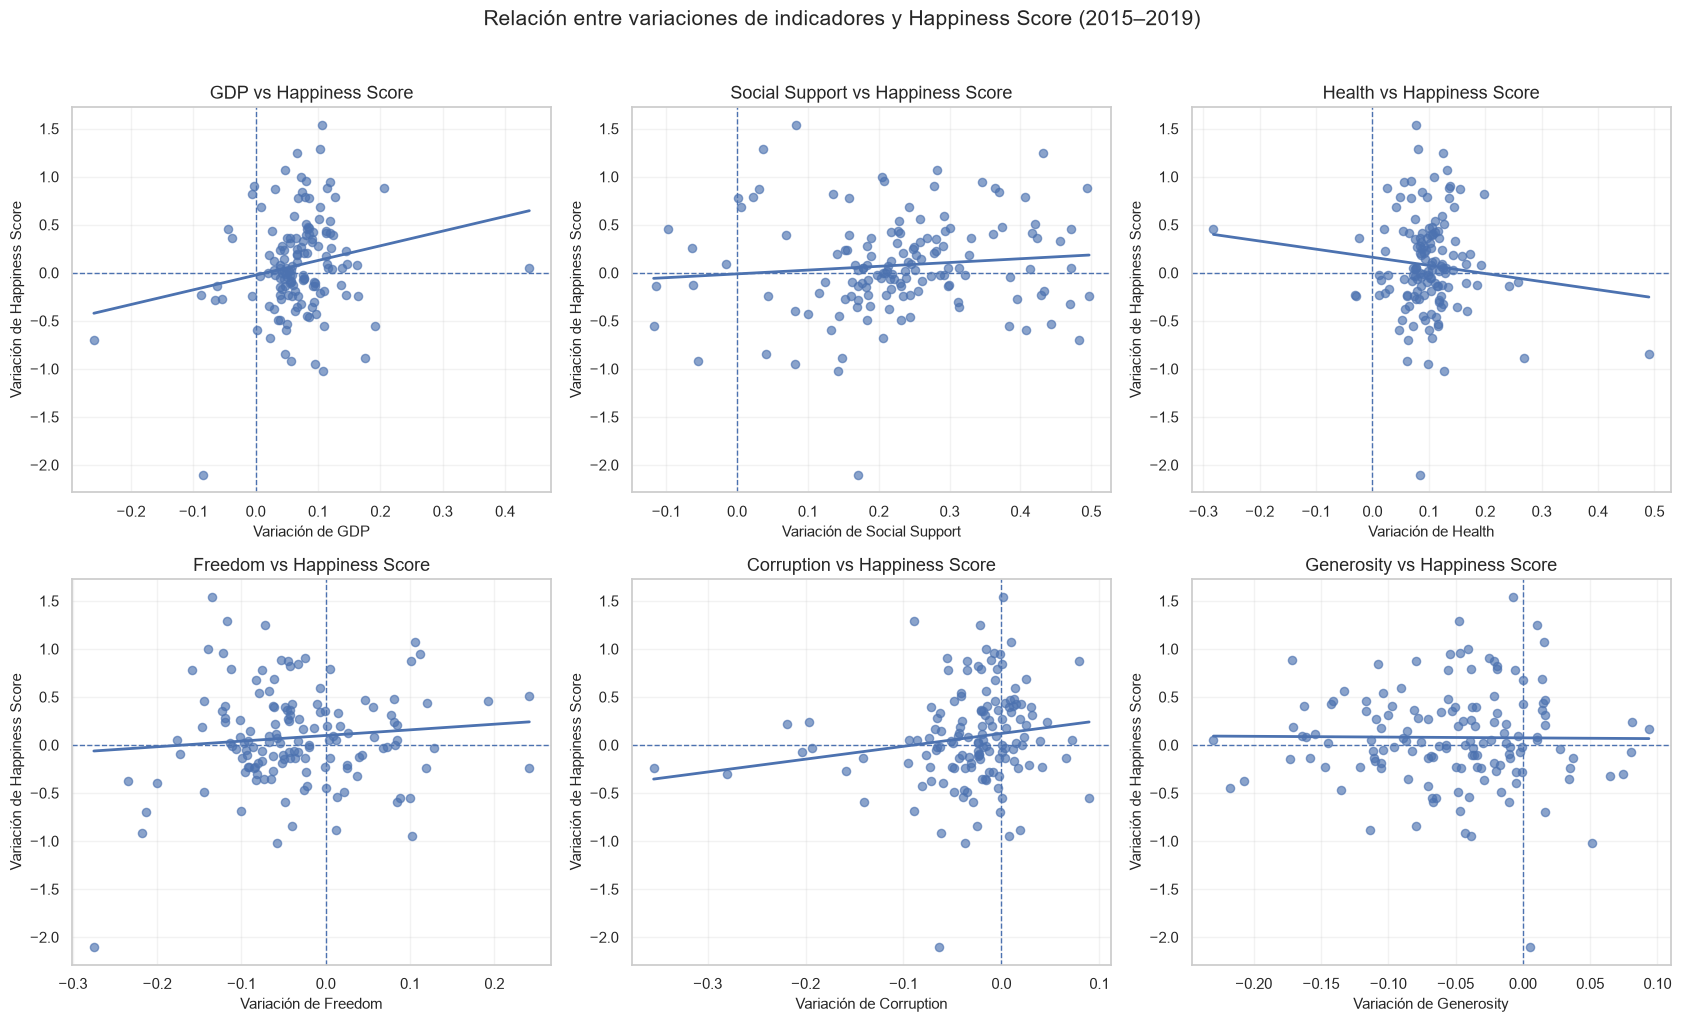

In [127]:
# ============================================================
# 6.4. DISPERSIÓN ENTRE VARIACIONES POR PAÍS
# ============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(17, 10)
)

axes = axes.flatten()

for i, indicador in enumerate(INDICADORES_VARIACION):

    columna_x = f"delta_{indicador}"
    columna_y = "delta_happiness_score"

    ax = axes[i]

    sns.regplot(
        data=df_variaciones,
        x=columna_x,
        y=columna_y,
        ax=ax,
        scatter_kws={"alpha": 0.65, "s": 35},
        line_kws={"linewidth": 2},
        ci=None
    )

    # Líneas de referencia en cero
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.axvline(0, linestyle="--", linewidth=1)

    ax.set_title(f"{indicador} vs Happiness Score")
    ax.set_xlabel(f"Variación de {indicador}")
    ax.set_ylabel("Variación de Happiness Score")
    ax.grid(True, alpha=0.25)

plt.suptitle(
    "Relación entre variaciones de indicadores y Happiness Score (2015–2019)",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

### Conclusión general

Los resultados muestran que las relaciones observadas entre los niveles de los indicadores y Happiness Score no necesariamente se mantienen cuando se analizan sus variaciones temporales. Aunque GDP, Social Support y Health registraron aumentos conjuntos con mayor frecuencia, las correlaciones entre sus cambios y los cambios en Happiness Score fueron débiles.

Por consiguiente, no podemos afirmar que el incremento de un indicador produzca necesariamente un aumento de la felicidad. Los resultados describen asociaciones observadas en el panel de 141 países durante 2015–2019, dentro de las definiciones y metodologías de las ediciones del World Happiness Report utilizadas.

### 7.1. Construcción de rankings anuales

Se construirán rankings anuales utilizando Happiness Score para los 141 países del panel común. Los países se ordenarán de mayor a menor puntaje, asignando la posición 1 al país con mayor felicidad y la posición 141 al de menor puntuación.

In [128]:
# ============================================================
# 7.1. CONSTRUCCIÓN DE RANKINGS ANUALES
# ============================================================

# Crear copia del panel longitudinal
df_rankings = df_panel.copy()

# Asignar posiciones anuales según Happiness Score
# Mayor puntaje = mejor posición (ranking 1)
df_rankings["ranking"] = (
    df_rankings
    .groupby("year")["happiness_score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

# Ordenar por año y posición
df_rankings = df_rankings.sort_values(
    by=["year", "ranking"]
).reset_index(drop=True)

# Validar cantidad de países por año
print("PAÍSES POR AÑO")
display(
    df_rankings.groupby("year")["country_normalizado"]
    .nunique()
)

# Mostrar los cinco primeros países de cada año
for year in YEARS:

    print(f"\nTOP 5 - {year}")

    display(
        df_rankings[
            df_rankings["year"] == year
        ][["country", "happiness_score", "ranking"]]
        .head(5)
    )

# Mostrar los cinco últimos países de cada año
for year in YEARS:

    print(f"\nBOTTOM 5 - {year}")

    display(
        df_rankings[
            df_rankings["year"] == year
        ][["country", "happiness_score", "ranking"]]
        .tail(5)
    )

PAÍSES POR AÑO


year
2015    141
2016    141
2017    141
2018    141
2019    141
Name: country_normalizado, dtype: int64


TOP 5 - 2015


,country,happiness_score,ranking
0,Switzerland,7.587,1
1,Iceland,7.561,2
2,Denmark,7.527,3
3,Norway,7.522,4
4,Canada,7.427,5



TOP 5 - 2016


,country,happiness_score,ranking
141,Denmark,7.526,1
142,Switzerland,7.509,2
143,Iceland,7.501,3
144,Norway,7.498,4
145,Finland,7.413,5


... (12 outputs left out)


BOTTOM 5 - 2018


,country,happiness_score,ranking
559,Syria,3.462,137
560,Rwanda,3.408,138
561,Yemen,3.355,139
562,Tanzania,3.303,140
563,Burundi,2.905,141



BOTTOM 5 - 2019


,country,happiness_score,ranking
700,Malawi,3.410,137
701,Yemen,3.380,138
702,Rwanda,3.334,139
703,Tanzania,3.231,140
704,Afghanistan,3.203,141


### 7.2. Correlación y estabilidad de los rankings

Se calculará la correlación de Spearman entre los rankings de los 141 países para cada par de años. Los resultados permitirán evaluar la estabilidad de las posiciones relativas durante el periodo 2015–2019.

Una correlación cercana a 1 representa una elevada conservación del orden relativo; una correlación cercana a 0 indica una menor asociación entre las posiciones.

MATRIZ DE CORRELACIONES DE SPEARMAN


year,2015,2016,2017,2018,2019
year,,,,,
2015,1.000,0.982,0.959,0.937,0.913
2016,0.982,1.000,0.988,0.964,0.933
2017,0.959,0.988,1.000,0.985,0.956
2018,0.937,0.964,0.985,1.000,0.982
2019,0.913,0.933,0.956,0.982,1.000



CORRELACIÓN ENTRE PARES DE AÑOS


,periodo,correlacion_spearman
0,2016-2017,0.988
1,2017-2018,0.985
2,2018-2019,0.982
3,2015-2016,0.982
4,2016-2018,0.964
5,2015-2017,0.959
6,2017-2019,0.956
7,2015-2018,0.937
8,2016-2019,0.933
9,2015-2019,0.913


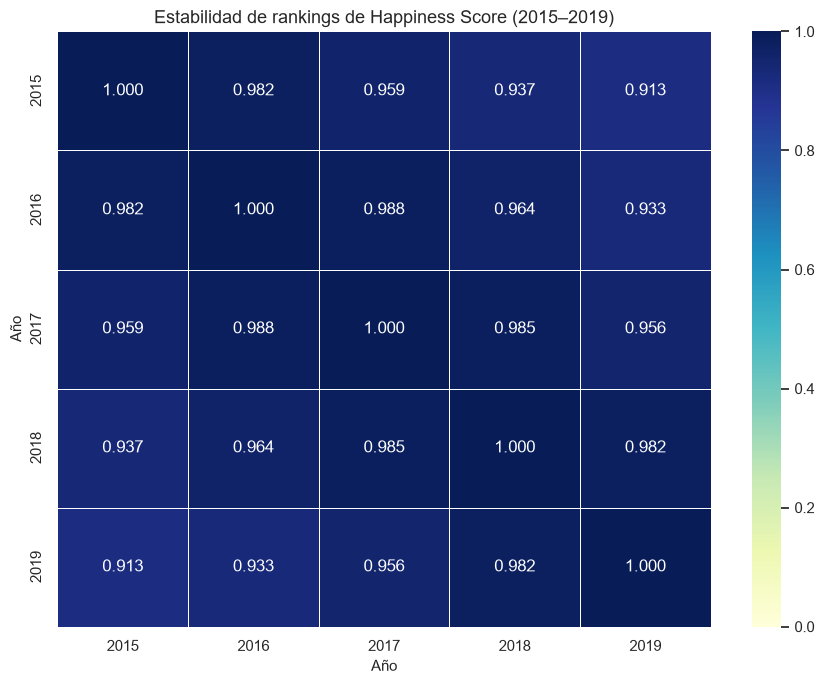

In [129]:
# ============================================================
# 7.2. CORRELACIÓN Y ESTABILIDAD DE LOS RANKINGS
# ============================================================

# Construir matriz de rankings:
# Filas = países | Columnas = años
matriz_rankings = (
    df_rankings
    .pivot(
        index="country_normalizado",
        columns="year",
        values="ranking"
    )
)

# Calcular correlaciones de Spearman entre años
correlaciones_rankings = matriz_rankings.corr(
    method="spearman"
)

print("MATRIZ DE CORRELACIONES DE SPEARMAN")
display(correlaciones_rankings.round(3))

# Extraer correlaciones entre pares de años
resultados_estabilidad = []

for i, year_inicial in enumerate(YEARS):
    for year_final in YEARS[i + 1:]:

        correlacion = correlaciones_rankings.loc[
            year_inicial,
            year_final
        ]

        resultados_estabilidad.append({
            "periodo": f"{year_inicial}-{year_final}",
            "correlacion_spearman": correlacion
        })

df_estabilidad_rankings = (
    pd.DataFrame(resultados_estabilidad)
    .sort_values(
        "correlacion_spearman",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nCORRELACIÓN ENTRE PARES DE AÑOS")
display(df_estabilidad_rankings.round(3))

# Visualizar matriz de correlaciones
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlaciones_rankings,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5
)

plt.title("Estabilidad de rankings de Happiness Score (2015–2019)")
plt.xlabel("Año")
plt.ylabel("Año")
plt.tight_layout()
plt.show()

### 7.3. Movimientos de posición entre 2015 y 2019

Se comparan los rankings de los 141 países presentes en las cinco ediciones para identificar los mayores ascensos y descensos entre 2015 y 2019.

La variación se calcula restando el ranking de 2019 al de 2015. Por tanto, los valores positivos representan mejoras de posición y los negativos representan retrocesos.

TOP 10 - MAYORES ASCENSOS EN EL RANKING (2015-2019)


,country,2015,2019,cambio_posicion
0,Benin,138,97,41
1,Ivory Coast,134,94,40
2,Honduras,93,57,36
3,Romania,80,46,34
4,Hungary,92,60,32
5,Latvia,83,51,32
6,Bulgaria,120,92,28
7,Burkina Faso,135,107,28
8,Cameroon,119,91,28
9,Gabon,127,99,28



TOP 10 - MAYORES DESCENSOS EN EL RANKING (2015-2019)


,country,2015,2019,cambio_posicion
140,Venezuela,22,102,-80
139,Zambia,79,127,-48
138,Zimbabwe,103,133,-30
137,Haiti,106,134,-28
136,Liberia,104,130,-26
134,Ukraine,99,123,-24
135,India,105,129,-24
133,Belarus,55,77,-22
132,Botswana,114,135,-21
131,Vietnam,69,89,-20



RESUMEN DE MOVIMIENTOS


,cambio_posicion
count,141.00
mean,0.00
std,17.02
min,-80.00
25%,-10.00
50%,0.00
75%,10.00
max,41.00



CLASIFICACIÓN DE LOS MOVIMIENTOS


,cantidad
Mejoraron su posición,70
Perdieron posiciones,67
Sin cambio,4


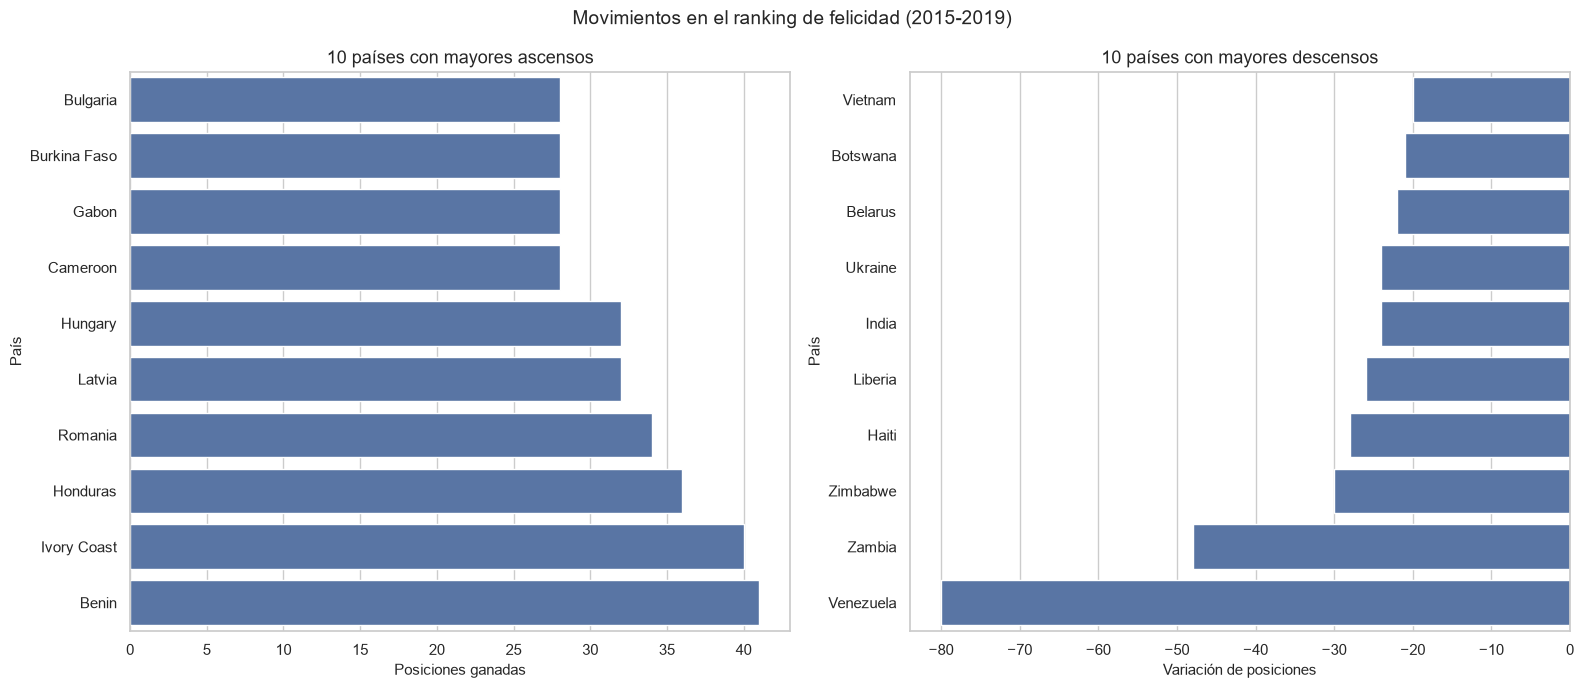

In [130]:
# ============================================================
# 7.3. MOVIMIENTOS DE POSICIÓN ENTRE 2015 Y 2019
# ============================================================

# Construir matriz de rankings por país y año
matriz_movimientos = (
    df_rankings
    .pivot(
        index="country_normalizado",
        columns="year",
        values="ranking"
    )
)

# Calcular variación de posición
df_movimientos = matriz_movimientos[[2015, 2019]].copy()

df_movimientos["cambio_posicion"] = (
    df_movimientos[2015] - df_movimientos[2019]
)

# Incorporar nombres de países
nombres_paises = (
    df_rankings[df_rankings["year"] == 2019]
    [["country_normalizado", "country"]]
    .drop_duplicates("country_normalizado")
    .set_index("country_normalizado")
)

df_movimientos = (
    df_movimientos
    .join(nombres_paises)
    .reset_index()
)

# Ordenar resultados
df_movimientos = df_movimientos.sort_values(
    "cambio_posicion",
    ascending=False
).reset_index(drop=True)

# Mostrar mayores ascensos
print("TOP 10 - MAYORES ASCENSOS EN EL RANKING (2015-2019)")

display(
    df_movimientos[
        ["country", 2015, 2019, "cambio_posicion"]
    ].head(10)
)

# Mostrar mayores descensos
print("\nTOP 10 - MAYORES DESCENSOS EN EL RANKING (2015-2019)")

display(
    df_movimientos[
        ["country", 2015, 2019, "cambio_posicion"]
    ].tail(10).sort_values("cambio_posicion")
)

# Resumen de movimientos
print("\nRESUMEN DE MOVIMIENTOS")

display(
    df_movimientos["cambio_posicion"]
    .describe()
    .to_frame("cambio_posicion")
    .round(2)
)

print("\nCLASIFICACIÓN DE LOS MOVIMIENTOS")

clasificacion_movimientos = pd.Series({
    "Mejoraron su posición": (
        df_movimientos["cambio_posicion"] > 0
    ).sum(),
    "Perdieron posiciones": (
        df_movimientos["cambio_posicion"] < 0
    ).sum(),
    "Sin cambio": (
        df_movimientos["cambio_posicion"] == 0
    ).sum()
})

display(clasificacion_movimientos.to_frame("cantidad"))

# Visualización de los mayores movimientos
mayores_ascensos = df_movimientos.head(10).sort_values(
    "cambio_posicion"
)

mayores_descensos = df_movimientos.tail(10).sort_values(
    "cambio_posicion",
    ascending=False
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=mayores_ascensos,
    x="cambio_posicion",
    y="country",
    ax=axes[0]
)

axes[0].set_title("10 países con mayores ascensos")
axes[0].set_xlabel("Posiciones ganadas")
axes[0].set_ylabel("País")

sns.barplot(
    data=mayores_descensos,
    x="cambio_posicion",
    y="country",
    ax=axes[1]
)

axes[1].set_title("10 países con mayores descensos")
axes[1].set_xlabel("Variación de posiciones")
axes[1].set_ylabel("País")

plt.suptitle(
    "Movimientos en el ranking de felicidad (2015-2019)",
    fontsize=14
)

plt.tight_layout()
plt.show()

### Conclusión general

El análisis confirma una elevada persistencia de los rankings de felicidad entre 2015 y 2019, con correlaciones de Spearman superiores a 0.91. Sin embargo, esta estabilidad general no significa que todos los países mantengan sus posiciones. Se identifican movimientos importantes, como los ascensos de Benin e Ivory Coast y el descenso de Venezuela.

En conjunto, los resultados muestran dos comportamientos simultáneos: una estructura internacional relativamente estable en la distribución de la felicidad y cambios significativos en la posición relativa de determinados paíse

## 8. Trayectorias individuales

Este bloque analiza la evolución del Happiness Score de países seleccionados entre 2015 y 2019.

Se establecen tres grupos:
- Países con mejoras destacadas.
- Países con deterioros destacados.
- Países con posiciones relativamente estables.

Se utilizará el panel común de 141 países para garantizar la comparabilidad temporal.

In [131]:
# ============================================================
# 8.1. SELECCIÓN DE PAÍSES Y CONSTRUCCIÓN DE TRAYECTORIAS
# ============================================================

# Definir grupos de análisis
grupos_paises = {
    "Mejoras destacadas": [
        "Benin",
        "Ivory Coast",
        "Honduras",
        "Romania"
    ],
    "Deterioros destacados": [
        "Venezuela",
        "Zambia",
        "Zimbabwe",
        "Haiti"
    ],
    "Posiciones relativamente estables": [
        "Finland",
        "Denmark",
        "Norway",
        "Iceland"
    ]
}

# Construir tabla de países seleccionados
seleccion_paises = []

for grupo, paises in grupos_paises.items():
    for pais in paises:
        seleccion_paises.append({
            "grupo": grupo,
            "country": pais
        })

df_seleccion = pd.DataFrame(seleccion_paises)

# Filtrar el panel común
df_trayectorias = df_panel[
    df_panel["country"].isin(df_seleccion["country"])
].copy()

# Incorporar grupo de análisis
df_trayectorias = df_trayectorias.merge(
    df_seleccion,
    on="country",
    how="left"
)

# Ordenar resultados
df_trayectorias = df_trayectorias.sort_values(
    ["grupo", "country", "year"]
).reset_index(drop=True)

# Validar selección
print("PAÍSES SELECCIONADOS POR GRUPO")

display(
    df_seleccion.groupby("grupo")["country"]
    .apply(list)
    .to_frame("países")
)

print("\nCANTIDAD DE REGISTROS POR GRUPO Y AÑO")

display(
    df_trayectorias.groupby(["grupo", "year"])
    .size()
    .unstack()
)

print("\nDIMENSIONES DEL DATASET")

print(df_trayectorias.shape)

# Mostrar datos seleccionados
display(
    df_trayectorias[
        ["grupo", "country", "year", "happiness_score"]
    ].head(20)
)

PAÍSES SELECCIONADOS POR GRUPO


,países
grupo,
Deterioros destacados,"[Venezuela, Zambia, Zimbabwe, Haiti]"
Mejoras destacadas,"[Benin, Ivory Coast, Honduras, Romania]"
Posiciones relativamente estables,"[Finland, Denmark, Norway, Iceland]"



CANTIDAD DE REGISTROS POR GRUPO Y AÑO


year,2015,2016,2017,2018,2019
grupo,,,,,
Deterioros destacados,4,4,4,4,4
Mejoras destacadas,4,4,4,4,4
Posiciones relativamente estables,4,4,4,4,4



DIMENSIONES DEL DATASET
(60, 5)


,grupo,country,year,happiness_score
0,Deterioros destacados,Haiti,2015,4.518
1,Deterioros destacados,Haiti,2016,4.028
2,Deterioros destacados,Haiti,2017,3.603
3,Deterioros destacados,Haiti,2018,3.582
4,Deterioros destacados,Haiti,2019,3.597
5,Deterioros destacados,Venezuela,2015,6.810
6,Deterioros destacados,Venezuela,2016,6.084
7,Deterioros destacados,Venezuela,2017,5.250
8,Deterioros destacados,Venezuela,2018,4.806
9,Deterioros destacados,Venezuela,2019,4.707


### 8.2. Evolución del Happiness Score por grupo

Se visualizará la evolución del Happiness Score de los 12 países seleccionados entre 2015 y 2019.

Se utilizarán tres gráficos independientes, uno por grupo, para facilitar la comparación de las trayectorias individuales y reconocer tendencias, fluctuaciones y posibles cambios de dirección.

Se mantendrá la misma escala vertical en los tres gráficos para permitir una comparación visual consistente.

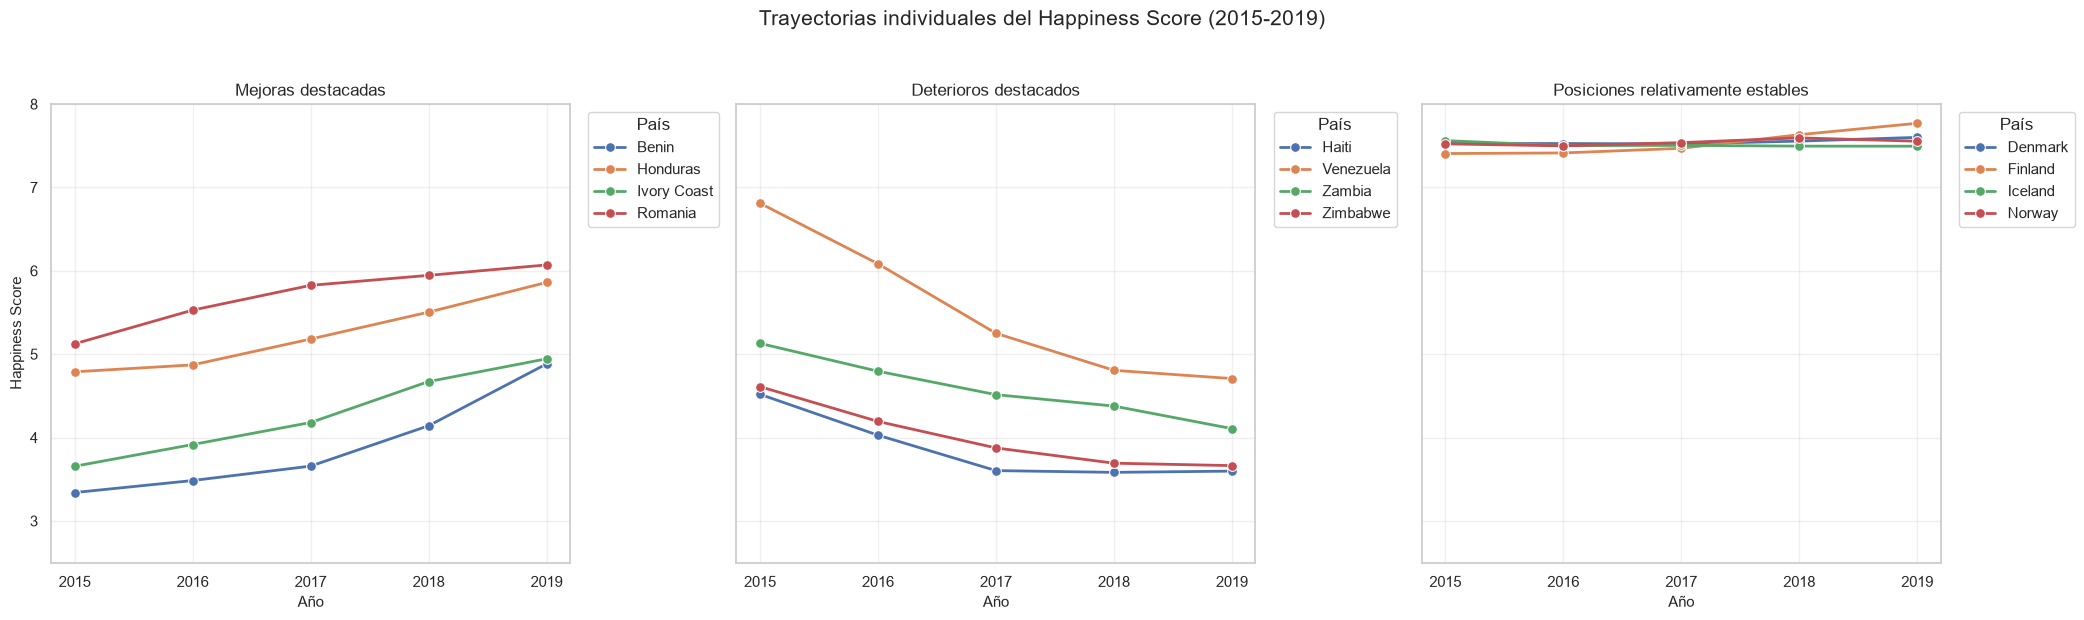

In [132]:
# ============================================================
# 8.2. VISUALIZACIÓN DE TRAYECTORIAS INDIVIDUALES
# ============================================================

orden_grupos = [
    "Mejoras destacadas",
    "Deterioros destacados",
    "Posiciones relativamente estables"
]

fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharey=True)

for ax, grupo in zip(axes, orden_grupos):

    datos_grupo = df_trayectorias[
        df_trayectorias["grupo"] == grupo
    ]

    sns.lineplot(
        data=datos_grupo,
        x="year",
        y="happiness_score",
        hue="country",
        marker="o",
        linewidth=2,
        markersize=7,
        ax=ax
    )

    ax.set_title(grupo, fontsize=12)
    ax.set_xlabel("Año")
    ax.set_ylabel("Happiness Score")
    ax.set_xticks(YEARS)
    ax.grid(True, alpha=0.3)
    ax.legend(
        title="País",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

plt.suptitle(
    "Trayectorias individuales del Happiness Score (2015-2019)",
    fontsize=15,
    y=1.03
)

plt.ylim(2.5, 8)
plt.tight_layout()
plt.show()

### 8.3. Variaciones interanuales por país

Se calculará la diferencia del Happiness Score entre años consecutivos para cada país seleccionado.

El análisis permitirá:
- Identificar los mayores incrementos y disminuciones anuales.
- Comparar la magnitud de los cambios entre los tres grupos.
- Reconocer los años en los que se concentraron las principales variaciones.

Una variación positiva representa un incremento del Happiness Score y una negativa representa una disminución.

VARIACIONES INTERANUALES POR PAÍS


,grupo,country,periodo,variacion_anual
21,Mejoras destacadas,Benin,2015-2016,0.144
22,Mejoras destacadas,Benin,2016-2017,0.173
23,Mejoras destacadas,Benin,2017-2018,0.484
24,Mejoras destacadas,Benin,2018-2019,0.742
41,Posiciones relativamente estables,Denmark,2015-2016,-0.001
42,Posiciones relativamente estables,Denmark,2016-2017,-0.004
43,Posiciones relativamente estables,Denmark,2017-2018,0.033
44,Posiciones relativamente estables,Denmark,2018-2019,0.045
46,Posiciones relativamente estables,Finland,2015-2016,0.007
47,Posiciones relativamente estables,Finland,2016-2017,0.056



PROMEDIO DE VARIACIONES POR GRUPO Y PERIODO


mean  median    min    max  \
grupo                             periodo                                  
Deterioros destacados             2015-2016 -0.492  -0.454 -0.726 -0.334   
                                  2016-2017 -0.465  -0.372 -0.834 -0.281   
                                  2017-2018 -0.196  -0.160 -0.444 -0.021   
                                  2018-2019 -0.096  -0.064 -0.270  0.015   
Mejoras destacadas                2015-2016  0.223   0.203  0.083  0.404   
                                  2016-2017  0.261   0.280  0.173  0.310   
                                  2017-2018  0.355   0.403  0.120  0.491   
                                  2018-2019  0.374   0.315  0.125  0.742   
Posiciones relativamente estables 2015-2016 -0.019  -0.013 -0.060  0.007   
                                  2016-2017  0.024   0.021 -0.004  0.056   
                                  2017-2018  0.061   0.045 -0.009  0.163   
                                  2018-2019  0.035   0.022 -0.040  0.137   

                                               std  
grupo                             periodo           
Deterioros destacados             2015-2016  0.169  
                                  2016-2017  0.254  
                                  2017-2018  0.179  
                                  2018-2019  0.125  
Mejoras destacadas                2015-2016  0.141  
                                  2016-2017  0.062  
                                  2017-2018  0.175  
                                  2018-2019  0.263  
Posiciones relativamente estables 2015-2016  0.030  
                                  2016-2017  0.029  
                                  2017-2018  0.073  
                                  2018-2019  0.076


MAYORES INCREMENTOS INTERANUALES


,country,grupo,periodo,variacion_anual
24,Benin,Mejoras destacadas,2018-2019,0.742
33,Ivory Coast,Mejoras destacadas,2017-2018,0.491
23,Benin,Mejoras destacadas,2017-2018,0.484
36,Romania,Mejoras destacadas,2015-2016,0.404
29,Honduras,Mejoras destacadas,2018-2019,0.356
28,Honduras,Mejoras destacadas,2017-2018,0.323
27,Honduras,Mejoras destacadas,2016-2017,0.310
37,Romania,Mejoras destacadas,2016-2017,0.297
34,Ivory Coast,Mejoras destacadas,2018-2019,0.273
32,Ivory Coast,Mejoras destacadas,2016-2017,0.264



MAYORES DISMINUCIONES INTERANUALES


,country,grupo,periodo,variacion_anual
7,Venezuela,Deterioros destacados,2016-2017,-0.834
6,Venezuela,Deterioros destacados,2015-2016,-0.726
1,Haiti,Deterioros destacados,2015-2016,-0.490
8,Venezuela,Deterioros destacados,2017-2018,-0.444
2,Haiti,Deterioros destacados,2016-2017,-0.425
16,Zimbabwe,Deterioros destacados,2015-2016,-0.417
11,Zambia,Deterioros destacados,2015-2016,-0.334
17,Zimbabwe,Deterioros destacados,2016-2017,-0.318
12,Zambia,Deterioros destacados,2016-2017,-0.281
14,Zambia,Deterioros destacados,2018-2019,-0.270


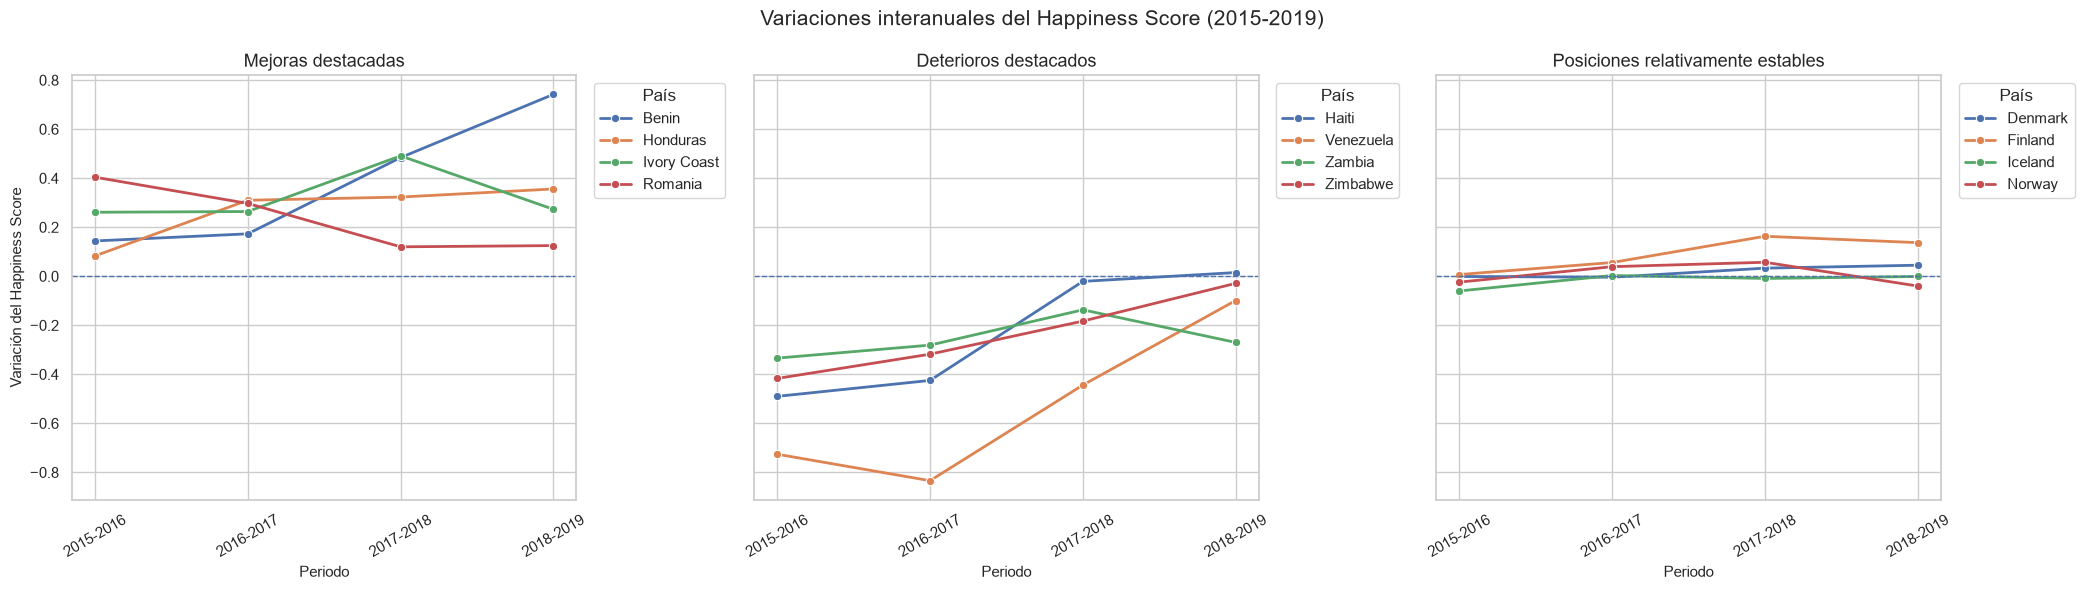

In [133]:
# ============================================================
# 8.3. VARIACIONES INTERANUALES POR PAÍS
# ============================================================

# Ordenar registros para calcular diferencias temporales
df_variaciones_trayectorias = df_trayectorias.sort_values(
    ["country", "year"]
).copy()

# Calcular variación respecto al año anterior
df_variaciones_trayectorias["variacion_anual"] = (
    df_variaciones_trayectorias
    .groupby("country")["happiness_score"]
    .diff()
)

# Eliminar 2015 porque no tiene año anterior dentro del periodo
df_variaciones_trayectorias = (
    df_variaciones_trayectorias
    .dropna(subset=["variacion_anual"])
    .copy()
)

# Crear identificador del periodo
df_variaciones_trayectorias["periodo"] = (
    df_variaciones_trayectorias["year"].astype(str)
    .replace({
        "2016": "2015-2016",
        "2017": "2016-2017",
        "2018": "2017-2018",
        "2019": "2018-2019"
    })
)

# ------------------------------------------------------------
# 1. Variaciones individuales
# ------------------------------------------------------------

print("VARIACIONES INTERANUALES POR PAÍS")

display(
    df_variaciones_trayectorias[
        ["grupo", "country", "periodo", "variacion_anual"]
    ].round(3)
)

# ------------------------------------------------------------
# 2. Resumen por grupo y periodo
# ------------------------------------------------------------

print("\nPROMEDIO DE VARIACIONES POR GRUPO Y PERIODO")

resumen_variaciones = (
    df_variaciones_trayectorias
    .groupby(["grupo", "periodo"])["variacion_anual"]
    .agg(["mean", "median", "min", "max", "std"])
    .round(3)
)

display(resumen_variaciones)

# ------------------------------------------------------------
# 3. Mayores incrementos y disminuciones
# ------------------------------------------------------------

print("\nMAYORES INCREMENTOS INTERANUALES")

display(
    df_variaciones_trayectorias
    .nlargest(10, "variacion_anual")[
        ["country", "grupo", "periodo", "variacion_anual"]
    ]
    .round(3)
)

print("\nMAYORES DISMINUCIONES INTERANUALES")

display(
    df_variaciones_trayectorias
    .nsmallest(10, "variacion_anual")[
        ["country", "grupo", "periodo", "variacion_anual"]
    ]
    .round(3)
)

# ------------------------------------------------------------
# 4. Visualización de variaciones interanuales
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(21, 6), sharey=True)

for ax, grupo in zip(axes, orden_grupos):

    datos_grupo = df_variaciones_trayectorias[
        df_variaciones_trayectorias["grupo"] == grupo
    ]

    sns.lineplot(
        data=datos_grupo,
        x="periodo",
        y="variacion_anual",
        hue="country",
        marker="o",
        linewidth=2,
        markersize=6,
        ax=ax
    )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(grupo)
    ax.set_xlabel("Periodo")
    ax.set_ylabel("Variación del Happiness Score")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(
        title="País",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

plt.suptitle(
    "Variaciones interanuales del Happiness Score (2015-2019)",
    fontsize=15
)

plt.tight_layout()
plt.show()

### Conclusión general

El análisis confirma una elevada persistencia de los rankings de felicidad entre 2015 y 2019, con correlaciones de Spearman superiores a 0.91. Sin embargo, esta estabilidad general no significa que todos los países mantengan sus posiciones. Se identifican movimientos importantes, como los ascensos de Benin e Ivory Coast y el descenso de Venezuela.

En conjunto, los resultados muestran dos comportamientos simultáneos: una estructura internacional relativamente estable en la distribución de la felicidad y cambios significativos en la posición relativa de determinados paíse

### 9.1. Inspección de la información regional

Se revisará la estructura de los cinco datasets originales para identificar:
- Las columnas que contienen el país y la región.
- Los años en los que existe información regional explícita.
- Las regiones identificadas en cada edición.
- Posibles diferencias en la clasificación regional entre años.

Esta revisión permitirá determinar cómo construir una clasificación regional consistente para el periodo 2015-2019.

In [134]:
# ============================================================
# 9.1. INSPECCIÓN DE LA INFORMACIÓN REGIONAL
# ============================================================

# Identificar columnas relacionadas con país y región
for year, df in datasets.items():

    print(f"\n{'=' * 55}")
    print(f"EDICIÓN {year}")
    print(f"{'=' * 55}")

    columnas = df.columns.tolist()

    columnas_pais = [
        col for col in columnas
        if "country" in col.lower()
    ]

    columnas_region = [
        col for col in columnas
        if "region" in col.lower()
    ]

    print("Columnas de país:", columnas_pais)
    print("Columnas de región:", columnas_region)

    if columnas_region:

        for columna in columnas_region:

            print(f"\nDistribución de {columna}:")

            display(
                df[columna]
                .value_counts(dropna=False)
                .to_frame("cantidad")
            )

    else:
        print("No se encontró una columna regional explícita.")

# ------------------------------------------------------------
# Resumen de cobertura regional
# ------------------------------------------------------------

resumen_regiones = []

for year, df in datasets.items():

    columnas_region = [
        col for col in df.columns
        if "region" in col.lower()
    ]

    resumen_regiones.append({
        "year": year,
        "tiene_region": len(columnas_region) > 0,
        "columna_region": (
            columnas_region[0]
            if columnas_region else None
        ),
        "regiones_distintas": (
            df[columnas_region[0]].nunique()
            if columnas_region else 0
        )
    })

df_resumen_regiones = pd.DataFrame(resumen_regiones)

print("\nRESUMEN DE DISPONIBILIDAD REGIONAL")

display(df_resumen_regiones)


EDICIÓN 2015
Columnas de país: ['Country']
Columnas de región: ['Region']

Distribución de Region:


,cantidad
Region,
Sub-Saharan Africa,40
Central and Eastern Europe,29
Latin America and Caribbean,22
Western Europe,21
Middle East and Northern Africa,20
Southeastern Asia,9
Southern Asia,7
Eastern Asia,6
North America,2



EDICIÓN 2016
Columnas de país: ['Country']
Columnas de región: ['Region']

Distribución de Region:


,cantidad
Region,
Sub-Saharan Africa,38
Central and Eastern Europe,29
Latin America and Caribbean,24
Western Europe,21
Middle East and Northern Africa,19
Southeastern Asia,9
Southern Asia,7
Eastern Asia,6
North America,2



EDICIÓN 2017
Columnas de país: ['Country']
Columnas de región: []
No se encontró una columna regional explícita.

EDICIÓN 2018
Columnas de país: ['Country or region']
Columnas de región: ['Country or region']

Distribución de Country or region:


,cantidad
Country or region,
Finland,1
Norway,1
Denmark,1
Iceland,1
Switzerland,1
...,...
Yemen,1
Tanzania,1
South Sudan,1



EDICIÓN 2019
Columnas de país: ['Country or region']
Columnas de región: ['Country or region']

Distribución de Country or region:


,cantidad
Country or region,
Finland,1
Denmark,1
Norway,1
Iceland,1
Netherlands,1
...,...
Rwanda,1
Tanzania,1
Afghanistan,1



RESUMEN DE DISPONIBILIDAD REGIONAL


,year,tiene_region,columna_region,regiones_distintas
0,2015,True,Region,10
1,2016,True,Region,10
2,2017,False,NaN,0
3,2018,True,Country or region,156
4,2019,True,Country or region,156


### 9.2. Construcción de la correspondencia país-región

Se utilizarán las ediciones de 2015 y 2016 para construir una clasificación regional común.

Primero se normalizarán los nombres de los países para facilitar su correspondencia. Después se comprobará que cada país tenga la misma región en ambas ediciones cuando aparezca en las dos.

Finalmente, se incorporará la clasificación regional al panel común de 141 países y se identificarán los registros que no puedan asociarse.

In [135]:
# ============================================================
# 9.2. CONSTRUCCIÓN Y VALIDACIÓN DE LA CORRESPONDENCIA
# ============================================================

import re
import unicodedata

# ------------------------------------------------------------
# 1. Función para normalizar nombres de países
# ------------------------------------------------------------

def normalizar_pais(nombre):

    nombre = str(nombre).strip().lower()

    # Eliminar tildes y caracteres diacríticos
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        caracter for caracter in nombre
        if not unicodedata.combining(caracter)
    )

    # Sustituir puntuación por espacios
    nombre = re.sub(r"[^a-z0-9]+", " ", nombre)

    return " ".join(nombre.split())


# ------------------------------------------------------------
# 2. Extraer países y regiones de 2015 y 2016
# ------------------------------------------------------------

registros_regionales = []

for year in [2015, 2016]:

    df = datasets[year]

    # Identificar columnas
    columna_pais = next(
        col for col in df.columns
        if col.lower() in ["country", "country or region"]
    )

    columna_region = next(
        col for col in df.columns
        if col.lower() == "region"
    )

    temporal = df[[columna_pais, columna_region]].copy()

    temporal.columns = ["country", "region"]

    temporal["year"] = year

    temporal["country_normalizado"] = (
        temporal["country"].apply(normalizar_pais)
    )

    registros_regionales.append(temporal)


df_regiones_fuente = pd.concat(
    registros_regionales,
    ignore_index=True
)

# ------------------------------------------------------------
# 3. Validar asignaciones regionales
# ------------------------------------------------------------

print("ASIGNACIONES REGIONALES POR EDICIÓN")

display(
    df_regiones_fuente.groupby("year")["region"]
    .value_counts()
    .to_frame("cantidad")
)

# Países con más de una región asignada
conflictos_regionales = (
    df_regiones_fuente
    .groupby("country_normalizado")["region"]
    .nunique()
)

conflictos_regionales = conflictos_regionales[
    conflictos_regionales > 1
]

print("\nPAÍSES CON ASIGNACIONES REGIONALES CONTRADICTORIAS")

if conflictos_regionales.empty:

    print("No se encontraron conflictos regionales.")

else:

    display(
        df_regiones_fuente[
            df_regiones_fuente["country_normalizado"].isin(
                conflictos_regionales.index
            )
        ].sort_values("country_normalizado")
    )

# ------------------------------------------------------------
# 4. Construir correspondencia país-región
# ------------------------------------------------------------

df_mapa_regiones = (
    df_regiones_fuente
    .groupby("country_normalizado")
    .agg(
        country_referencia=("country", "first"),
        cantidad_regiones=("region", "nunique"),
        region=("region", "first"),
        ediciones=("year", "nunique")
    )
    .reset_index()
)

# Comprobar cobertura de la correspondencia
print("\nRESUMEN DE LA CORRESPONDENCIA")

display(
    df_mapa_regiones["ediciones"]
    .value_counts()
    .sort_index()
    .rename_axis("ediciones_con_region")
    .to_frame("cantidad_paises")
)

# ------------------------------------------------------------
# 5. Aplicar correspondencia al panel común
# ------------------------------------------------------------

df_panel_regional = df_panel.copy()

df_panel_regional["country_normalizado"] = (
    df_panel_regional["country"].apply(normalizar_pais)
)

df_panel_regional = df_panel_regional.merge(
    df_mapa_regiones[
        ["country_normalizado", "region"]
    ],
    on="country_normalizado",
    how="left",
    validate="many_to_one"
)

# ------------------------------------------------------------
# 6. Validar países sin región y cobertura temporal
# ------------------------------------------------------------

paises_sin_region = (
    df_panel_regional[
        df_panel_regional["region"].isna()
    ]["country"]
    .drop_duplicates()
    .sort_values()
)

print("\nPAÍSES DEL PANEL SIN REGIÓN ASIGNADA")

if paises_sin_region.empty:

    print("Todos los países tienen una región asignada.")

else:

    display(paises_sin_region.to_frame("country"))

print("\nCANTIDAD DE PAÍSES POR REGIÓN Y AÑO")

display(
    df_panel_regional
    .groupby(["year", "region"])["country"]
    .nunique()
    .unstack(fill_value=0)
)

print("\nDIMENSIONES DEL PANEL REGIONAL")

print(df_panel_regional.shape)

ASIGNACIONES REGIONALES POR EDICIÓN


cantidad
year region                                   
2015 Sub-Saharan Africa                     40
     Central and Eastern Europe             29
     Latin America and Caribbean            22
     Western Europe                         21
     Middle East and Northern Africa        20
     Southeastern Asia                       9
     Southern Asia                           7
     Eastern Asia                            6
     North America                           2
     Australia and New Zealand               2
2016 Sub-Saharan Africa                     38
     Central and Eastern Europe             29
     Latin America and Caribbean            24
     Western Europe                         21
     Middle East and Northern Africa        19
     Southeastern Asia                       9
     Southern Asia                           7
     Eastern Asia                            6
     North America                           2
     Australia and New Zealand               2


PAÍSES CON ASIGNACIONES REGIONALES CONTRADICTORIAS
No se encontraron conflictos regionales.

RESUMEN DE LA CORRESPONDENCIA


,cantidad_paises
ediciones_con_region,
1,11
2,152



PAÍSES DEL PANEL SIN REGIÓN ASIGNADA
Todos los países tienen una región asignada.

CANTIDAD DE PAÍSES POR REGIÓN Y AÑO


region,Australia and New Zealand,Central and Eastern Europe,Eastern Asia,Latin America and Caribbean,Middle East and Northern Africa,North America,Southeastern Asia,Southern Asia,Sub-Saharan Africa,Western Europe
year,,,,,,,,,,
2015,2,28,4,20,19,2,8,7,31,20
2016,2,28,4,20,19,2,8,7,31,20
2017,2,28,4,20,19,2,8,7,31,20
2018,2,28,4,20,19,2,8,7,31,20
2019,2,28,4,20,19,2,8,7,31,20



DIMENSIONES DEL PANEL REGIONAL
(705, 5)


### 9.3 — Estadísticas de felicidad por región y año

Ahora analizaremos cómo se distribuye el Happiness Score dentro de cada región a lo largo del periodo 2015–2019.

Calcularemos cantidad de países, media, mediana, desviación estándar, mínimo y máximo. Esto nos permitirá observar tanto el nivel promedio de felicidad como la dispersión interna de cada región.

In [136]:
# Estadísticas descriptivas de Happiness Score por región y año

estadisticas_regionales = (
    df_panel_regional
    .groupby(["year", "region"])["happiness_score"]
    .agg(
        cantidad="count",
        media="mean",
        mediana="median",
        desviacion="std",
        minimo="min",
        maximo="max"
    )
    .reset_index()
)

# Ordenar por año y media de felicidad descendente
estadisticas_regionales = estadisticas_regionales.sort_values(
    ["year", "media"],
    ascending=[True, False]
).reset_index(drop=True)

display(
    estadisticas_regionales.round(3)
)

,year,region,cantidad,media,mediana,desviacion,minimo,maximo
0,2015,Australia and New Zealand,2,7.285,7.285,0.001,7.284,7.286
1,2015,North America,2,7.273,7.273,0.218,7.119,7.427
2,2015,Western Europe,20,6.739,6.938,0.813,4.857,7.587
3,2015,Latin America and Caribbean,20,6.137,6.126,0.765,4.518,7.226
4,2015,Eastern Asia,4,5.496,5.562,0.575,4.874,5.987
5,2015,Southeastern Asia,8,5.373,5.380,1.000,3.819,6.798
6,2015,Central and Eastern Europe,28,5.345,5.358,0.577,4.218,6.505
7,2015,Middle East and Northern Africa,19,5.331,5.192,1.076,3.006,7.278
8,2015,Southern Asia,7,4.581,4.565,0.571,3.575,5.253
9,2015,Sub-Saharan Africa,31,4.120,3.995,0.620,2.839,5.477


## 9.4 Evolución temporal de la felicidad por región

Se analiza la evolución del Happiness Score promedio de cada región entre 2015 y 2019 mediante un gráfico de líneas.

Este análisis permite comparar las trayectorias regionales, identificar tendencias de crecimiento o disminución y observar si las diferencias entre regiones se mantienen durante el periodo.

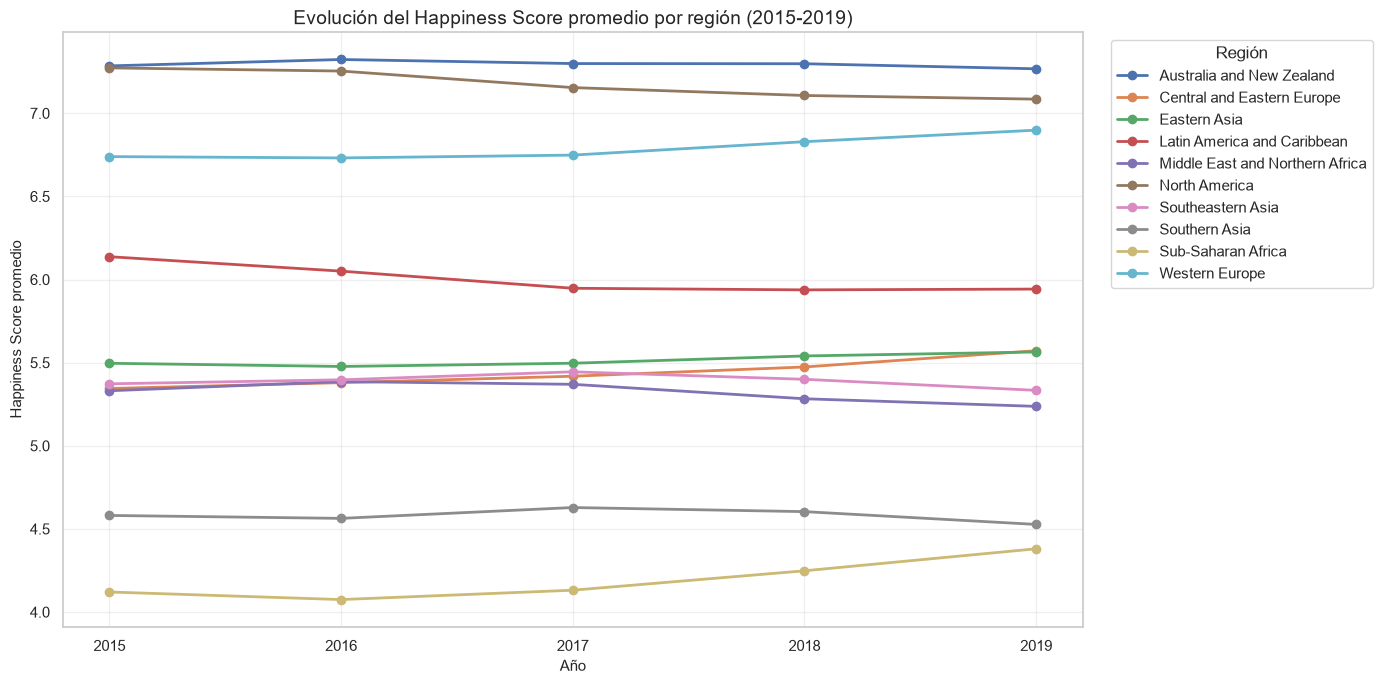

In [137]:
# Preparar datos para la visualización regional

medias_regionales = (
    estadisticas_regionales
    .pivot(
        index="year",
        columns="region",
        values="media"
    )
)

# Visualizar evolución temporal
plt.figure(figsize=(14, 7))

for region in medias_regionales.columns:
    plt.plot(
        medias_regionales.index,
        medias_regionales[region],
        marker="o",
        linewidth=2,
        label=region
    )

plt.title(
    "Evolución del Happiness Score promedio por región (2015-2019)",
    fontsize=14
)
plt.xlabel("Año")
plt.ylabel("Happiness Score promedio")
plt.xticks(YEARS)
plt.legend(
    title="Región",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9.5 Variación del Happiness Score por región (2015–2019)

Se calcula la variación del Happiness Score promedio de cada región entre 2015 y 2019.

El objetivo es identificar las regiones con mayores incrementos y disminuciones, complementando la evolución temporal observada en el gráfico anterior.

In [138]:
# Calcular variación regional entre 2015 y 2019

variacion_regional = (
    medias_regionales.loc[[2015, 2019]]
    .T
    .reset_index()
)

variacion_regional.columns = [
    "region",
    "media_2015",
    "media_2019"
]

variacion_regional["variacion_absoluta"] = (
    variacion_regional["media_2019"]
    - variacion_regional["media_2015"]
)

variacion_regional["variacion_porcentual"] = (
    variacion_regional["variacion_absoluta"]
    / variacion_regional["media_2015"]
) * 100

variacion_regional = variacion_regional.sort_values(
    "variacion_absoluta",
    ascending=False
).reset_index(drop=True)

display(variacion_regional.round(3))

,region,media_2015,media_2019,variacion_absoluta,variacion_porcentual
0,Sub-Saharan Africa,4.120,4.380,0.260,6.308
1,Central and Eastern Europe,5.345,5.572,0.227,4.251
2,Western Europe,6.739,6.898,0.159,2.360
3,Eastern Asia,5.496,5.564,0.068,1.237
4,Australia and New Zealand,7.285,7.268,-0.018,-0.240
5,Southeastern Asia,5.373,5.333,-0.039,-0.731
6,Southern Asia,4.581,4.527,-0.054,-1.179
7,Middle East and Northern Africa,5.331,5.237,-0.094,-1.759
8,North America,7.273,7.085,-0.188,-2.585
9,Latin America and Caribbean,6.137,5.943,-0.195,-3.173


## 9.6 Convergencia y divergencia regional

Se analiza la evolución de las diferencias entre los Happiness Score promedio de las regiones.

Se utilizan el rango entre la región con mayor y menor promedio y la desviación estándar de las medias regionales. Estas medidas permiten evaluar descriptivamente si las diferencias regionales se redujeron o ampliaron entre 2015 y 2019.

,media_minima,media_maxima,desviacion_regional,brecha_regional
year,,,,
2015,4.120,7.285,1.073,3.165
2016,4.075,7.323,1.079,3.249
2017,4.131,7.299,1.038,3.168
2018,4.248,7.298,1.025,3.050
2019,4.380,7.268,1.017,2.887


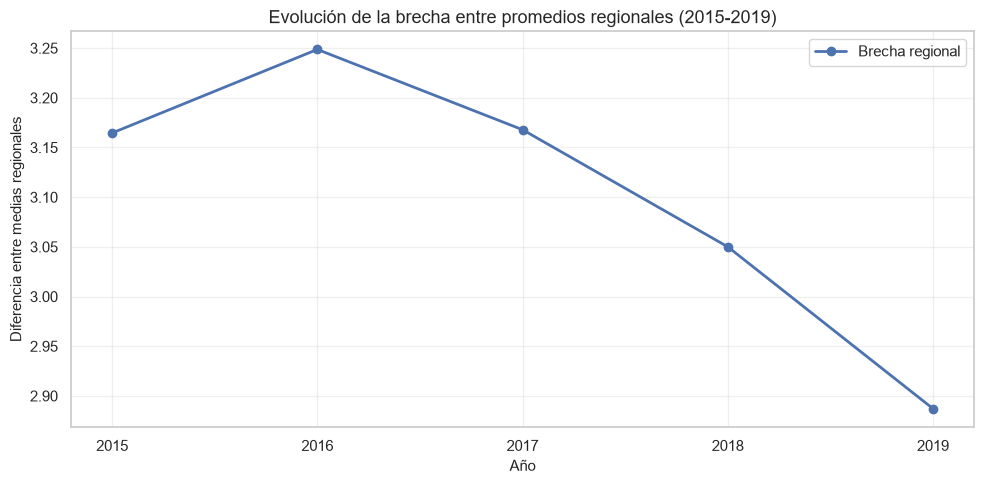

In [139]:
# Calcular dispersión entre los promedios regionales por año

convergencia_regional = (
    medias_regionales
    .agg(["min", "max", "std"], axis=1)
    .rename(columns={
        "min": "media_minima",
        "max": "media_maxima",
        "std": "desviacion_regional"
    })
)

convergencia_regional["brecha_regional"] = (
    convergencia_regional["media_maxima"]
    - convergencia_regional["media_minima"]
)

display(convergencia_regional.round(3))

# Visualizar evolución de la brecha regional

plt.figure(figsize=(10, 5))

plt.plot(
    convergencia_regional.index,
    convergencia_regional["brecha_regional"],
    marker="o",
    linewidth=2,
    label="Brecha regional"
)

plt.title(
    "Evolución de la brecha entre promedios regionales (2015-2019)"
)
plt.xlabel("Año")
plt.ylabel("Diferencia entre medias regionales")
plt.xticks(YEARS)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Conclusion general

Existe una jerarquía regional persistente: Australia and New Zealand, North America y Western Europe mantienen los mayores promedios.



Sub-Saharan Africa presenta el menor promedio, pero también el mayor crecimiento entre 2015 y 2019.



Latin America and Caribbean experimenta el mayor retroceso absoluto.



Las diferencias entre los promedios regionales disminuyen después de 2016.



Se observa una convergencia descriptiva parcial, aunque persisten diferencias importantes entre regiones.